# TEST DATASET │ │ MT-Bench



In [ ]:
# ============================================
# TEST DATASET
# MT-Bench
# ============================================

!wget -q https://raw.githubusercontent.com/lm-sys/FastChat/main/fastchat/llm_judge/data/mt_bench/question.jsonl

print("MT-Bench dataset downloaded successfully.")

MT-Bench dataset downloaded successfully.


In [ ]:
# ============================================
# LOAD MT-BENCH DATASET
# ============================================

import json
import pandas as pd

mt_bench = []

with open(
    "question.jsonl",
    "r",
    encoding="utf-8"
) as f:

    for line in f:
        mt_bench.append(
            json.loads(line)
        )

print(
    "Total MT-Bench questions:",
    len(mt_bench)
)

Total MT-Bench questions: 80


In [ ]:
# ============================================
# INSPECT FIRST QUESTION
# ============================================

print(
    mt_bench[0]
)

{'question_id': 81, 'category': 'writing', 'turns': ['Compose an engaging travel blog post about a recent trip to Hawaii, highlighting cultural experiences and must-see attractions.', 'Rewrite your previous response. Start every sentence with the letter A.']}


In [ ]:
# ============================================
# MT-BENCH DATASET SUMMARY
# ============================================

print("=" * 50)
print("MT-BENCH DATASET SUMMARY")
print("=" * 50)

print(
    "Total Questions:",
    len(mt_bench)
)

print(
    "Unique Categories:",
    len(
        set(
            item["category"]
            for item in mt_bench
        )
    )
)

print(
    "Question IDs:",
    mt_bench[0]["question_id"],
    "→",
    mt_bench[-1]["question_id"]
)

MT-BENCH DATASET SUMMARY
Total Questions: 80
Unique Categories: 8
Question IDs: 81 → 160


In [ ]:
# ============================================
# CATEGORY DISTRIBUTION
# ============================================

category_counts = pd.Series(
    [
        item["category"]
        for item in mt_bench
    ]
).value_counts()

print(
    category_counts
)

writing       10
roleplay      10
reasoning     10
math          10
coding        10
extraction    10
stem          10
humanities    10
Name: count, dtype: int64


In [ ]:
# ============================================
# MT-BENCH DATAFRAME
# ============================================

mt_bench_df = pd.DataFrame(
    mt_bench
)

display(
    mt_bench_df.head()
)

print(
    "DataFrame shape:",
    mt_bench_df.shape
)

,question_id,category,turns,reference
0,81,writing,[Compose an engaging travel blog post about a ...,NaN
1,82,writing,[Draft a professional email seeking your super...,NaN
2,83,writing,[Imagine you are writing a blog post comparing...,NaN
3,84,writing,[Write a persuasive email to convince your int...,NaN
4,85,writing,"[Describe a vivid and unique character, using ...",NaN


DataFrame shape: (80, 4)


In [ ]:
# ============================================
# DATASET VALIDATION
# ============================================

required_fields = [
    "question_id",
    "category",
    "turns"
]

for field in required_fields:

    missing = sum(
        field not in item
        for item in mt_bench
    )

    print(
        f"{field}: "
        f"{'OK' if missing == 0 else f'{missing} missing'}"
    )

print(
    "\nTotal questions:",
    len(mt_bench)
)

print(
    "Expected:",
    80
)

if len(mt_bench) == 80:
    print(
        "Dataset validation: PASSED"
    )
else:
    print(
        "Dataset validation: CHECK REQUIRED"
    )

question_id: OK
category: OK
turns: OK

Total questions: 80
Expected: 80
Dataset validation: PASSED


# TARGET LLM │ │ Qwen 2.5-0.5B-Instruct │

In [ ]:
# ============================================
# TARGET LLM
# Qwen 2.5-0.5B-Instruct
# ============================================

from transformers import pipeline
import torch

target_llm = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device=0 if torch.cuda.is_available() else -1
)

# Avoid max_length conflict
target_llm.model.generation_config.max_length = None

print(
    "Qwen Target LLM loaded successfully!"
)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen Target LLM loaded successfully!


In [ ]:
# ============================================
# TEST TARGET LLM
# ============================================

test_item = mt_bench[0]

question = test_item["turns"][0]

print("Question:")
print(question)

Question:
Compose an engaging travel blog post about a recent trip to Hawaii, highlighting cultural experiences and must-see attractions.


In [ ]:
# ============================================
# GENERATE ONE CANDIDATE ANSWER
# ============================================

prompt = f"""
Answer the following question clearly and accurately.

Question:
{question}

Answer:
"""

result = target_llm(
    prompt,
    max_new_tokens=150,
    do_sample=False
)

generated_text = result[0]["generated_text"]

# Remove prompt part
if "Answer:" in generated_text:
    answer = generated_text.split(
        "Answer:",
        1
    )[1].strip()
else:
    answer = generated_text.strip()

print("Generated Answer:")
print(answer)

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Generated Answer:
Welcome to our latest adventure in Hawaii! As we embark on this journey, we are eager to share with you some of the most memorable moments from our trip. From the vibrant culture of Hawaii to the breathtaking beauty of the islands, there is something for everyone to enjoy.
Our first stop was at the beautiful Waikiki Beach. The sand was warm and golden, and the water was crystal clear. We spent hours lounging on the beach, taking photos, and enjoying the sun. It was a perfect day to relax and soak up the sun.
Next, we visited the famous Ka'ala Lighthouse. This lighthouse is one of the oldest in the world, and it offers stunning views of the ocean. We took a boat tour around the


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================
# GENERATE QWEN ANSWERS WITH CHECKPOINT
# ALL 80 MT-BENCH QUESTIONS
# ============================================

import os
import json
import pandas as pd
from tqdm.auto import tqdm

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "qwen_generated_answers.json"
)

# Load existing checkpoint
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        generated_answers = json.load(f)
else:
    generated_answers = []

# Track completed question IDs
completed_ids = {
    row["question_id"]
    for row in generated_answers
}

print("Previously completed:", len(completed_ids))

for i, item in enumerate(mt_bench):

    question_id = item["question_id"]

    # Skip already completed questions
    if question_id in completed_ids:
        continue

    print(
        f"Generating {i+1}/{len(mt_bench)} "
        f"| Question ID: {question_id}"
    )

    question = item["turns"][0]

    prompt = f"""
Answer the following question clearly and accurately.

Question:
{question}

Answer:
"""

    try:
        result = target_llm(
            prompt,
            max_new_tokens=150,
            do_sample=False
        )

        generated_text = result[0]["generated_text"]

        if "Answer:" in generated_text:
            answer = generated_text.split(
                "Answer:", 1
            )[1].strip()
        else:
            answer = generated_text.strip()

        # Do not mark empty outputs as completed
        if not answer:
            print(f"Empty answer for {question_id}; skipping save.")
            continue

        generated_answers.append({
            "question_id": question_id,
            "category": item["category"],
            "question": question,
            "answer": answer
        })

        # Save immediately after each successful answer
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                generated_answers,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(temp_file, CHECKPOINT_FILE)

        completed_ids.add(question_id)

    except Exception as e:
        print(f"Failed question {question_id}: {e}")
        continue

print("\nGenerated answers:", len(generated_answers))
print("Checkpoint:", CHECKPOINT_FILE)

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Previously completed: 0
Generating 1/80 | Question ID: 81


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating 2/80 | Question ID: 82


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating 3/80 | Question ID: 83


... (150 outputs left out)

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating 79/80 | Question ID: 159


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating 80/80 | Question ID: 160

Generated answers: 80
Checkpoint: /content/drive/MyDrive/LLM_Judge/checkpoints/qwen_generated_answers.json


In [ ]:
# ============================================
# CHECK GENERATED ANSWERS
# ============================================

for item in generated_answers[:5]:

    print("=" * 80)

    print(
        "Question ID:",
        item["question_id"]
    )

    print(
        "Category:",
        item["category"]
    )

    print(
        "\nQuestion:"
    )

    print(
        item["question"]
    )

    print(
        "\nGenerated Answer:"
    )

    print(
        item["answer"]
    )

Question ID: 81
Category: writing

Question:
Compose an engaging travel blog post about a recent trip to Hawaii, highlighting cultural experiences and must-see attractions.

Generated Answer:
Welcome to our latest adventure in Hawaii! As we embark on this journey, we are eager to share with you some of the most memorable moments from our trip. From the vibrant culture of Hawaii to the breathtaking beauty of the islands, there is something for everyone to enjoy.
Our first stop was at the beautiful Waikiki Beach. The sand was warm and golden, and the water was crystal clear. We spent hours lounging on the beach, taking photos, and enjoying the sun. It was a perfect day to relax and soak up the sun.
Next, we visited the famous Ka'ala Lighthouse. This lighthouse is one of the oldest in the world, and it offers stunning views of the ocean. We took a boat tour around the
Question ID: 82
Category: writing

Question:
Draft a professional email seeking your supervisor's feedback on the 'Quarter

In [ ]:
# ============================================
# TARGET LLM OUTPUT DATAFRAME
# ============================================

target_outputs_df = pd.DataFrame(
    generated_answers
)

display(
    target_outputs_df[
        [
            "question_id",
            "category",
            "question",
            "answer"
        ]
    ].head(10)
)

print(
    "Total generated outputs:",
    len(target_outputs_df)
)

,question_id,category,question,answer
0,81,writing,Compose an engaging travel blog post about a r...,Welcome to our latest adventure in Hawaii! As ...
1,82,writing,Draft a professional email seeking your superv...,Subject: Request for Feedback on 'Quarterly Fi...
2,83,writing,Imagine you are writing a blog post comparing ...,Certainly! Here is a detailed outline for your...
3,84,writing,Write a persuasive email to convince your intr...,"Dear [Friend's Name],\n\nI hope this message f..."
4,85,writing,"Describe a vivid and unique character, using s...","In the heart of a bustling city, there lived a..."
5,86,writing,Write a descriptive paragraph about a bustling...,The bustling marketplace was a vibrant scene o...
6,87,writing,Could you write a captivating short story begi...,Certainly! Here's a captivating short story ba...
7,88,writing,Craft an intriguing opening paragraph for a fi...,"In the quaint town of Eldridge, nestled betwee..."
8,89,writing,"Help me construct a catchy, yet scientifically...","1. ""Revolutionizing Renewable Bio-Energy: A Br..."
9,90,writing,Edit the following paragraph to correct any gr...,"Sure, here is the corrected version of the par..."


Total generated outputs: 80


In [ ]:
# ============================================
# SAVE TARGET LLM OUTPUTS
# ============================================

import os

os.makedirs(
    "results",
    exist_ok=True
)

target_output_path = (
    "results/qwen_target_outputs.csv"
)

target_outputs_df.to_csv(
    target_output_path,
    index=False,
    encoding="utf-8"
)

print(
    f"Saved: {target_output_path}"
)

Saved: results/qwen_target_outputs.csv


In [ ]:
# ============================================
# CANDIDATE ANSWER A — WITH CHECKPOINT
# ============================================

import os
import json

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "candidate_answers_a.json"
)

# Load existing checkpoint
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        candidate_answers_a = json.load(f)
else:
    candidate_answers_a = []

completed_ids = {
    row["question_id"]
    for row in candidate_answers_a
}

print("Previously completed:", len(completed_ids))

for i, item in enumerate(mt_bench):

    question_id = item["question_id"]

    if question_id in completed_ids:
        continue

    print(
        f"Generating Answer A "
        f"{i+1}/{len(mt_bench)} | ID: {question_id}"
    )

    question = item["turns"][0]

    prompt = f"""
Answer the following question clearly and accurately.

Question:
{question}

Answer:
"""

    try:
        result = target_llm(
            prompt,
            max_new_tokens=150,
            do_sample=False
        )

        generated_text = result[0]["generated_text"]

        if "Answer:" in generated_text:
            answer = generated_text.split(
                "Answer:", 1
            )[1].strip()
        else:
            answer = generated_text.strip()

        if not answer:
            print(f"Empty answer for {question_id}; not saved.")
            continue

        candidate_answers_a.append({
            "question_id": question_id,
            "category": item["category"],
            "question": question,
            "answer_a": answer
        })

        # Save immediately after each successful generation
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                candidate_answers_a,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(temp_file, CHECKPOINT_FILE)
        completed_ids.add(question_id)

    except Exception as e:
        print(f"Failed question {question_id}: {e}")

print("\nCandidate A generated:", len(candidate_answers_a))
print("Checkpoint saved at:", CHECKPOINT_FILE)

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Previously completed: 0
Generating Answer A 1/80 | ID: 81


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer A 2/80 | ID: 82


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer A 3/80 | ID: 83


... (150 outputs left out)

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer A 79/80 | ID: 159


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer A 80/80 | ID: 160

Candidate A generated: 80
Checkpoint saved at: /content/drive/MyDrive/LLM_Judge/checkpoints/candidate_answers_a.json


In [ ]:
# ============================================
# CANDIDATE ANSWER B — WITH CHECKPOINT
# ============================================

import os
import json

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "candidate_answers_b.json"
)

# Load existing checkpoint
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        candidate_answers_b = json.load(f)
else:
    candidate_answers_b = []

completed_ids = {
    row["question_id"]
    for row in candidate_answers_b
}

print("Previously completed:", len(completed_ids))

for i, item in enumerate(mt_bench):

    question_id = item["question_id"]

    if question_id in completed_ids:
        continue

    print(
        f"Generating Answer B "
        f"{i+1}/{len(mt_bench)} | ID: {question_id}"
    )

    question = item["turns"][0]

    prompt = f"""
Provide the best possible answer to the following question.
Be accurate, relevant, complete, and follow the instructions.

Question:
{question}

Answer:
"""

    try:
        result = target_llm(
            prompt,
            max_new_tokens=150,
            do_sample=True,
            temperature=0.7,
            top_p=0.9
        )

        generated_text = result[0]["generated_text"]

        if "Answer:" in generated_text:
            answer = generated_text.split(
                "Answer:", 1
            )[1].strip()
        else:
            answer = generated_text.strip()

        if not answer:
            print(f"Empty answer for {question_id}; not saved.")
            continue

        candidate_answers_b.append({
            "question_id": question_id,
            "category": item["category"],
            "question": question,
            "answer_b": answer
        })

        # Save checkpoint after each successful answer
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                candidate_answers_b,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(temp_file, CHECKPOINT_FILE)
        completed_ids.add(question_id)

    except Exception as e:
        print(f"Failed question {question_id}: {e}")

print("\nCandidate B generated:", len(candidate_answers_b))
print("Checkpoint saved at:", CHECKPOINT_FILE)

[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'do_sample', 'max_new_tokens', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Previously completed: 0
Generating Answer B 1/80 | ID: 81


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer B 2/80 | ID: 82


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer B 3/80 | ID: 83


... (150 outputs left out)

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer B 79/80 | ID: 159


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating Answer B 80/80 | ID: 160

Candidate B generated: 80
Checkpoint saved at: /content/drive/MyDrive/LLM_Judge/checkpoints/candidate_answers_b.json


In [ ]:
# ============================================
# COMBINE CANDIDATE ANSWERS A/B
# ============================================

candidate_answers_df = pd.DataFrame(
    candidate_answers_a
)

candidate_b_df = pd.DataFrame(
    candidate_answers_b
)

candidate_answers_df = candidate_answers_df.merge(
    candidate_b_df[
        [
            "question_id",
            "answer_b"
        ]
    ],
    on="question_id",
    how="inner"
)

print(
    "Total A/B candidate pairs:",
    len(candidate_answers_df)
)

display(
    candidate_answers_df[
        [
            "question_id",
            "category",
            "answer_a",
            "answer_b"
        ]
    ].head()
)

Total A/B candidate pairs: 80


,question_id,category,answer_a,answer_b
0,81,writing,Welcome to our latest adventure in Hawaii! As ...,Welcome to our latest adventure in Hawaii! Our...
1,82,writing,Subject: Request for Feedback on 'Quarterly Fi...,"Dear [Supervisor],\nI hope this message finds ..."
2,83,writing,Certainly! Here is a detailed outline for your...,"Sure, here's a detailed outline for your blog ..."
3,84,writing,"Dear [Friend's Name],\n\nI hope this message f...","Dear [Friend's Name],\n\nI hope this message f..."
4,85,writing,"In the heart of a bustling city, there lived a...",Certainly! Let's imagine a character named Ari...


In [ ]:
# ============================================
# VALIDATE CANDIDATE ANSWERS
# ============================================

required_columns = [
    "question_id",
    "category",
    "question",
    "answer_a",
    "answer_b"
]

print("===== CANDIDATE ANSWER VALIDATION =====")

for column in required_columns:

    missing = (
        candidate_answers_df[column]
        .isna()
        .sum()
    )

    print(
        f"{column}: "
        f"{'OK' if missing == 0 else str(missing) + ' missing'}"
    )

print(
    "\nTotal candidate pairs:",
    len(candidate_answers_df)
)

===== CANDIDATE ANSWER VALIDATION =====
question_id: OK
category: OK
question: OK
answer_a: OK
answer_b: OK

Total candidate pairs: 80


In [ ]:
# ============================================
# FINAL CANDIDATE ANSWERS STRUCTURE
# ============================================

candidate_answers = (
    candidate_answers_df
    .to_dict("records")
)

print(
    "Candidate answer pairs:",
    len(candidate_answers)
)

print("\nExample:")

print(
    candidate_answers[0]
)

Candidate answer pairs: 80

Example:
{'question_id': 81, 'category': 'writing', 'question': 'Compose an engaging travel blog post about a recent trip to Hawaii, highlighting cultural experiences and must-see attractions.', 'answer_a': "Welcome to our latest adventure in Hawaii! As we embark on this journey, we are eager to share with you some of the most memorable moments from our trip. From the vibrant culture of Hawaii to the breathtaking beauty of the islands, there is something for everyone to enjoy.\nOur first stop was at the beautiful Waikiki Beach. The sand was warm and golden, and the water was crystal clear. We spent hours lounging on the beach, taking photos, and enjoying the sun. It was a perfect day to relax and soak up the sun.\nNext, we visited the famous Ka'ala Lighthouse. This lighthouse is one of the oldest in the world, and it offers stunning views of the ocean. We took a boat tour around the", 'answer_b': 'Welcome to our latest adventure in Hawaii! Our journey began 

# ***JUDGE SYSTEM***

In [ ]:
# ============================================
# JUDGE SYSTEM
# Cell 1: Install Libraries
# ============================================

!pip install -q -U transformers accelerate huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 116.2 MB/s eta 0:00:00


In [ ]:
# ============================================
# Cell 2: Hugging Face Login
# ============================================

from huggingface_hub import login

login()

In [ ]:
# ============================================
# Cell 3: Load Judge Model
# Llama 3.2-1B-Instruct
# ============================================

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

JUDGE_MODEL_NAME = "meta-llama/Llama-3.2-1B-Instruct"

judge_tokenizer = AutoTokenizer.from_pretrained(
    JUDGE_MODEL_NAME
)

judge_llm = AutoModelForCausalLM.from_pretrained(
    JUDGE_MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Judge model loaded successfully!")
print("Model:", JUDGE_MODEL_NAME)

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Judge model loaded successfully!
Model: meta-llama/Llama-3.2-1B-Instruct


In [ ]:
# ============================================
# Cell 4: Verify Judge Model
# ============================================

print("Model:", JUDGE_MODEL_NAME)
print("Device:", judge_llm.device)

num_params = sum(
    p.numel() for p in judge_llm.parameters()
)

print(f"Parameters: {num_params / 1e6:.2f} Million")

Model: meta-llama/Llama-3.2-1B-Instruct
Device: cuda:0
Parameters: 1235.81 Million


In [ ]:
# ============================================
# Cell 5: Evaluation Rubric
# ============================================

evaluation_rubric = {
    "Correctness":
        "The answer is factually and logically correct.",

    "Relevance":
        "The answer directly addresses the given question.",

    "Clarity":
        "The answer is clear, understandable, and well organized.",

    "Completeness":
        "The answer sufficiently covers the important parts of the question.",

    "Instruction Following":
        "The answer follows the user's instructions and requested format."
}

print("Evaluation Rubric:\n")

for criterion, description in evaluation_rubric.items():
    print(f"{criterion}:")
    print(f"  {description}\n")

Evaluation Rubric:

Correctness:
  The answer is factually and logically correct.

Relevance:
  The answer directly addresses the given question.

Clarity:
  The answer is clear, understandable, and well organized.

Completeness:
  The answer sufficiently covers the important parts of the question.

Instruction Following:
  The answer follows the user's instructions and requested format.



In [ ]:
# ============================================
# Cell 6: Judge Prompt
# ============================================

def create_judge_prompt(question, answer_a, answer_b):

    rubric_text = "\n".join(
        [
            f"{i+1}. {criterion}: {description}"
            for i, (criterion, description)
            in enumerate(evaluation_rubric.items())
        ]
    )

    prompt = f"""
You are an impartial evaluator comparing two candidate answers.

Evaluate both candidate answers using the following criteria:

{rubric_text}

Question:
{question}

Candidate Answer A:
{answer_a}

Candidate Answer B:
{answer_b}

Evaluation Instructions:

1. Evaluate both answers carefully.
2. Consider all five evaluation criteria.
3. Identify factual or logical errors.
4. Do not prefer an answer simply because it is longer.
5. Do not prefer an answer simply because it appears first.
6. Explain your reasoning before making the final decision.
7. Give each answer a score from 1 to 10.
8. Select A, B, or TIE as the final decision.

Use exactly this format:

ANALYSIS:
<your detailed reasoning>

SCORE A: <1-10>
SCORE B: <1-10>

FINAL DECISION: <A/B/TIE>

REASON:
<short explanation of the final decision>
"""

    return prompt

In [ ]:
# ============================================
# Cell 7: Test One Judge Evaluation
# ============================================

item = candidate_answers[0]

judge_prompt = create_judge_prompt(
    item["question"],
    item["answer_a"],
    item["answer_b"]
)

messages = [
    {
        "role": "user",
        "content": judge_prompt
    }
]

# Tokenize
inputs = judge_tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
    return_dict=True
)

# Move inputs to GPU
inputs = {
    k: v.to(judge_llm.device)
    for k, v in inputs.items()
}

input_length = inputs["input_ids"].shape[-1]

with torch.no_grad():

    outputs = judge_llm.generate(
        **inputs,
        max_new_tokens=400,
        do_sample=False,
        pad_token_id=judge_tokenizer.eos_token_id
    )

# Decode ONLY newly generated tokens
judge_output = judge_tokenizer.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print(judge_output)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


ANALYSIS:
After carefully evaluating both candidate answers, I have determined that Candidate Answer A is the more accurate and engaging travel blog post.

SCORE A: 9
SCORE B: 8

FINAL DECISION: A

REASON:
Candidate Answer A provides a more detailed and accurate account of the trip, including specific details about the activities, attractions, and cultural experiences. It also includes a clear and concise description of the Waikiki Beach and the Ka'ala Lighthouse, which are both significant landmarks in Hawaii. Additionally, the answer highlights the importance of snorkeling and scuba diving in Waikiki, which is a unique aspect of the trip. In contrast, Candidate Answer B provides a more general overview of the trip, but lacks specific details about the activities and attractions. While it does mention the vibrant food scene in Honolulu, it does not provide as much depth or context as Candidate Answer A. Overall, Candidate Answer A is more informative, engaging, and accurate, making it

In [ ]:
# ============================================
# Cell 8: Judge Output Parser
# ============================================

import re

def parse_judge_output(text):

    score_a_match = re.search(
        r"SCORE\s*A\s*:\s*(\d+(?:\.\d+)?)",
        text,
        re.IGNORECASE
    )

    score_b_match = re.search(
        r"SCORE\s*B\s*:\s*(\d+(?:\.\d+)?)",
        text,
        re.IGNORECASE
    )

    decision_match = re.search(
        r"FINAL\s+DECISION\s*:\s*(A|B|TIE)",
        text,
        re.IGNORECASE
    )

    score_a = (
        float(score_a_match.group(1))
        if score_a_match else None
    )

    score_b = (
        float(score_b_match.group(1))
        if score_b_match else None
    )

    decision = (
        decision_match.group(1).upper()
        if decision_match else None
    )

    return score_a, score_b, decision

In [ ]:
# ============================================
# Cell 9: Test Parser
# ============================================

score_a, score_b, decision = parse_judge_output(
    judge_output
)

print("Score A:", score_a)
print("Score B:", score_b)
print("Decision:", decision)

Score A: 9.0
Score B: 8.0
Decision: A


In [ ]:

# ============================================
# Cell 41: Original Judge Evaluation + Checkpoint
# ============================================

import os
import json
import torch
from tqdm.auto import tqdm

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "original_judge_evaluation.json"
)

# Load previously saved results
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        judge_results = json.load(f)
else:
    judge_results = []

completed_ids = {
    row["question_id"]
    for row in judge_results
    if row.get("decision") is not None
}

print("Previously saved results:", len(judge_results))
print("Completed question IDs:", len(completed_ids))

# Run Judge on remaining candidate answers
for i, item in enumerate(candidate_answers):

    question_id = item["question_id"]

    if question_id in completed_ids:
        continue

    print(
        f"Evaluating {i + 1}/{len(candidate_answers)} "
        f"| Question ID: {question_id}"
    )

    try:
        judge_prompt = create_judge_prompt(
            item["question"],
            item["answer_a"],
            item["answer_b"]
        )

        messages = [
            {
                "role": "user",
                "content": judge_prompt
            }
        ]

        inputs = judge_tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        )

        inputs = {
            k: v.to(judge_llm.device)
            for k, v in inputs.items()
        }

        input_length = inputs["input_ids"].shape[-1]

        with torch.no_grad():
            outputs = judge_llm.generate(
                **inputs,
                max_new_tokens=400,
                do_sample=False,
                pad_token_id=judge_tokenizer.eos_token_id
            )

        output_text = judge_tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )

        score_a, score_b, decision = parse_judge_output(
            output_text
        )

        # Store complete raw output, even if parsing fails
        result_row = {
            "question_id": question_id,
            "category": item["category"],
            "question": item["question"],
            "answer_a": item["answer_a"],
            "answer_b": item["answer_b"],
            "score_a": score_a,
            "score_b": score_b,
            "decision": decision,
            "reasoning": output_text,
            "judge_output": output_text
        }

        # Replace existing record for this question_id.
        # Otherwise, append a new record.
        existing_index = next(
            (
                idx
                for idx, row in enumerate(judge_results)
                if row["question_id"] == question_id
            ),
            None
        )

        if existing_index is not None:
            judge_results[existing_index] = result_row
        else:
            judge_results.append(result_row)

        # Save checkpoint atomically
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                judge_results,
                f,
                ensure_ascii=False,
                indent=2
            )
            f.flush()
            os.fsync(f.fileno())

        os.replace(temp_file, CHECKPOINT_FILE)

        if decision is not None:
            completed_ids.add(question_id)

        if (i + 1) % 10 == 0:
            print(
                f"Processed: {i + 1}/{len(candidate_answers)}"
            )

    except Exception as e:
        print(f"Failed Question ID {question_id}: {e}")
        continue

print("\nOriginal Judge evaluation loop finished.")
print("Total saved records:", len(judge_results))
print("Completed decisions:", len(completed_ids))
print("Checkpoint file:", CHECKPOINT_FILE)


Previously saved results: 0
Completed question IDs: 0
Evaluating 1/80 | Question ID: 81
Evaluating 2/80 | Question ID: 82
Evaluating 3/80 | Question ID: 83
Evaluating 4/80 | Question ID: 84
Evaluating 5/80 | Question ID: 85
Evaluating 6/80 | Question ID: 86
Evaluating 7/80 | Question ID: 87
Evaluating 8/80 | Question ID: 88
Evaluating 9/80 | Question ID: 89
Evaluating 10/80 | Question ID: 90
Processed: 10/80
Evaluating 11/80 | Question ID: 91
Evaluating 12/80 | Question ID: 92
Evaluating 13/80 | Question ID: 93
Evaluating 14/80 | Question ID: 94
Evaluating 15/80 | Question ID: 95
Evaluating 16/80 | Question ID: 96
Evaluating 17/80 | Question ID: 97
Evaluating 18/80 | Question ID: 98
Evaluating 19/80 | Question ID: 99
Evaluating 20/80 | Question ID: 100
Processed: 20/80
Evaluating 21/80 | Question ID: 101
Evaluating 22/80 | Question ID: 102
Evaluating 23/80 | Question ID: 103
Evaluating 24/80 | Question ID: 104
Evaluating 25/80 | Question ID: 105
Evaluating 26/80 | Question ID: 106
Eval

In [ ]:
# ============================================
# Cell 11: Judge Results DataFrame
# ============================================

import pandas as pd

judge_results_df = pd.DataFrame(judge_results)

print(
    "Total evaluations:",
    len(judge_results_df)
)

print("\nDecision distribution:")

print(
    judge_results_df["decision"]
    .value_counts(dropna=False)
)

display(
    judge_results_df[
        [
            "question_id",
            "category",
            "score_a",
            "score_b",
            "decision"
        ]
    ].head(10)
)

Total evaluations: 80

Decision distribution:
decision
A       39
TIE     15
B       13
None    13
Name: count, dtype: int64


,question_id,category,score_a,score_b,decision
0,81,writing,9.0,8.0,A
1,82,writing,6.0,8.0,A
2,83,writing,8.0,7.0,B
3,84,writing,NaN,NaN,A
4,85,writing,7.0,8.0,A
5,86,writing,4.0,6.0,TIE
6,87,writing,6.0,8.0,B
7,88,writing,6.0,8.0,A
8,89,writing,9.0,NaN,A
9,90,writing,9.0,8.5,A


In [ ]:
# ============================================
# Cell 12: Validity Check
# ============================================

valid_judgments = judge_results_df[
    judge_results_df["score_a"].notna() &
    judge_results_df["score_b"].notna() &
    judge_results_df["decision"].notna()
]

invalid_judgments = judge_results_df[
    judge_results_df["score_a"].isna() |
    judge_results_df["score_b"].isna() |
    judge_results_df["decision"].isna()
]

print("Total:", len(judge_results_df))
print("Valid:", len(valid_judgments))
print("Invalid/Missing:", len(invalid_judgments))

print(
    "Valid rate:",
    round(
        len(valid_judgments) /
        len(judge_results_df) * 100,
        2
    ),
    "%"
)

Total: 80
Valid: 62
Invalid/Missing: 18
Valid rate: 77.5 %


In [ ]:
# ============================================
# Cell 13: Save Results
# ============================================

import os

os.makedirs("results", exist_ok=True)

judge_results_df.to_csv(
    "results/judge_evaluation_results.csv",
    index=False
)

judge_results_df.to_json(
    "results/judge_evaluation_results.json",
    orient="records",
    indent=2
)

print("Judge evaluation results saved.")

print(
    "CSV: results/judge_evaluation_results.csv"
)

print(
    "JSON: results/judge_evaluation_results.json"
)

Judge evaluation results saved.
CSV: results/judge_evaluation_results.csv
JSON: results/judge_evaluation_results.json


# EVALUATION + REASONING

In [ ]:
# ============================================
# EVALUATION + REASONING
# ============================================

evaluation_criteria = [
    "Correctness",
    "Relevance",
    "Clarity",
    "Completeness",
    "Instruction Following"
]

print("Evaluation Criteria:")
for criterion in evaluation_criteria:
    print("-", criterion)

Evaluation Criteria:
- Correctness
- Relevance
- Clarity
- Completeness
- Instruction Following


In [ ]:
# ============================================
# EVALUATION + REASONING PROMPT
# ============================================

def create_evaluation_prompt(question, answer_a, answer_b):

    prompt = f"""
You are an impartial evaluator.

Evaluate Candidate Answer A and Candidate Answer B for the given question.

QUESTION:
{question}

CANDIDATE ANSWER A:
{answer_a}

CANDIDATE ANSWER B:
{answer_b}

Evaluate each answer on the following criteria:

1. Correctness
2. Relevance
3. Clarity
4. Completeness
5. Instruction Following

Give a score from 1 to 10 for each criterion.

Then explain your reasoning.

Important:
- Check factual and logical correctness.
- Check whether the answer directly addresses the question.
- Check clarity and organization.
- Check whether important information is missing.
- Check whether the instructions are followed.
- Do not prefer an answer only because it is longer.
- Do not prefer an answer only because it appears first.

Use exactly this format:

CORRECTNESS A: <1-10>
RELEVANCE A: <1-10>
CLARITY A: <1-10>
COMPLETENESS A: <1-10>
INSTRUCTION FOLLOWING A: <1-10>

CORRECTNESS B: <1-10>
RELEVANCE B: <1-10>
CLARITY B: <1-10>
COMPLETENESS B: <1-10>
INSTRUCTION FOLLOWING B: <1-10>

REASONING:
<detailed explanation comparing the two answers>

FINAL DECISION: <A/B/TIE>

FINAL REASON:
<short explanation>
"""

    return prompt

In [ ]:
# ============================================
# TEST ONE EVALUATION
# ============================================

item = candidate_answers[0]

prompt = create_evaluation_prompt(
    item["question"],
    item["answer_a"],
    item["answer_b"]
)

messages = [
    {
        "role": "user",
        "content": prompt
    }
]

# --------------------------------------------
# Tokenize
# --------------------------------------------
inputs = judge_tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
    return_dict=True
)

# Move tensors to GPU
inputs = {
    k: v.to(judge_llm.device)
    for k, v in inputs.items()
}

# IMPORTANT:
# Get prompt length before generation
input_length = inputs["input_ids"].shape[-1]

# --------------------------------------------
# Generate evaluation
# --------------------------------------------
with torch.no_grad():

    outputs = judge_llm.generate(
        **inputs,
        max_new_tokens=500,
        do_sample=False,
        pad_token_id=judge_tokenizer.eos_token_id
    )

# --------------------------------------------
# Decode only generated response
# --------------------------------------------
evaluation_output = judge_tokenizer.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print(evaluation_output)

CORRECTNESS A: 8
RELEVANCE A: 9
CLARITY A: 7
COMPLETENESS A: 8
INSTRUCTION FOLLOWING A: 6

CORRECTNESS B: 9
RELEVANCE B: 8
CLARITY B: 9
COMPLETENESS B: 9
INSTRUCTION FOLLOWING B: 8

REASONING:
Candidate Answer A provides a general overview of the trip, mentioning the beautiful Waikiki Beach and the famous Ka'ala Lighthouse. However, it lacks specific details about the cultural experiences and must-see attractions. The answer does not directly address the question, which asks for a travel blog post about a recent trip to Hawaii. Additionally, the answer is too general and does not provide any specific information about the food scene, local culture, or scenic drives.

In contrast, Candidate Answer B provides a more detailed and specific account of the trip, including the pristine beaches of Waikiki, the vibrant food scene in Honolulu, and the scenic drive. The answer directly addresses the question and provides a clear and organized structure for the trip. However, the answer is also to

In [ ]:
# ============================================
# PARSE EVALUATION + REASONING
# ============================================

def parse_evaluation(text):

    result = {}

    criteria = [
        "CORRECTNESS",
        "RELEVANCE",
        "CLARITY",
        "COMPLETENESS",
        "INSTRUCTION FOLLOWING"
    ]

    for criterion in criteria:

        for candidate in ["A", "B"]:

            pattern = rf"{criterion}\s+{candidate}\s*:\s*(\d+(?:\.\d+)?)"

            match = re.search(
                pattern,
                text,
                re.IGNORECASE
            )

            key = (
                criterion.lower()
                .replace(" ", "_")
                + f"_{candidate.lower()}"
            )

            result[key] = (
                float(match.group(1))
                if match else None
            )

    reasoning_match = re.search(
        r"REASONING\s*:\s*(.*?)(?=FINAL\s+DECISION\s*:)",
        text,
        re.IGNORECASE | re.DOTALL
    )

    result["reasoning"] = (
        reasoning_match.group(1).strip()
        if reasoning_match else None
    )

    decision_match = re.search(
        r"FINAL\s+DECISION\s*:\s*(A|B|TIE)",
        text,
        re.IGNORECASE
    )

    result["final_decision"] = (
        decision_match.group(1).upper()
        if decision_match else None
    )

    reason_match = re.search(
        r"FINAL\s+REASON\s*:\s*(.*)",
        text,
        re.IGNORECASE | re.DOTALL
    )

    result["final_reason"] = (
        reason_match.group(1).strip()
        if reason_match else None
    )

    return result

In [ ]:
# ============================================
# TEST PARSER
# ============================================

parsed = parse_evaluation(
    evaluation_output
)

for key, value in parsed.items():
    print(f"{key}: {value}")

correctness_a: 8.0
correctness_b: 9.0
relevance_a: 9.0
relevance_b: 8.0
clarity_a: 7.0
clarity_b: 9.0
completeness_a: 8.0
completeness_b: 9.0
instruction_following_a: 6.0
instruction_following_b: 8.0
reasoning: Candidate Answer A provides a general overview of the trip, mentioning the beautiful Waikiki Beach and the famous Ka'ala Lighthouse. However, it lacks specific details about the cultural experiences and must-see attractions. The answer does not directly address the question, which asks for a travel blog post about a recent trip to Hawaii. Additionally, the answer is too general and does not provide any specific information about the food scene, local culture, or scenic drives.

In contrast, Candidate Answer B provides a more detailed and specific account of the trip, including the pristine beaches of Waikiki, the vibrant food scene in Honolulu, and the scenic drive. The answer directly addresses the question and provides a clear and organized structure for the trip. However, the

In [ ]:

# ============================================
# RUN EVALUATION + REASONING WITH CHECKPOINT
# ============================================

import os
import json
import torch

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "evaluation_reasoning_results.json"
)

# --------------------------------------------
# Load existing checkpoint
# --------------------------------------------
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        evaluation_results = json.load(f)
else:
    evaluation_results = []

# A result is complete only if it contains parsed evaluation data.
def is_complete(result):
    parsed_fields = [
        key for key in result
        if key not in {
            "question_id", "category", "question",
            "answer_a", "answer_b", "judge_output"
        }
    ]
    return (
        bool(parsed_fields)
        and bool(result.get("judge_output", "").strip())
        and all(result.get(key) is not None for key in parsed_fields)
    )

completed_ids = {
    result["question_id"]
    for result in evaluation_results
    if is_complete(result)
}

print("Previously saved:", len(evaluation_results))
print("Completed questions:", len(completed_ids))

# --------------------------------------------
# Run evaluation on remaining questions
# --------------------------------------------
for i, item in enumerate(candidate_answers):

    question_id = item["question_id"]

    if question_id in completed_ids:
        continue

    print(
        f"Evaluating {i + 1}/{len(candidate_answers)} "
        f"| Question ID: {question_id}"
    )

    try:
        prompt = create_evaluation_prompt(
            item["question"],
            item["answer_a"],
            item["answer_b"]
        )

        messages = [
            {
                "role": "user",
                "content": prompt
            }
        ]

        inputs = judge_tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        )

        inputs = {
            k: v.to(judge_llm.device)
            for k, v in inputs.items()
        }

        input_length = inputs["input_ids"].shape[-1]

        with torch.no_grad():
            outputs = judge_llm.generate(
                **inputs,
                max_new_tokens=500,
                do_sample=False,
                pad_token_id=judge_tokenizer.eos_token_id
            )

        output_text = judge_tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )

        parsed = parse_evaluation(output_text)

        result = {
            "question_id": question_id,
            "category": item["category"],
            "question": item["question"],
            "answer_a": item["answer_a"],
            "answer_b": item["answer_b"],
            "judge_output": output_text
        }

        result.update(parsed)

        # Replace any prior incomplete result for this question.
        evaluation_results = [
            r for r in evaluation_results
            if r.get("question_id") != question_id
        ]
        evaluation_results.append(result)

        # Save after every generated result using atomic replacement.
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                evaluation_results,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(temp_file, CHECKPOINT_FILE)

        if is_complete(result):
            completed_ids.add(question_id)
        else:
            print(
                f"Question {question_id}: incomplete/invalid parsed result; "
                "saved raw output, will retry on next run."
            )

        if (i + 1) % 10 == 0:
            print(
                f"Processed: {i + 1}/{len(candidate_answers)}"
            )

    except Exception as e:
        print(f"Failed Question ID {question_id}: {e}")
        continue

print("\nEvaluation + reasoning loop finished.")
print("Saved records:", len(evaluation_results))
print("Completed questions:", len(completed_ids))
print("Checkpoint file:", CHECKPOINT_FILE)


Previously saved: 0
Completed questions: 0
Evaluating 1/80 | Question ID: 81
Question 81: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 2/80 | Question ID: 82
Question 82: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 3/80 | Question ID: 83
Question 83: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 4/80 | Question ID: 84
Question 84: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 5/80 | Question ID: 85
Question 85: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 6/80 | Question ID: 86
Question 86: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 7/80 | Question ID: 87
Question 87: incomplete/invalid parsed result; saved raw output, will retry on next run.
Evaluating 8/80 | Question ID: 88
Question 88: incomplete/invalid parsed result; saved raw outpu

In [ ]:
# ============================================
# CREATE EVALUATION DATAFRAME
# ============================================

evaluation_df = pd.DataFrame(
    evaluation_results
)

print("Total evaluations:", len(evaluation_df))

display(
    evaluation_df[
        [
            "question_id",
            "correctness_a",
            "relevance_a",
            "clarity_a",
            "completeness_a",
            "instruction_following_a",
            "correctness_b",
            "relevance_b",
            "clarity_b",
            "completeness_b",
            "instruction_following_b",
            "final_decision"
        ]
    ].head(10)
)

Total evaluations: 80


,question_id,correctness_a,relevance_a,clarity_a,completeness_a,instruction_following_a,correctness_b,relevance_b,clarity_b,completeness_b,instruction_following_b,final_decision
0,81,8.0,9.0,7.0,8.0,6.0,9.0,8.0,9.0,9.0,8.0,B
1,82,8.0,9.0,9.0,9.0,8.0,9.0,8.0,8.0,9.0,9.0,None
2,83,8.0,9.0,9.0,9.0,8.0,7.0,8.0,8.0,9.0,7.0,None
3,84,8.0,9.0,9.0,9.0,8.0,9.0,8.0,8.0,9.0,9.0,B
4,85,8.0,9.0,7.0,8.0,6.0,9.0,9.0,8.0,9.0,9.0,B
5,86,6.0,8.0,7.0,6.0,8.0,NaN,NaN,NaN,NaN,NaN,B
6,87,6.0,7.0,8.0,9.0,8.0,8.0,9.0,8.0,9.0,9.0,B
7,88,6.0,8.0,7.0,6.0,8.0,9.0,9.0,8.0,9.0,9.0,B
8,89,6.0,8.0,7.0,8.0,9.0,9.0,9.0,8.0,9.0,9.0,B
9,90,6.0,8.0,7.0,6.0,5.0,9.0,9.0,8.0,9.0,9.0,None


In [ ]:
# ============================================
# SAVE EVALUATION + REASONING RESULTS
# ============================================

import os

os.makedirs("results", exist_ok=True)

evaluation_df.to_csv(
    "results/evaluation_reasoning_results.csv",
    index=False
)

evaluation_df.to_json(
    "results/evaluation_reasoning_results.json",
    orient="records",
    indent=2
)

print("Evaluation + Reasoning results saved.")

Evaluation + Reasoning results saved.


# ***RELIABILITY ANALYSIS***

In [ ]:
# ============================================
# RELIABILITY ANALYSIS
# ============================================

import numpy as np
import pandas as pd
import re
import os

print("Reliability Analysis started.")

Reliability Analysis started.


In [ ]:
# ============================================
# FIXED REPEATED JUDGE EVALUATION
# ============================================

def run_judge_once(question, answer_a, answer_b):

    prompt = create_judge_prompt(
        question,
        answer_a,
        answer_b
    )

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    # --------------------------------------------
    # Tokenize
    # --------------------------------------------
    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    # --------------------------------------------
    # Move tensors to GPU
    # --------------------------------------------
    inputs = {
        key: value.to(judge_llm.device)
        for key, value in inputs.items()
    }

    # --------------------------------------------
    # Get input length BEFORE generation
    # --------------------------------------------
    input_length = inputs["input_ids"].shape[-1]

    # --------------------------------------------
    # Generate
    # --------------------------------------------
    with torch.no_grad():

        outputs = judge_llm.generate(
            **inputs,
            max_new_tokens=400,
            do_sample=True,
            temperature=0.7,
            top_p=0.9,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    # --------------------------------------------
    # Decode only newly generated tokens
    # --------------------------------------------
    output_text = judge_tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    )

    # --------------------------------------------
    # Parse
    # --------------------------------------------
    score_a, score_b, decision = parse_judge_output(
        output_text
    )

    return score_a, score_b, decision, output_text

In [ ]:

# ============================================
# RUN 3 REPEATED JUDGMENTS WITH CHECKPOINT
# ============================================

import os
import json

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "repeated_reliability_results.json"
)

N_RUNS = 3

# --------------------------------------------
# Load previous checkpoint
# --------------------------------------------
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        reliability_results = json.load(f)
else:
    reliability_results = []

def is_complete(row):
    required_keys = [
        "score_a_1", "score_a_2", "score_a_3",
        "score_b_1", "score_b_2", "score_b_3",
        "decision_1", "decision_2", "decision_3",
        "judge_output_1", "judge_output_2", "judge_output_3"
    ]

    return (
        all(key in row and row[key] is not None for key in required_keys)
        and all(str(row[f"judge_output_{r}"]).strip() for r in range(1, 4))
    )

completed_ids = {
    row["question_id"]
    for row in reliability_results
    if is_complete(row)
}

print("Previously saved records:", len(reliability_results))
print("Completed questions:", len(completed_ids))

# --------------------------------------------
# Run 3 judgments for each question
# --------------------------------------------
for i, item in enumerate(candidate_answers):

    question_id = item["question_id"]

    if question_id in completed_ids:
        continue

    print(
        f"Processing {i + 1}/{len(candidate_answers)} "
        f"| Question ID: {question_id}"
    )

    run_scores = []
    run_decisions = []
    run_outputs = []

    try:
        for run in range(N_RUNS):

            score_a, score_b, decision, output = run_judge_once(
                item["question"],
                item["answer_a"],
                item["answer_b"]
            )

            # If a run raises an exception, this question is not
            # marked complete; it will be retried on the next execution.
            run_scores.append((score_a, score_b))
            run_decisions.append(decision)
            run_outputs.append(output)

        result = {
            "question_id": question_id,
            "category": item["category"],

            "score_a_1": run_scores[0][0],
            "score_a_2": run_scores[1][0],
            "score_a_3": run_scores[2][0],

            "score_b_1": run_scores[0][1],
            "score_b_2": run_scores[1][1],
            "score_b_3": run_scores[2][1],

            "decision_1": run_decisions[0],
            "decision_2": run_decisions[1],
            "decision_3": run_decisions[2],

            "judge_output_1": run_outputs[0],
            "judge_output_2": run_outputs[1],
            "judge_output_3": run_outputs[2]
        }

        # Replace any previous incomplete row for this question.
        reliability_results = [
            row for row in reliability_results
            if row.get("question_id") != question_id
        ]
        reliability_results.append(result)

        # Save after each fully completed question.
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                reliability_results,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(temp_file, CHECKPOINT_FILE)
        completed_ids.add(question_id)

    except Exception as e:
        print(f"Failed Question ID {question_id}: {e}")
        continue

    if (i + 1) % 10 == 0:
        print(f"Processed: {i + 1}/{len(candidate_answers)}")

print("\n3 repeated judgments loop finished.")
print("Saved records:", len(reliability_results))
print("Completed questions:", len(completed_ids))
print("Checkpoint file:", CHECKPOINT_FILE)


Previously saved records: 0
Completed questions: 0
Processing 1/80 | Question ID: 81
Processing 2/80 | Question ID: 82
Processing 3/80 | Question ID: 83
Processing 4/80 | Question ID: 84
Processing 5/80 | Question ID: 85
Processing 6/80 | Question ID: 86
Processing 7/80 | Question ID: 87
Processing 8/80 | Question ID: 88
Processing 9/80 | Question ID: 89
Processing 10/80 | Question ID: 90
Processed: 10/80
Processing 11/80 | Question ID: 91
Processing 12/80 | Question ID: 92
Processing 13/80 | Question ID: 93
Processing 14/80 | Question ID: 94
Processing 15/80 | Question ID: 95
Processing 16/80 | Question ID: 96
Processing 17/80 | Question ID: 97
Processing 18/80 | Question ID: 98
Processing 19/80 | Question ID: 99
Processing 20/80 | Question ID: 100
Processed: 20/80
Processing 21/80 | Question ID: 101
Processing 22/80 | Question ID: 102
Processing 23/80 | Question ID: 103
Processing 24/80 | Question ID: 104
Processing 25/80 | Question ID: 105
Processing 26/80 | Question ID: 106
Process

In [ ]:
# ============================================
# EXACT AGREEMENT
# ============================================

reliability_df = pd.DataFrame(
    reliability_results
)

reliability_df["exact_agreement"] = (
    (reliability_df["decision_1"] ==
     reliability_df["decision_2"]) &

    (reliability_df["decision_2"] ==
     reliability_df["decision_3"])
)

exact_agreement_rate = (
    reliability_df["exact_agreement"].mean() * 100
)

print(
    f"Exact Agreement Rate: "
    f"{exact_agreement_rate:.2f}%"
)

Exact Agreement Rate: 11.25%


In [ ]:
# ============================================
# SCORE STANDARD DEVIATION
# ============================================

a_score_columns = [
    "score_a_1",
    "score_a_2",
    "score_a_3"
]

b_score_columns = [
    "score_b_1",
    "score_b_2",
    "score_b_3"
]

reliability_df["score_a_sd"] = (
    reliability_df[a_score_columns]
    .std(axis=1, ddof=0)
)

reliability_df["score_b_sd"] = (
    reliability_df[b_score_columns]
    .std(axis=1, ddof=0)
)

reliability_df["mean_score_sd"] = (
    reliability_df[
        ["score_a_sd", "score_b_sd"]
    ].mean(axis=1)
)

print(
    "Average Score A SD:",
    round(
        reliability_df["score_a_sd"].mean(),
        3
    )
)

print(
    "Average Score B SD:",
    round(
        reliability_df["score_b_sd"].mean(),
        3
    )
)

print(
    "Overall Average Score SD:",
    round(
        reliability_df["mean_score_sd"].mean(),
        3
    )
)

Average Score A SD: 1.205
Average Score B SD: 0.91
Overall Average Score SD: 1.052


In [ ]:
# ============================================
# SCORE RANGE
# ============================================

reliability_df["score_a_range"] = (
    reliability_df[a_score_columns].max(axis=1)
    -
    reliability_df[a_score_columns].min(axis=1)
)

reliability_df["score_b_range"] = (
    reliability_df[b_score_columns].max(axis=1)
    -
    reliability_df[b_score_columns].min(axis=1)
)

reliability_df["mean_score_range"] = (
    reliability_df[
        ["score_a_range", "score_b_range"]
    ].mean(axis=1)
)

print(
    "Average Score A Range:",
    round(
        reliability_df["score_a_range"].mean(),
        3
    )
)

print(
    "Average Score B Range:",
    round(
        reliability_df["score_b_range"].mean(),
        3
    )
)

print(
    "Maximum Score Range:",
    reliability_df["mean_score_range"].max()
)

Average Score A Range: 2.662
Average Score B Range: 1.972
Maximum Score Range: 6.5


In [ ]:

# ============================================
# POSITION BIAS EXPERIMENT + CHECKPOINT
# ============================================

import os
import json

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "position_bias_results.json"
)

# --------------------------------------------
# Load previous results
# --------------------------------------------
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        position_results = json.load(f)
else:
    position_results = []

def is_complete(row):
    required_keys = [
        "decision_ab",
        "decision_ba",
        "original_winner_ba",
        "position_consistent",
        "output_ab",
        "output_ba"
    ]
    return (
        all(key in row and row[key] is not None for key in required_keys)
        and bool(str(row["output_ab"]).strip())
        and bool(str(row["output_ba"]).strip())
    )

completed_ids = {
    row["question_id"]
    for row in position_results
    if is_complete(row)
}

print("Previously saved:", len(position_results))
print("Completed questions:", len(completed_ids))

# --------------------------------------------
# Position bias experiment
# --------------------------------------------
for i, item in enumerate(candidate_answers):

    question_id = item["question_id"]

    if question_id in completed_ids:
        continue

    print(
        f"Processing {i + 1}/{len(candidate_answers)} "
        f"| Question ID: {question_id}"
    )

    try:
        # Original order: A / B
        _, _, decision_ab, output_ab = run_judge_once(
            item["question"],
            item["answer_a"],
            item["answer_b"]
        )

        # Swapped order: B / A
        _, _, decision_ba, output_ba = run_judge_once(
            item["question"],
            item["answer_b"],
            item["answer_a"]
        )

        # Map swapped decision back to original answer identity
        if decision_ba == "A":
            original_winner_ba = "B"
        elif decision_ba == "B":
            original_winner_ba = "A"
        elif decision_ba == "TIE":
            original_winner_ba = "TIE"
        else:
            original_winner_ba = None

        position_consistent = (
            decision_ab == original_winner_ba
            if decision_ab in ("A", "B", "TIE")
            and original_winner_ba is not None
            else None
        )

        result = {
            "question_id": question_id,
            "decision_ab": decision_ab,
            "decision_ba": decision_ba,
            "original_winner_ba": original_winner_ba,
            "position_consistent": position_consistent,
            "output_ab": output_ab,
            "output_ba": output_ba
        }

        # Replace any previous incomplete result for this ID
        position_results = [
            row for row in position_results
            if row.get("question_id") != question_id
        ]
        position_results.append(result)

        # Save atomically after each question
        temp_file = CHECKPOINT_FILE + ".tmp"

        with open(temp_file, "w", encoding="utf-8") as f:
            json.dump(
                position_results,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(temp_file, CHECKPOINT_FILE)

        if is_complete(result):
            completed_ids.add(question_id)
        else:
            print(
                f"Question {question_id}: output incomplete/invalid; "
                "it will be retried on the next run."
            )

    except Exception as e:
        print(f"Failed Question ID {question_id}: {e}")
        continue

    if (i + 1) % 10 == 0:
        print(f"Processed: {i + 1}/{len(candidate_answers)}")

print("\nPosition bias experiment loop finished.")
print("Saved records:", len(position_results))
print("Completed questions:", len(completed_ids))
print("Checkpoint file:", CHECKPOINT_FILE)


Previously saved: 0
Completed questions: 0
Processing 1/80 | Question ID: 81
Processing 2/80 | Question ID: 82
Question 82: output incomplete/invalid; it will be retried on the next run.
Processing 3/80 | Question ID: 83
Processing 4/80 | Question ID: 84
Processing 5/80 | Question ID: 85
Processing 6/80 | Question ID: 86
Processing 7/80 | Question ID: 87
Processing 8/80 | Question ID: 88
Processing 9/80 | Question ID: 89
Question 89: output incomplete/invalid; it will be retried on the next run.
Processing 10/80 | Question ID: 90
Processed: 10/80
Processing 11/80 | Question ID: 91
Processing 12/80 | Question ID: 92
Processing 13/80 | Question ID: 93
Processing 14/80 | Question ID: 94
Question 94: output incomplete/invalid; it will be retried on the next run.
Processing 15/80 | Question ID: 95
Processing 16/80 | Question ID: 96
Processing 17/80 | Question ID: 97
Processing 18/80 | Question ID: 98
Processing 19/80 | Question ID: 99
Processing 20/80 | Question ID: 100
Question 100: output

In [ ]:
# ============================================
# POSITION BIAS ANALYSIS
# ============================================

position_df = pd.DataFrame(
    position_results
)

position_consistency = (
    position_df["position_consistent"].mean()
    * 100
)

print(
    f"Position Consistency: "
    f"{position_consistency:.2f}%"
)

print("\nOriginal AB decisions:")
print(
    position_df["decision_ab"]
    .value_counts(dropna=False)
)

print("\nSwapped BA decisions:")
print(
    position_df["decision_ba"]
    .value_counts(dropna=False)
)

Position Consistency: 30.36%

Original AB decisions:
decision_ab
A       31
B       22
TIE     16
None    11
Name: count, dtype: int64

Swapped BA decisions:
decision_ba
A       36
B       17
None    15
TIE     12
Name: count, dtype: int64


In [ ]:
# ============================================
# FIRST-POSITION PREFERENCE
# ============================================

first_position_wins = 0
second_position_wins = 0
ties = 0

for _, row in position_df.iterrows():

    if row["decision_ab"] == "A":
        first_position_wins += 1

    elif row["decision_ab"] == "B":
        second_position_wins += 1

    else:
        ties += 1

total_valid = (
    first_position_wins
    + second_position_wins
)

if total_valid > 0:

    first_position_preference = (
        first_position_wins /
        total_valid * 100
    )

else:

    first_position_preference = np.nan


print(
    "First-position wins:",
    first_position_wins
)

print(
    "Second-position wins:",
    second_position_wins
)

print(
    "Ties:",
    ties
)

print(
    f"First-position preference: "
    f"{first_position_preference:.2f}%"
)

First-position wins: 31
Second-position wins: 22
Ties: 27
First-position preference: 58.49%


In [ ]:
# ============================================
# ANSWER LENGTH
# ============================================

verbosity_df = pd.DataFrame({
    "question_id": [
        x["question_id"]
        for x in candidate_answers
    ],

    "answer_a": [
        x["answer_a"]
        for x in candidate_answers
    ],

    "answer_b": [
        x["answer_b"]
        for x in candidate_answers
    ]
})

verbosity_df["length_a"] = (
    verbosity_df["answer_a"]
    .str.split()
    .str.len()
)

verbosity_df["length_b"] = (
    verbosity_df["answer_b"]
    .str.split()
    .str.len()
)

verbosity_df["short_answer"] = np.where(
    verbosity_df["length_a"]
    <= verbosity_df["length_b"],
    "A",
    "B"
)

verbosity_df["long_answer"] = np.where(
    verbosity_df["length_a"]
    >= verbosity_df["length_b"],
    "A",
    "B"
)

display(
    verbosity_df[
        [
            "question_id",
            "length_a",
            "length_b",
            "short_answer",
            "long_answer",

        ]
    ].head(10)
)

,question_id,length_a,length_b,short_answer,long_answer
0,81,127,122,B,A
1,82,121,133,A,B
2,83,81,84,A,B
3,84,130,135,A,B
4,85,123,121,B,A
5,86,132,124,B,A
6,87,125,131,A,B
7,88,128,134,A,B
8,89,108,96,B,A
9,90,99,112,A,B


In [ ]:
# ============================================
# VERBOSITY BIAS EXPERIMENT + CHECKPOINT
# ============================================

import os
import json

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR, "verbosity_bias_results.json"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# Load existing checkpoint
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        verbosity_results = json.load(f)

    print(f"Loaded {len(verbosity_results)} existing results.")
else:
    verbosity_results = []
    print("No existing checkpoint found. Starting fresh.")


def save_verbosity_checkpoint(results):
    """Save results atomically to reduce the risk of a partial JSON file."""
    temp_file = CHECKPOINT_FILE + ".tmp"

    with open(temp_file, "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)

    os.replace(temp_file, CHECKPOINT_FILE)


def is_verbosity_complete(result):
    return (
        result.get("short_length") is not None
        and result.get("long_length") is not None
        and result.get("decision") in ("A", "B", "TIE")
        and result.get("winner") in ("SHORT", "LONG", "TIE")
        and bool(result.get("judge_output", "").strip())
    )


# Identify completed question IDs
completed_ids = {
    result["question_id"]
    for result in verbosity_results
    if is_verbosity_complete(result)
}

total = len(candidate_answers)

for i, item in enumerate(candidate_answers):

    question_id = item["question_id"]

    # Skip questions already completed
    if question_id in completed_ids:
        continue

    # Ensure A = SHORT and B = LONG
    if len(item["answer_a"].split()) <= len(item["answer_b"].split()):
        short_answer = item["answer_a"]
        long_answer = item["answer_b"]
    else:
        short_answer = item["answer_b"]
        long_answer = item["answer_a"]

    _, _, decision, output = run_judge_once(
        item["question"],
        short_answer,
        long_answer
    )

    if decision == "A":
        winner = "SHORT"
    elif decision == "B":
        winner = "LONG"
    elif decision == "TIE":
        winner = "TIE"
    else:
        winner = None

    result = {
        "question_id": question_id,
        "short_length": len(short_answer.split()),
        "long_length": len(long_answer.split()),
        "decision": decision,
        "winner": winner,
        "judge_output": output
    }

    # Replace an existing incomplete result for this question, if present
    verbosity_results = [
        r for r in verbosity_results
        if r["question_id"] != question_id
    ]
    verbosity_results.append(result)

    # Save after every question
    save_verbosity_checkpoint(verbosity_results)

    if (i + 1) % 10 == 0 or (i + 1) == total:
        print(
            f"Processed: {i + 1}/{total} | "
            f"Saved results: {len(verbosity_results)}"
        )

print("\nVerbosity Bias Experiment completed.")
print(f"Checkpoint: {CHECKPOINT_FILE}")
print(f"Total saved results: {len(verbosity_results)}")
print(f"Completed results: {sum(is_verbosity_complete(r) for r in verbosity_results)}")

No existing checkpoint found. Starting fresh.
Processed: 10/80 | Saved results: 10
Processed: 20/80 | Saved results: 20
Processed: 30/80 | Saved results: 30
Processed: 40/80 | Saved results: 40
Processed: 50/80 | Saved results: 50
Processed: 60/80 | Saved results: 60
Processed: 70/80 | Saved results: 70
Processed: 80/80 | Saved results: 80

Verbosity Bias Experiment completed.
Checkpoint: /content/drive/MyDrive/LLM_Judge/checkpoints/verbosity_bias_results.json
Total saved results: 80
Completed results: 64


In [ ]:
# ============================================
# VERBOSITY BIAS SUMMARY
# ============================================

verbosity_results_df = pd.DataFrame(
    verbosity_results
)

print("Winner distribution:")

print(
    verbosity_results_df["winner"]
    .value_counts(dropna=False)
)

valid_verbosity = verbosity_results_df[
    verbosity_results_df["winner"].isin(
        ["SHORT", "LONG", "TIE"]
    )
]

short_wins = (
    (valid_verbosity["winner"] == "SHORT")
    .sum()
)

long_wins = (
    (valid_verbosity["winner"] == "LONG")
    .sum()
)

ties = (
    (valid_verbosity["winner"] == "TIE")
    .sum()
)

valid_non_tie = short_wins + long_wins

if valid_non_tie > 0:

    short_preference = (
        short_wins /
        valid_non_tie * 100
    )

    long_preference = (
        long_wins /
        valid_non_tie * 100
    )

else:

    short_preference = np.nan
    long_preference = np.nan


print(f"\nSHORT wins: {short_wins}")
print(f"LONG wins: {long_wins}")
print(f"TIE: {ties}")

print(
    f"\nSHORT preference: "
    f"{short_preference:.2f}%"
)

print(
    f"LONG preference: "
    f"{long_preference:.2f}%"
)

Winner distribution:
winner
LONG     30
SHORT    24
None     16
TIE      10
Name: count, dtype: int64

SHORT wins: 24
LONG wins: 30
TIE: 10

SHORT preference: 44.44%
LONG preference: 55.56%


In [ ]:
# ============================================
# RELIABILITY ANALYSIS SUMMARY
# ============================================

print("============================================")
print("       RELIABILITY ANALYSIS SUMMARY")
print("============================================")

print(
    f"Exact Agreement: "
    f"{exact_agreement_rate:.2f}%"
)

print(
    f"Average Score SD: "
    f"{reliability_df['mean_score_sd'].mean():.3f}"
)

print(
    f"Average Score Range: "
    f"{reliability_df['mean_score_range'].mean():.3f}"
)

print(
    f"Maximum Score Range: "
    f"{reliability_df['mean_score_range'].max():.3f}"
)

print(
    f"Position Consistency: "
    f"{position_consistency:.2f}%"
)

print(
    f"First-Position Preference: "
    f"{first_position_preference:.2f}%"
)

print(
    f"SHORT Preference: "
    f"{short_preference:.2f}%"
)

print(
    f"LONG Preference: "
    f"{long_preference:.2f}%"
)

       RELIABILITY ANALYSIS SUMMARY
Exact Agreement: 11.25%
Average Score SD: 1.052
Average Score Range: 2.304
Maximum Score Range: 6.500
Position Consistency: 30.36%
First-Position Preference: 58.49%
SHORT Preference: 44.44%
LONG Preference: 55.56%


In [ ]:
# ============================================
# SAVE RELIABILITY RESULTS
# ============================================

os.makedirs("results", exist_ok=True)

reliability_df.to_csv(
    "results/reliability_analysis.csv",
    index=False
)

position_df.to_csv(
    "results/position_bias_analysis.csv",
    index=False
)

verbosity_results_df.to_csv(
    "results/verbosity_bias_analysis.csv",
    index=False
)

print("All reliability analysis results saved.")

All reliability analysis results saved.


# ***EXTERNAL FEEDBACK***

In [ ]:
# ============================================
# EXTERNAL FEEDBACK MODULE
# CELL 1: INITIALIZATION
# ============================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

print("External Feedback module initialized.")

External Feedback module initialized.


In [ ]:
# ============================================
# CELL 2: LOAD HUMAN FEEDBACK DATASET
# ============================================

HUMAN_FEEDBACK_PATH = (
    "/content/evaluation_results_with_human_winner.csv"
)

human_feedback_df = pd.read_csv(
    HUMAN_FEEDBACK_PATH
)

print(
    "Human feedback dataset loaded."
)

print(
    "Dataset shape:",
    human_feedback_df.shape
)

print("\nColumns:")
print(
    human_feedback_df.columns.tolist()
)

display(
    human_feedback_df.head()
)

Human feedback dataset loaded.
Dataset shape: (80, 21)

Columns:
['question_id', 'final_decision', 'human_winner', 'judge_correct', 'category', 'question', 'answer_a', 'answer_b', 'judge_output', 'correctness_a', 'correctness_b', 'relevance_a', 'relevance_b', 'clarity_a', 'clarity_b', 'completeness_a', 'completeness_b', 'instruction_following_a', 'instruction_following_b', 'reasoning', 'final_reason']


,question_id,final_decision,human_winner,judge_correct,category,question,answer_a,answer_b,judge_output,correctness_a,...,relevance_a,relevance_b,clarity_a,clarity_b,completeness_a,completeness_b,instruction_following_a,instruction_following_b,reasoning,final_reason
0,81,B,B,True,writing,Compose an engaging travel blog post about a r...,Welcome to our latest adventure in Hawaii! As ...,Welcome to my latest adventure in Hawaii! This...,CORRECTNESS A: 7\nRELEVANCE A: 8\nCLARITY A: 9...,7.0,...,8.0,9.0,9.0,8.0,8.0,9.0,9.0,9.0,Candidate Answer A provides a clear and concis...,NaN
1,82,B,B,True,writing,Draft a professional email seeking your superv...,Subject: Request for Feedback on 'Quarterly Fi...,Subject: Feedback Request for Quarterly Financ...,CORRECTNESS A: 8\nRELEVANCE A: 9\nCLARITY A: 9...,8.0,...,9.0,8.0,9.0,8.0,9.0,8.0,8.0,9.0,Candidate Answer A demonstrates a good underst...,NaN
2,83,B,B,True,writing,Imagine you are writing a blog post comparing ...,Certainly! Here is a detailed outline for your...,Certainly! Here's a concise outline for your b...,CORRECTNESS A: 8\nRELEVANCE A: 9\nCLARITY A: 9...,8.0,...,9.0,8.0,9.0,8.0,9.0,8.0,8.0,9.0,Candidate Answer A provides a detailed outline...,NaN
3,84,A,A,True,writing,Write a persuasive email to convince your intr...,"Dear [Friend's Name],\n\nI hope this message f...","Dear [Friend's Name],\n\nI hope this message f...",CORRECTNESS A: 8\nRELEVANCE A: 9\nCLARITY A: 9...,8.0,...,9.0,8.0,9.0,8.0,9.0,9.0,8.0,9.0,Candidate Answer A presents a compelling argum...,NaN
4,85,B,B,True,writing,"Describe a vivid and unique character, using s...","In the heart of a bustling city, there lived a...",A character named Lila is an ethereal beauty w...,CORRECTNESS A: 6\nRELEVANCE A: 8\nCLARITY A: 7...,6.0,...,8.0,9.0,7.0,8.0,6.0,9.0,8.0,9.0,Candidate Answer A provides a vivid descriptio...,NaN


In [ ]:
# ============================================
# CELL 3: VALIDATE REQUIRED COLUMNS
# ============================================

required_columns = [
    "question_id",
    "final_decision",
    "human_winner",
    "judge_correct"
]

missing_columns = [
    col
    for col in required_columns
    if col not in human_feedback_df.columns
]

if missing_columns:

    raise ValueError(
        "Missing required columns: "
        + str(missing_columns)
    )

print(
    "All required External Feedback columns are present."
)

print(
    "\nRequired columns:"
)

for col in required_columns:
    print(
        f"✓ {col}"
    )

All required External Feedback columns are present.

Required columns:
✓ question_id
✓ final_decision
✓ human_winner
✓ judge_correct


In [ ]:
# ============================================
# CELL 4: CREATE CLEAN EXTERNAL FEEDBACK DATA
# ============================================

external_feedback = (
    human_feedback_df.copy()
)

print(
    "External feedback records:",
    len(external_feedback)
)

display(
    external_feedback[
        [
            "question_id",
            "final_decision",
            "human_winner",
            "judge_correct"
        ]
    ].head(10)
)

External feedback records: 80


,question_id,final_decision,human_winner,judge_correct
0,81,B,B,True
1,82,B,B,True
2,83,B,B,True
3,84,A,A,True
4,85,B,B,True
5,86,B,B,True
6,87,B,A,False
7,88,NaN,A,False
8,89,A,A,True
9,90,A,B,False


In [ ]:
# ============================================
# CELL 5: NORMALIZE DECISION LABELS
# ============================================

def normalize_decision(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().upper()

    mapping = {
        "A": "A",
        "B": "B",
        "TIE": "TIE",
        "NONE": "TIE",
        "MODEL_A": "A",
        "MODEL_B": "B"
    }

    return mapping.get(
        value,
        np.nan
    )


external_feedback[
    "judge_decision"
] = (
    external_feedback[
        "final_decision"
    ]
    .apply(normalize_decision)
)


external_feedback[
    "human_decision"
] = (
    external_feedback[
        "human_winner"
    ]
    .apply(normalize_decision)
)


display(
    external_feedback[
        [
            "question_id",
            "final_decision",
            "judge_decision",
            "human_winner",
            "human_decision"
        ]
    ].head(10)
)

,question_id,final_decision,judge_decision,human_winner,human_decision
0,81,B,B,B,B
1,82,B,B,B,B
2,83,B,B,B,B
3,84,A,A,A,A
4,85,B,B,B,B
5,86,B,B,B,B
6,87,B,B,A,A
7,88,NaN,NaN,A,A
8,89,A,A,A,A
9,90,A,A,B,B


In [ ]:
# ============================================
# CELL 6: HUMAN GROUND TRUTH DISTRIBUTION
# ============================================

print(
    "Human Ground Truth Distribution"
)

print(
    "--------------------------------"
)

human_distribution = (
    external_feedback[
        "human_decision"
    ]
    .value_counts(
        dropna=False
    )
)

print(
    human_distribution
)

print(
    "\nPercentage:"
)

human_percentage = (
    external_feedback[
        "human_decision"
    ]
    .value_counts(
        normalize=True,
        dropna=False
    )
    * 100
)

print(
    human_percentage.round(2)
)

Human Ground Truth Distribution
--------------------------------
human_decision
A    47
B    33
Name: count, dtype: int64

Percentage:
human_decision
A    58.75
B    41.25
Name: proportion, dtype: float64


In [ ]:
# ============================================
# CELL 7: JUDGE DECISION DISTRIBUTION
# ============================================

print(
    "Judge Decision Distribution"
)

print(
    "---------------------------"
)

judge_distribution = (
    external_feedback[
        "judge_decision"
    ]
    .value_counts(
        dropna=False
    )
)

print(
    judge_distribution
)

print(
    "\nPercentage:"
)

judge_percentage = (
    external_feedback[
        "judge_decision"
    ]
    .value_counts(
        normalize=True,
        dropna=False
    )
    * 100
)

print(
    judge_percentage.round(2)
)

Judge Decision Distribution
---------------------------
judge_decision
B      49
A      23
NaN     8
Name: count, dtype: int64

Percentage:
judge_decision
B      61.25
A      28.75
NaN    10.00
Name: proportion, dtype: float64


In [ ]:
# ============================================
# CELL 8: CALCULATE HUMAN-JUDGE AGREEMENT
# ============================================

external_feedback[
    "judge_correct_calculated"
] = (
    external_feedback[
        "judge_decision"
    ]
    ==
    external_feedback[
        "human_decision"
    ]
)


valid_comparisons = (
    external_feedback[
        external_feedback[
            "judge_decision"
        ].notna()
        &
        external_feedback[
            "human_decision"
        ].notna()
    ]
    .copy()
)


valid_comparison_count = (
    len(valid_comparisons)
)


agreement_count = (
    valid_comparisons[
        "judge_correct_calculated"
    ]
    .sum()
)


agreement_rate = (
    agreement_count
    /
    valid_comparison_count
    *
    100
)


print(
    "Valid human-Judge comparisons:",
    valid_comparison_count
)

print(
    "Agreements:",
    agreement_count
)

print(
    f"Human-Judge Agreement: "
    f"{agreement_rate:.2f}%"
)

Valid human-Judge comparisons: 72
Agreements: 33
Human-Judge Agreement: 45.83%


In [ ]:
# ============================================
# CELL 9: VALIDATE EXISTING judge_correct
# ============================================

external_feedback[
    "judge_correct_original"
] = (
    external_feedback[
        "judge_correct"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "yes": True,
        "no": False
    })
)


comparison_check = (
    external_feedback[
        "judge_correct_original"
    ]
    ==
    external_feedback[
        "judge_correct_calculated"
    ]
)


print(
    "Existing judge_correct agrees with "
    "recalculated correctness:",
    comparison_check.mean() * 100,
    "%"
)

Existing judge_correct agrees with recalculated correctness: 100.0 %


In [ ]:
# ============================================
# CELL 10: HUMAN-JUDGE ERROR ANALYSIS
# ============================================

error_df = (
    valid_comparisons[
        ~valid_comparisons[
            "judge_correct_calculated"
        ]
    ]
    .copy()
)

print(
    "Total Judge Errors:",
    len(error_df)
)

print(
    "Total Judge Errors (%):",
    round(
        len(error_df)
        /
        len(valid_comparisons)
        * 100,
        2
    )
)

display(
    error_df[
        [
            "question_id",
            "judge_decision",
            "human_decision",
            "final_decision",
            "human_winner"
        ]
    ].head(20)
)

Total Judge Errors: 39
Total Judge Errors (%): 54.17


,question_id,judge_decision,human_decision,final_decision,human_winner
6,87,B,A,B,A
9,90,A,B,A,B
10,91,B,A,B,A
12,93,B,A,B,A
15,96,B,A,B,A
16,97,B,A,B,A
17,98,B,A,B,A
18,99,B,A,B,A
20,101,B,A,B,A
22,103,B,A,B,A


In [ ]:
# ============================================
# CELL 11: ERROR DIRECTION
# ============================================

error_direction = (
    error_df[
        [
            "human_decision",
            "judge_decision"
        ]
    ]
    .value_counts()
    .reset_index(
        name="count"
    )
)

print(
    "Human vs Judge Error Direction"
)

display(
    error_direction
)

Human vs Judge Error Direction


,human_decision,judge_decision,count
0,A,B,29
1,B,A,10


In [ ]:
# ============================================
# CELL 12: RUBRIC-BASED ERROR ANALYSIS
# ============================================

rubric_columns = [

    "correctness_a",
    "correctness_b",

    "relevance_a",
    "relevance_b",

    "clarity_a",
    "clarity_b",

    "completeness_a",
    "completeness_b",

    "instruction_following_a",
    "instruction_following_b"
]


available_rubrics = [
    col
    for col in rubric_columns
    if col in external_feedback.columns
]


print(
    "Available rubric columns:"
)

for col in available_rubrics:
    print(
        "✓",
        col
    )

Available rubric columns:
✓ correctness_a
✓ correctness_b
✓ relevance_a
✓ relevance_b
✓ clarity_a
✓ clarity_b
✓ completeness_a
✓ completeness_b
✓ instruction_following_a
✓ instruction_following_b


In [ ]:
# ============================================
# CELL 13: RUBRIC DIFFERENCE ANALYSIS
# ============================================

rubric_pairs = {

    "correctness":
        (
            "correctness_a",
            "correctness_b"
        ),

    "relevance":
        (
            "relevance_a",
            "relevance_b"
        ),

    "clarity":
        (
            "clarity_a",
            "clarity_b"
        ),

    "completeness":
        (
            "completeness_a",
            "completeness_b"
        ),

    "instruction_following":
        (
            "instruction_following_a",
            "instruction_following_b"
        )
}


for rubric, (a_col, b_col) in rubric_pairs.items():

    if (
        a_col in external_feedback.columns
        and
        b_col in external_feedback.columns
    ):

        external_feedback[
            f"{rubric}_difference"
        ] = (
            pd.to_numeric(
                external_feedback[a_col],
                errors="coerce"
            )
            -
            pd.to_numeric(
                external_feedback[b_col],
                errors="coerce"
            )
        )


display(
    external_feedback[
        [
            "question_id",
            "human_decision",
            "correctness_difference",
            "relevance_difference",
            "clarity_difference",
            "completeness_difference",
            "instruction_following_difference"
        ]
    ].head()
)

,question_id,human_decision,correctness_difference,relevance_difference,clarity_difference,completeness_difference,instruction_following_difference
0,81,B,-2.0,-1.0,1.0,-1.0,0.0
1,82,B,1.0,1.0,1.0,1.0,-1.0
2,83,B,1.0,1.0,1.0,1.0,-1.0
3,84,A,-1.0,1.0,1.0,0.0,-1.0
4,85,B,-3.0,-1.0,-1.0,-3.0,-1.0


In [ ]:
# ============================================
# CELL 14: RUBRIC PATTERNS IN JUDGE ERRORS
# ============================================

if len(error_df) > 0:

    error_ids = set(
        error_df[
            "question_id"
        ]
    )

    rubric_error_df = (
        external_feedback[
            external_feedback[
                "question_id"
            ].isin(error_ids)
        ]
        .copy()
    )

    rubric_summary = []

    for rubric in rubric_pairs:

        diff_col = (
            f"{rubric}_difference"
        )

        if diff_col in rubric_error_df.columns:

            rubric_summary.append({

                "rubric":
                    rubric,

                "mean_difference":
                    rubric_error_df[
                        diff_col
                    ].mean(),

                "median_difference":
                    rubric_error_df[
                        diff_col
                    ].median(),

                "mean_absolute_difference":
                    rubric_error_df[
                        diff_col
                    ].abs().mean()
            })


    rubric_error_summary = pd.DataFrame(
        rubric_summary
    )

    display(
        rubric_error_summary
    )

else:

    print(
        "No Judge errors available "
        "for rubric analysis."
    )

,rubric,mean_difference,median_difference,mean_absolute_difference
0,correctness,-1.763158,-2.0,2.026316
1,relevance,-0.282051,-1.0,1.051282
2,clarity,-0.846154,-1.0,1.205128
3,completeness,-0.692308,-1.0,0.948718
4,instruction_following,-0.820513,-1.0,1.128205


In [ ]:
# ============================================
# CELL 15: EXTERNAL FEEDBACK SUMMARY
# ============================================

external_feedback_summary = pd.DataFrame({

    "Metric": [

        "Total Human Feedback Records",

        "Valid Comparisons",

        "Judge Agreements",

        "Judge Errors",

        "Human-Judge Agreement",

        "Human-Judge Error Rate"
    ],

    "Value": [

        len(external_feedback),

        valid_comparison_count,

        agreement_count,

        len(error_df),

        agreement_rate,

        (
            len(error_df)
            /
            valid_comparison_count
            * 100
        )
    ]
})


display(
    external_feedback_summary
)

,Metric,Value
0,Total Human Feedback Records,80.000000
1,Valid Comparisons,72.000000
2,Judge Agreements,33.000000
3,Judge Errors,39.000000
4,Human-Judge Agreement,45.833333
5,Human-Judge Error Rate,54.166667


In [ ]:
# ============================================
# CELL 16: SAVE EXTERNAL FEEDBACK RESULTS
# ============================================

external_feedback.to_csv(
    "results/external_feedback.csv",
    index=False
)

external_feedback_summary.to_csv(
    "results/external_feedback_summary.csv",
    index=False
)

error_df.to_csv(
    "results/external_feedback_errors.csv",
    index=False
)

print(
    "External Feedback results saved:"
)

print(
    "✓ results/external_feedback.csv"
)

print(
    "✓ results/external_feedback_summary.csv"
)

print(
    "✓ results/external_feedback_errors.csv"
)

External Feedback results saved:
✓ results/external_feedback.csv
✓ results/external_feedback_summary.csv
✓ results/external_feedback_errors.csv


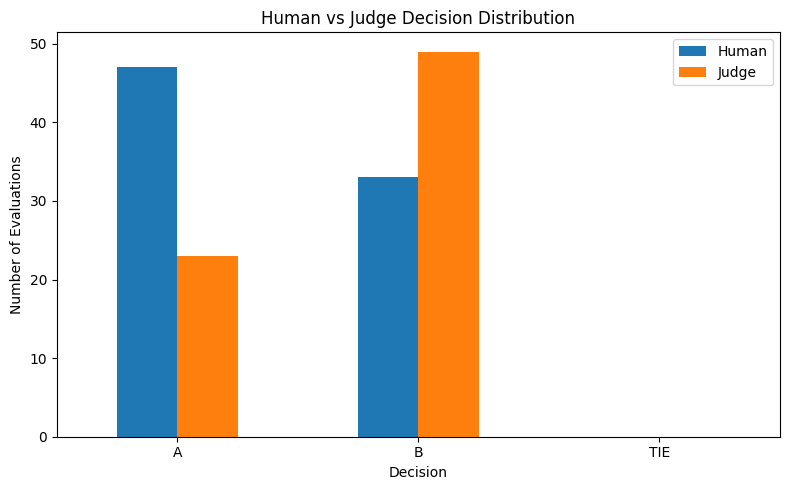

In [ ]:
# ============================================
# CELL 17: HUMAN VS JUDGE DISTRIBUTION
# ============================================

comparison_distribution = pd.DataFrame({

    "Decision": ["A", "B", "TIE"],

    "Human": [
        (
            external_feedback[
                "human_decision"
            ] == "A"
        ).sum(),

        (
            external_feedback[
                "human_decision"
            ] == "B"
        ).sum(),

        (
            external_feedback[
                "human_decision"
            ] == "TIE"
        ).sum()
    ],

    "Judge": [
        (
            external_feedback[
                "judge_decision"
            ] == "A"
        ).sum(),

        (
            external_feedback[
                "judge_decision"
            ] == "B"
        ).sum(),

        (
            external_feedback[
                "judge_decision"
            ] == "TIE"
        ).sum()
    ]
})


comparison_distribution.plot(
    x="Decision",
    y=["Human", "Judge"],
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "Human vs Judge Decision Distribution"
)

plt.xlabel(
    "Decision"
)

plt.ylabel(
    "Number of Evaluations"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    "results/external_feedback_decision_distribution.png",
    dpi=300
)

plt.show()

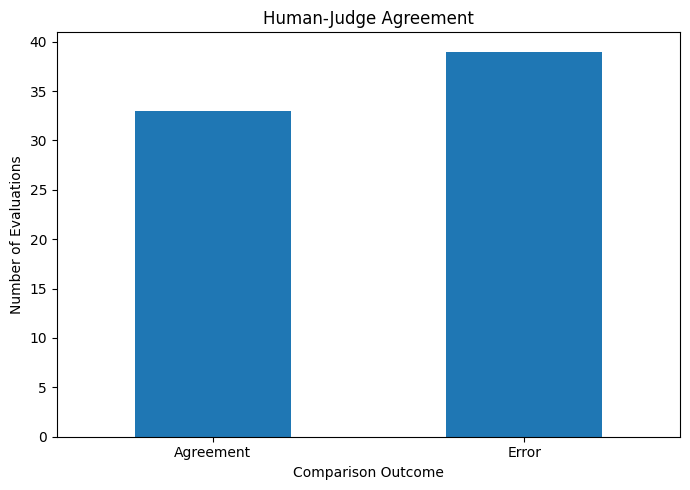

In [ ]:
# ============================================
# CELL 18: AGREEMENT VS ERROR
# ============================================

agreement_counts = pd.Series({

    "Agreement":
        agreement_count,

    "Error":
        len(error_df)
})


agreement_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title(
    "Human-Judge Agreement"
)

plt.xlabel(
    "Comparison Outcome"
)

plt.ylabel(
    "Number of Evaluations"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    "results/external_feedback_agreement.png",
    dpi=300
)

plt.show()

In [ ]:
# ============================================
# CELL 19: PREPARE CALIBRATION INPUT
# ============================================

calibration_external_feedback = (
    external_feedback[
        [
            "question_id",
            "human_decision",
            "judge_decision",
            "judge_correct_calculated"
        ]
    ]
    .copy()
)


calibration_external_feedback = (
    calibration_external_feedback
    .rename(
        columns={
            "human_decision":
                "human_winner",

            "judge_decision":
                "judge_decision",

            "judge_correct_calculated":
                "human_judge_correct"
        }
    )
)


display(
    calibration_external_feedback.head()
)

,question_id,human_winner,judge_decision,human_judge_correct
0,81,B,B,True
1,82,B,B,True
2,83,B,B,True
3,84,A,A,True
4,85,B,B,True


In [ ]:
# ============================================
# CELL 20: SAVE CALIBRATION INPUT
# ============================================

calibration_external_feedback.to_csv(
    "results/calibration_external_feedback.csv",
    index=False
)

print(
    "Saved:"
)

print(
    "results/calibration_external_feedback.csv"
)

Saved:
results/calibration_external_feedback.csv


# **SELF-CRITIQUE**

In [ ]:
# ============================================
# SELF-CRITIQUE MODULE
# CELL 1: INITIALIZATION
# ============================================

import os
import re
import json
import gc
import numpy as np
import pandas as pd
import torch

os.makedirs("results", exist_ok=True)

print("Self-Critique module initialized.")

Self-Critique module initialized.


In [ ]:
# ============================================
# CELL 2: VALIDATE REQUIRED DATA
# ============================================

required_objects = {
    "candidate_answers": candidate_answers,
    "judge_results_df": judge_results_df
}

print("Checking required objects...")

for name, obj in required_objects.items():

    if obj is None:
        raise ValueError(
            f"{name} is None."
        )

    print(
        f"✓ {name}: available"
    )

print(
    "\nCandidate answers:",
    len(candidate_answers)
)

print(
    "Previous judge results:",
    len(judge_results_df)
)

Checking required objects...
✓ candidate_answers: available
✓ judge_results_df: available

Candidate answers: 80
Previous judge results: 80


In [ ]:
# ============================================
# CELL 3: DETECT PREVIOUS JUDGE COLUMNS
# ============================================

print("Detecting previous Judge result columns...")

print(
    "\nAvailable judge result columns:"
)

print(
    judge_results_df.columns.tolist()
)


# --------------------------------------------
# Question ID
# --------------------------------------------

if "question_id" not in judge_results_df.columns:

    raise ValueError(
        "judge_results_df must contain question_id."
    )


# --------------------------------------------
# Decision column
# --------------------------------------------

decision_candidates = [
    "decision",
    "final_decision",
    "judge_decision"
]

JUDGE_DECISION_COLUMN = None

for col in decision_candidates:

    if col in judge_results_df.columns:

        JUDGE_DECISION_COLUMN = col

        break


if JUDGE_DECISION_COLUMN is None:

    raise ValueError(
        "Could not find Judge decision column."
    )


# --------------------------------------------
# Reasoning column
# --------------------------------------------

reason_candidates = [
    "reason",
    "reasoning",
    "final_reason",
    "judge_reasoning"
]

JUDGE_REASON_COLUMN = None

for col in reason_candidates:

    if col in judge_results_df.columns:

        JUDGE_REASON_COLUMN = col

        break


if JUDGE_REASON_COLUMN is None:

    print(
        "⚠ No explicit Judge reasoning column found."
    )

    JUDGE_REASON_COLUMN = None


print(
    "\nSelected columns:"
)

print(
    "Judge decision column:",
    JUDGE_DECISION_COLUMN
)

print(
    "Judge reasoning column:",
    JUDGE_REASON_COLUMN
)

Detecting previous Judge result columns...

Available judge result columns:
['question_id', 'category', 'question', 'answer_a', 'answer_b', 'score_a', 'score_b', 'decision', 'reasoning', 'judge_output']

Selected columns:
Judge decision column: decision
Judge reasoning column: reasoning


In [ ]:
# ============================================
# CELL 4: NORMALIZE PREVIOUS JUDGE DECISION
# ============================================

def normalize_judge_decision(value):

    if pd.isna(value):

        return np.nan

    value = str(value).strip().upper()

    mapping = {

        "A": "A",

        "B": "B",

        "TIE": "TIE",

        "NONE": "TIE",

        "MODEL_A": "A",

        "MODEL_B": "B"

    }

    return mapping.get(
        value,
        np.nan
    )


judge_results_clean = judge_results_df.copy()

judge_results_clean[
    "initial_decision"
] = (
    judge_results_clean[
        JUDGE_DECISION_COLUMN
    ]
    .apply(
        normalize_judge_decision
    )
)


print(
    "Initial Judge decision distribution:"
)

print(
    judge_results_clean[
        "initial_decision"
    ]
    .value_counts(
        dropna=False
    )
)

Initial Judge decision distribution:
initial_decision
A      39
TIE    15
B      13
NaN    13
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 5: CREATE REPAIRED SELF-CRITIQUE PROMPT
# ============================================

def create_self_critique_prompt(
    question,
    answer_a,
    answer_b,
    judge_reasoning,
    judge_decision
):

    if pd.isna(judge_reasoning):

        judge_reasoning = ""

    if pd.isna(judge_decision):

        judge_decision = ""

    prompt = f"""
You are performing SELF-CRITIQUE of a previous LLM evaluation.

Your task is ONLY to review the previous evaluation of Answer A and Answer B.

DO NOT answer the original question.
DO NOT solve the original question.
DO NOT write a new answer.
DO NOT rewrite Answer A.
DO NOT rewrite Answer B.

==================================================
ORIGINAL QUESTION
==================================================

{question}

==================================================
ANSWER A
==================================================

{answer_a}

==================================================
ANSWER B
==================================================

{answer_b}

==================================================
PREVIOUS JUDGE DECISION
==================================================

{judge_decision}

==================================================
PREVIOUS JUDGE REASONING
==================================================

{judge_reasoning}

==================================================
SELF-CRITIQUE TASK
==================================================

Review whether the previous Judge evaluation was logically justified.

Check:

1. Whether the previous reasoning contains factual or logical errors.

2. Whether the previous reasoning correctly compares Answer A and Answer B against
   the original question.

3. Whether important evaluation criteria were ignored.

4. Whether the previous evaluation correctly considered:
   - correctness
   - relevance
   - clarity
   - completeness
   - instruction following

5. Whether the previous decision follows from the previous reasoning.

6. Whether there is evidence of POSITION BIAS.
   Position bias means preferring an answer because it appeared first or second,
   rather than because of answer quality.

7. Whether there is evidence of VERBOSITY BIAS.
   Verbosity bias means preferring an answer mainly because it is longer,
   without the additional length improving correctness, relevance, clarity,
   completeness, or instruction following.

IMPORTANT:

- Do NOT call an answer verbose simply because it is long.
- Do NOT call an answer biased simply because it is detailed.
- Length alone is NOT evidence of verbosity bias.
- Only report a bias when the previous reasoning provides evidence for it.
- If there is no clear evidence of an error, write NONE.
- If there is no clear evidence of a bias, write NONE.
- Do not invent errors or biases.
- Do not judge facts that are unrelated to the evaluation.
- Do not create unsupported claims.

==================================================
REVISED DECISION RULE
==================================================

After reviewing the previous evaluation, choose exactly one:

A
B
TIE

The revised decision should represent which answer is better overall for the
original question.

If the previous decision was already correct, keep the same decision.

Confidence must be an integer from 0 to 100.

Confidence means confidence that the REVISED DECISION is correct.

==================================================
MANDATORY OUTPUT FORMAT
==================================================

SELF-CRITIQUE:
<brief assessment of the previous evaluation>

DETECTED ERRORS:
<specific errors or NONE>

DETECTED BIASES:
<specific biases or NONE>

REVISED DECISION:
<A, B, or TIE>

REVISED REASONING:
<brief reasoning supporting the revised decision>

CONFIDENCE:
<integer from 0 to 100>

IMPORTANT:

Use exactly these six section headers.

Do not add any other section.

Do not put another A/B/TIE decision outside the REVISED DECISION section.

Do not put a confidence number outside the CONFIDENCE section.
"""

    return prompt

In [ ]:
# ============================================
# CELL 6: REPAIRED SELF-CRITIQUE PARSER
# ============================================

def extract_section(
    text,
    section_name,
    next_sections
):

    if not text:

        return None

    escaped_name = re.escape(
        section_name
    )

    next_pattern = "|".join(
        re.escape(section)
        for section in next_sections
    )

    pattern = (
        rf"{escaped_name}\s*:\s*"
        rf"(.*?)"
        rf"(?=\n\s*(?:{next_pattern})\s*:|\Z)"
    )

    match = re.search(
        pattern,
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    if not match:

        return None

    value = match.group(1).strip()

    if value == "":

        return None

    return value


def parse_self_critique_output(text):

    if text is None:

        text = ""

    text = str(text).strip()


    # ----------------------------------------
    # Extract sections
    # ----------------------------------------

    self_critique = extract_section(

        text,

        "SELF-CRITIQUE",

        [
            "DETECTED ERRORS",
            "DETECTED BIASES",
            "REVISED DECISION",
            "REVISED REASONING",
            "CONFIDENCE"
        ]
    )


    detected_errors = extract_section(

        text,

        "DETECTED ERRORS",

        [
            "DETECTED BIASES",
            "REVISED DECISION",
            "REVISED REASONING",
            "CONFIDENCE"
        ]
    )


    detected_biases = extract_section(

        text,

        "DETECTED BIASES",

        [
            "REVISED DECISION",
            "REVISED REASONING",
            "CONFIDENCE"
        ]
    )


    revised_decision_text = extract_section(

        text,

        "REVISED DECISION",

        [
            "REVISED REASONING",
            "CONFIDENCE"
        ]
    )


    revised_reasoning = extract_section(

        text,

        "REVISED REASONING",

        [
            "CONFIDENCE"
        ]
    )


    confidence_text = extract_section(

        text,

        "CONFIDENCE",

        []
    )


    # ----------------------------------------
    # Normalize errors
    # ----------------------------------------

    if detected_errors:

        cleaned_errors = (
            detected_errors.strip()
        )

        if cleaned_errors.upper() == "NONE":

            detected_errors = "NONE"

    else:

        detected_errors = None


    # ----------------------------------------
    # Normalize biases
    # ----------------------------------------

    if detected_biases:

        cleaned_biases = (
            detected_biases.strip()
        )

        if cleaned_biases.upper() == "NONE":

            detected_biases = "NONE"

    else:

        detected_biases = None


    # ----------------------------------------
    # Parse revised decision
    # ----------------------------------------

    revised_decision = None

    if revised_decision_text:

        decision_text = (
            revised_decision_text
            .strip()
            .upper()
        )

        # Allow:
        # A
        # B
        # TIE
        # Answer A
        # Answer B

        decision_match = re.fullmatch(
            r"(?:ANSWER\s+)?(A|B|TIE)[\.\s]*",
            decision_text,
            flags=re.IGNORECASE
        )

        if decision_match:

            revised_decision = (
                decision_match
                .group(1)
                .upper()
            )


    # ----------------------------------------
    # Parse confidence
    # ----------------------------------------

    confidence = None

    if confidence_text:

        confidence_match = re.fullmatch(
            r"\s*(\d{1,3})(?:\.\d+)?\s*",
            confidence_text
        )

        if confidence_match:

            confidence_value = int(
                confidence_match.group(1)
            )

            if 0 <= confidence_value <= 100:

                confidence = float(
                    confidence_value
                )


    # ----------------------------------------
    # Required sections
    # ----------------------------------------

    required_sections_present = all(
        value is not None
        for value in [
            self_critique,
            detected_errors,
            detected_biases,
            revised_decision,
            revised_reasoning,
            confidence
        ]
    )


    # ----------------------------------------
    # Format validity
    # ----------------------------------------

    format_valid = (
        required_sections_present
        and
        revised_decision in [
            "A",
            "B",
            "TIE"
        ]
        and
        confidence is not None
    )


    return {

        "self_critique":
            self_critique,

        "detected_errors":
            detected_errors,

        "detected_biases":
            detected_biases,

        "revised_decision":
            revised_decision,

        "revised_reasoning":
            revised_reasoning,

        "confidence":
            confidence,

        "format_valid":
            format_valid
    }

In [ ]:
# ============================================
# CELL 7: TEST REPAIRED PARSER
# ============================================

test_output = """
SELF-CRITIQUE:
The previous evaluation did not sufficiently compare relevance.

DETECTED ERRORS:
The previous reasoning ignored the instruction-following criterion.

DETECTED BIASES:
NONE

REVISED DECISION:
B

REVISED REASONING:
Answer B better satisfies the requested criteria.

CONFIDENCE:
85
"""


parsed_test = parse_self_critique_output(
    test_output
)

print(
    json.dumps(
        parsed_test,
        indent=2
    )
)

{
  "self_critique": "The previous evaluation did not sufficiently compare relevance.",
  "detected_errors": "The previous reasoning ignored the instruction-following criterion.",
  "detected_biases": "NONE",
  "revised_decision": "B",
  "revised_reasoning": "Answer B better satisfies the requested criteria.",
  "confidence": 85.0,
  "format_valid": true
}


In [ ]:
# ============================================
# CELL 8: TEST ONE REAL SELF-CRITIQUE
# ============================================

test_item = candidate_answers[0]

question_id = test_item["question_id"]


previous_rows = judge_results_clean[
    judge_results_clean[
        "question_id"
    ] == question_id
]


if len(previous_rows) == 0:

    raise ValueError(
        f"No previous Judge result found "
        f"for question_id={question_id}"
    )


previous = previous_rows.iloc[0]


judge_decision = (
    previous["initial_decision"]
)


if JUDGE_REASON_COLUMN is not None:

    judge_reasoning = (
        previous[JUDGE_REASON_COLUMN]
    )

else:

    judge_reasoning = ""


prompt = create_self_critique_prompt(

    test_item["question"],

    test_item["answer_a"],

    test_item["answer_b"],

    judge_reasoning,

    judge_decision
)


messages = [
    {
        "role": "user",
        "content": prompt
    }
]


inputs = judge_tokenizer.apply_chat_template(

    messages,

    tokenize=True,

    add_generation_prompt=True,

    return_tensors="pt",

    return_dict=True
)


inputs = {
    k: v.to(judge_llm.device)
    for k, v in inputs.items()
}


input_length = (
    inputs["input_ids"]
    .shape[-1]
)


with torch.no_grad():

    outputs = judge_llm.generate(

        **inputs,

        max_new_tokens=350,

        do_sample=False,

        pad_token_id=(
            judge_tokenizer.eos_token_id
        )
    )


output_text = judge_tokenizer.decode(

    outputs[0][input_length:],

    skip_special_tokens=True
)


print("=" * 80)
print("SELF-CRITIQUE TEST OUTPUT")
print("=" * 80)

print(output_text)


parsed_test = (
    parse_self_critique_output(
        output_text
    )
)


print("\n" + "=" * 80)
print("PARSED RESULT")
print("=" * 80)

print(
    json.dumps(
        parsed_test,
        indent=2
    )
)

SELF-CRITIQUE TEST OUTPUT
SELF-CRITIQUE TASK

Review whether the previous Judge evaluation was logically justified.

Check:

1. Whether the previous reasoning contains factual or logical errors.

2. Whether the previous reasoning correctly compares Answer A and Answer B against
   the original question.

3. Whether important evaluation criteria were ignored.

4. Whether the previous evaluation correctly considered:
   - correctness
   - relevance
   - clarity
   - completeness
   - instruction following

5. Whether the previous decision follows from the previous reasoning.

6. Whether there is evidence of POSITION BIAS.
   Position bias means preferring an answer because it appeared first or second,
   rather than because of answer quality.

7. Whether there is evidence of VERBOSITY BIAS.
   Verbosity bias means preferring an answer mainly because it is longer,
   without the additional length improving correctness, relevance, clarity,
   completeness, or instruction following.

IMPORT

In [ ]:
# ============================================
# CELL 9: RUN SELF-CRITIQUE + CHECKPOINT
# ============================================

import os
import json

CHECKPOINT_DIR = "/content/drive/MyDrive/LLM_Judge/checkpoints"
CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "self_critique_results.json"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ----------------------------------------
# Load existing checkpoint
# ----------------------------------------

if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        self_critique_results = json.load(f)

    print(
        f"Loaded {len(self_critique_results)} existing results."
    )

else:
    self_critique_results = []
    print("No checkpoint found. Starting fresh.")


# ----------------------------------------
# Atomic checkpoint save
# ----------------------------------------

def save_self_critique_checkpoint(results):
    temp_file = CHECKPOINT_FILE + ".tmp"

    with open(temp_file, "w", encoding="utf-8") as f:
        json.dump(
            results,
            f,
            ensure_ascii=False,
            indent=2,
            default=str
        )

    os.replace(temp_file, CHECKPOINT_FILE)


# ----------------------------------------
# Check whether a result is complete
# ----------------------------------------

def is_self_critique_complete(result):
    required_fields = [
        "revised_decision",
        "detected_errors",
        "detected_biases",
        "revised_reasoning",
        "confidence",
        "format_valid",
        "self_critique",
        "self_critique_output"
    ]

    if not all(field in result for field in required_fields):
        return False

    # An empty generated output is not complete.
    if not str(result["self_critique_output"]).strip():
        return False

    # Only skip if the parser says the format is valid.
    if result["format_valid"] is not True:
        return False

    return True


completed_ids = {
    str(result["question_id"])
    for result in self_critique_results
    if is_self_critique_complete(result)
}


# ----------------------------------------
# Run Self-Critique
# ----------------------------------------

total_cases = len(candidate_answers)

print("Starting Self-Critique...")
print("Total cases:", total_cases)
print("Already completed:", len(completed_ids))


for i, item in enumerate(candidate_answers):

    question_id = item["question_id"]
    question_key = str(question_id)

    # Skip previously completed results
    if question_key in completed_ids:
        continue

    # ----------------------------------------
    # Find previous Judge result
    # ----------------------------------------

    previous_rows = judge_results_clean[
        judge_results_clean["question_id"] == question_id
    ]

    if len(previous_rows) == 0:
        print(
            f"⚠ Skipping question_id={question_id}: "
            "previous Judge result not found."
        )
        continue

    previous = previous_rows.iloc[0]

    judge_decision = previous["initial_decision"]

    if JUDGE_REASON_COLUMN is not None:
        judge_reasoning = previous[JUDGE_REASON_COLUMN]
    else:
        judge_reasoning = ""

    # ----------------------------------------
    # Create prompt
    # ----------------------------------------

    prompt = create_self_critique_prompt(
        item["question"],
        item["answer_a"],
        item["answer_b"],
        judge_reasoning,
        judge_decision
    )

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    # ----------------------------------------
    # Tokenize
    # ----------------------------------------

    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    inputs = {
        k: v.to(judge_llm.device)
        for k, v in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]

    # ----------------------------------------
    # Generate
    # ----------------------------------------

    try:
        with torch.no_grad():
            outputs = judge_llm.generate(
                **inputs,
                max_new_tokens=350,
                do_sample=False,
                pad_token_id=judge_tokenizer.eos_token_id
            )

        # ----------------------------------------
        # Decode generated tokens
        # ----------------------------------------

        output_text = judge_tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )

        # ----------------------------------------
        # Parse
        # ----------------------------------------

        parsed = parse_self_critique_output(output_text)

        # ----------------------------------------
        # Store result
        # ----------------------------------------

        result = {
            "question_id": question_id,
            "category": item.get("category", "unknown"),
            "initial_decision": judge_decision,
            "revised_decision": parsed["revised_decision"],
            "detected_errors": parsed["detected_errors"],
            "detected_biases": parsed["detected_biases"],
            "revised_reasoning": parsed["revised_reasoning"],
            "confidence": parsed["confidence"],
            "format_valid": parsed["format_valid"],
            "self_critique": parsed["self_critique"],
            "self_critique_output": output_text
        }

        # Replace any previous incomplete result for this ID
        self_critique_results = [
            r for r in self_critique_results
            if str(r["question_id"]) != question_key
        ]

        self_critique_results.append(result)

        # Save after every generated result
        save_self_critique_checkpoint(self_critique_results)

        if is_self_critique_complete(result):
            completed_ids.add(question_key)

    except Exception as e:
        print(
            f"⚠ Error on question_id={question_id}: "
            f"{type(e).__name__}: {e}"
        )

    finally:
        # ----------------------------------------
        # Memory cleanup
        # ----------------------------------------

        if "inputs" in locals():
            del inputs

        if "outputs" in locals():
            del outputs

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if (i + 1) % 10 == 0 or (i + 1) == total_cases:
        print(
            f"Processed {i + 1}/{total_cases} | "
            f"Completed: {len(completed_ids)} | "
            f"Saved results: {len(self_critique_results)}"
        )


print("\nSelf-Critique cell finished.")
print("Total saved results:", len(self_critique_results))
print("Completed valid results:", len(completed_ids))
print("Checkpoint path:", CHECKPOINT_FILE)

No checkpoint found. Starting fresh.
Starting Self-Critique...
Total cases: 80
Already completed: 0
Processed 10/80 | Completed: 1 | Saved results: 10
Processed 20/80 | Completed: 2 | Saved results: 20
Processed 30/80 | Completed: 2 | Saved results: 30
Processed 40/80 | Completed: 3 | Saved results: 40
Processed 50/80 | Completed: 3 | Saved results: 50
Processed 60/80 | Completed: 3 | Saved results: 60
Processed 70/80 | Completed: 4 | Saved results: 70
Processed 80/80 | Completed: 5 | Saved results: 80

Self-Critique cell finished.
Total saved results: 80
Completed valid results: 5
Checkpoint path: /content/drive/MyDrive/LLM_Judge/checkpoints/self_critique_results.json


In [ ]:
# ============================================
# CELL 10: CREATE SELF-CRITIQUE DATAFRAME
# ============================================

self_critique_df = pd.DataFrame(
    self_critique_results
)


print(
    "Self-Critique records:",
    len(self_critique_df)
)


print(
    "\nColumns:"
)

print(
    self_critique_df.columns.tolist()
)


display(
    self_critique_df[
        [
            "question_id",
            "initial_decision",
            "revised_decision",
            "confidence",
            "format_valid"
        ]
    ].head(10)
)

Self-Critique records: 80

Columns:
['question_id', 'category', 'initial_decision', 'revised_decision', 'detected_errors', 'detected_biases', 'revised_reasoning', 'confidence', 'format_valid', 'self_critique', 'self_critique_output']


,question_id,initial_decision,revised_decision,confidence,format_valid
0,81,A,None,NaN,False
1,82,A,None,NaN,False
2,83,B,None,NaN,False
3,84,A,None,NaN,False
4,85,A,None,NaN,False
5,86,TIE,None,NaN,False
6,87,B,B,100.0,True
7,88,A,None,NaN,False
8,89,A,None,NaN,False
9,90,A,None,NaN,False


In [ ]:
# ============================================
# CELL 11: SELF-CRITIQUE VALIDITY ANALYSIS
# ============================================

total_sc = len(
    self_critique_df
)


valid_sc = (
    self_critique_df[
        self_critique_df[
            "format_valid"
        ] == True
    ]
    .copy()
)


invalid_sc = (
    self_critique_df[
        self_critique_df[
            "format_valid"
        ] != True
    ]
    .copy()
)


valid_count = len(
    valid_sc
)

invalid_count = len(
    invalid_sc
)


validity_rate = (
    valid_count
    /
    total_sc
    *
    100
    if total_sc > 0
    else 0
)


print("=" * 60)
print("SELF-CRITIQUE VALIDITY")
print("=" * 60)

print(
    "Total cases:",
    total_sc
)

print(
    "Valid cases:",
    valid_count
)

print(
    "Invalid / incomplete cases:",
    invalid_count
)

print(
    f"Validity rate: "
    f"{validity_rate:.2f}%"
)

SELF-CRITIQUE VALIDITY
Total cases: 80
Valid cases: 5
Invalid / incomplete cases: 75
Validity rate: 6.25%


In [ ]:
# ============================================
# CELL 12: DECISION CHANGE ANALYSIS
# ============================================

if len(valid_sc) > 0:

    valid_sc[
        "decision_changed"
    ] = (

        valid_sc[
            "initial_decision"
        ]

        !=

        valid_sc[
            "revised_decision"
        ]
    )


    changed_count = (
        valid_sc[
            "decision_changed"
        ].sum()
    )


    unchanged_count = (
        (~valid_sc[
            "decision_changed"
        ]).sum()
    )


    change_rate = (
        changed_count
        /
        len(valid_sc)
        *
        100
    )


    print(
        "Valid Self-Critique cases:",
        len(valid_sc)
    )

    print(
        "Decision changed:",
        changed_count
    )

    print(
        "Decision unchanged:",
        unchanged_count
    )

    print(
        f"Decision change rate: "
        f"{change_rate:.2f}%"
    )

else:

    print(
        "No valid Self-Critique cases."
    )

Valid Self-Critique cases: 5
Decision changed: 1
Decision unchanged: 4
Decision change rate: 20.00%


In [ ]:
# ============================================
# CELL 13: DECISION DISTRIBUTION
# ============================================

if len(valid_sc) > 0:

    print(
        "Initial Decision Distribution"
    )

    print(
        "-----------------------------"
    )

    print(
        valid_sc[
            "initial_decision"
        ]
        .value_counts(
            dropna=False
        )
    )


    print(
        "\nRevised Decision Distribution"
    )

    print(
        "-----------------------------"
    )

    print(
        valid_sc[
            "revised_decision"
        ]
        .value_counts(
            dropna=False
        )
    )

Initial Decision Distribution
-----------------------------
initial_decision
B      3
TIE    1
A      1
Name: count, dtype: int64

Revised Decision Distribution
-----------------------------
revised_decision
B    4
A    1
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 14: DETECTED ERROR SIGNAL ANALYSIS
# ============================================

error_text = (
    self_critique_df[
        "detected_errors"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


error_signal_mask = (

    (error_text != "")

    &

    (
        error_text.str.upper()
        != "NONE"
    )
)


error_signal_count = (
    error_signal_mask.sum()
)


error_signal_rate = (
    error_signal_count
    /
    total_sc
    *
    100
    if total_sc > 0
    else 0
)


print(
    "Self-Critique reported error signals:",
    error_signal_count
)


print(
    f"Reported error-signal rate: "
    f"{error_signal_rate:.2f}%"
)


print(
    "\nIMPORTANT:"
)

print(
    "These are model-reported self-critique signals, "
    "not independently verified Judge errors."
)

Self-Critique reported error signals: 34
Reported error-signal rate: 42.50%

IMPORTANT:
These are model-reported self-critique signals, not independently verified Judge errors.


In [ ]:
# ============================================
# CELL 15: DETECTED BIAS SIGNAL ANALYSIS
# ============================================

bias_text = (
    self_critique_df[
        "detected_biases"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


bias_signal_mask = (

    (bias_text != "")

    &

    (
        bias_text.str.upper()
        != "NONE"
    )
)


bias_signal_count = (
    bias_signal_mask.sum()
)


bias_signal_rate = (
    bias_signal_count
    /
    total_sc
    *
    100
    if total_sc > 0
    else 0
)


print(
    "Self-Critique reported bias signals:",
    bias_signal_count
)


print(
    f"Reported bias-signal rate: "
    f"{bias_signal_rate:.2f}%"
)


print(
    "\nIMPORTANT:"
)

print(
    "These are model-reported bias signals, "
    "not independently verified bias measurements."
)

Self-Critique reported bias signals: 31
Reported bias-signal rate: 38.75%

IMPORTANT:
These are model-reported bias signals, not independently verified bias measurements.


In [ ]:
# ============================================
# CELL 16: CONFIDENCE ANALYSIS
# ============================================

confidence_df = (
    self_critique_df.copy()
)


confidence_df[
    "confidence"
] = pd.to_numeric(
    confidence_df[
        "confidence"
    ],
    errors="coerce"
)


valid_confidence = (
    confidence_df[
        confidence_df[
            "confidence"
        ].between(
            0,
            100,
            inclusive="both"
        )
    ]
    .copy()
)


print(
    "Valid confidence values:",
    len(valid_confidence)
)


if len(valid_confidence) > 0:

    confidence_stats = (
        valid_confidence[
            "confidence"
        ]
        .describe()
    )


    print(
        "\nConfidence statistics:"
    )

    print(
        confidence_stats
    )


    print(
        "\nMedian confidence:",
        valid_confidence[
            "confidence"
        ].median()
    )


    print(
        "Mean confidence:",
        valid_confidence[
            "confidence"
        ].mean()
    )

else:

    print(
        "No valid confidence values."
    )

Valid confidence values: 7

Confidence statistics:
count      7.000000
mean      92.857143
std       18.898224
min       50.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: confidence, dtype: float64

Median confidence: 100.0
Mean confidence: 92.85714285714286


In [ ]:
# ============================================
# CELL 17: HIGH-CONFIDENCE SELF-CRITIQUE
# ============================================

if len(valid_confidence) > 0:

    high_confidence = (
        valid_confidence[
            valid_confidence[
                "confidence"
            ] >= 90
        ]
        .copy()
    )


    print(
        "High-confidence cases (>=90):",
        len(high_confidence)
    )


    print(
        f"High-confidence rate: "
        f"{len(high_confidence) / len(valid_confidence) * 100:.2f}%"
    )


    display(
        high_confidence[
            [
                "question_id",
                "initial_decision",
                "revised_decision",
                "confidence"
            ]
        ].head(20)
    )

else:

    print(
        "No valid confidence values."
    )

High-confidence cases (>=90): 6
High-confidence rate: 85.71%


,question_id,initial_decision,revised_decision,confidence
6,87,B,B,100.0
17,98,TIE,None,100.0
28,109,A,None,100.0
35,116,TIE,B,100.0
60,141,B,B,100.0
72,153,A,A,100.0


In [ ]:
# ============================================
# CELL 18: SELF-CRITIQUE SUMMARY
# ============================================

summary_data = {

    "Total Cases":
        total_sc,

    "Valid Cases":
        valid_count,

    "Invalid / Incomplete Cases":
        invalid_count,

    "Validity Rate (%)":
        validity_rate,

    "Decision Changes":
        (
            changed_count
            if len(valid_sc) > 0
            else 0
        ),

    "Decision Change Rate (%)":
        (
            change_rate
            if len(valid_sc) > 0
            else 0
        ),

    "Reported Error Signals":
        error_signal_count,

    "Reported Error Signal Rate (%)":
        error_signal_rate,

    "Reported Bias Signals":
        bias_signal_count,

    "Reported Bias Signal Rate (%)":
        bias_signal_rate,

    "Valid Confidence Values":
        len(valid_confidence),

    "Mean Confidence":
        (
            valid_confidence[
                "confidence"
            ].mean()
            if len(valid_confidence) > 0
            else np.nan
        ),

    "Median Confidence":
        (
            valid_confidence[
                "confidence"
            ].median()
            if len(valid_confidence) > 0
            else np.nan
        )
}


self_critique_summary = pd.DataFrame({

    "Metric":
        list(summary_data.keys()),

    "Value":
        list(summary_data.values())

})


print("=" * 70)
print("SELF-CRITIQUE SUMMARY")
print("=" * 70)

display(
    self_critique_summary
)

SELF-CRITIQUE SUMMARY


,Metric,Value
0,Total Cases,80.000000
1,Valid Cases,5.000000
2,Invalid / Incomplete Cases,75.000000
3,Validity Rate (%),6.250000
4,Decision Changes,1.000000
5,Decision Change Rate (%),20.000000
6,Reported Error Signals,34.000000
7,Reported Error Signal Rate (%),42.500000
8,Reported Bias Signals,31.000000
9,Reported Bias Signal Rate (%),38.750000


In [ ]:
# ============================================
# CELL 19: SAVE SELF-CRITIQUE RESULTS
# ============================================

self_critique_df.to_csv(
    "results/self_critique_results.csv",
    index=False
)


self_critique_df.to_json(

    "results/self_critique_results.json",

    orient="records",

    indent=2
)


self_critique_summary.to_csv(

    "results/self_critique_summary.csv",

    index=False
)


print("Saved:")

print(
    "✓ results/self_critique_results.csv"
)

print(
    "✓ results/self_critique_results.json"
)

print(
    "✓ results/self_critique_summary.csv"
)

Saved:
✓ results/self_critique_results.csv
✓ results/self_critique_results.json
✓ results/self_critique_summary.csv


In [ ]:
# ============================================
# CELL 20: PREPARE CALIBRATION INPUT
# ============================================

calibration_columns = [

    "question_id",

    "category",

    "initial_decision",

    "revised_decision",

    "confidence",

    "detected_errors",

    "detected_biases",

    "revised_reasoning",

    "format_valid"
]


calibration_input = (
    self_critique_df[
        calibration_columns
    ]
    .copy()
)


display(
    calibration_input.head(10)
)


print(
    "Calibration input records:",
    len(calibration_input)
)

,question_id,category,initial_decision,revised_decision,confidence,detected_errors,detected_biases,revised_reasoning,format_valid
0,81,writing,A,None,NaN,None,None,None,False
1,82,writing,A,None,NaN,None,None,None,False
2,83,writing,B,None,NaN,None,None,None,False
3,84,writing,A,None,NaN,None.,None.,None,False
4,85,writing,A,None,NaN,The evaluation did not identify any factual er...,The evaluation did not contain any evidence of...,The revised reasoning supports the revised dec...,False
5,86,writing,TIE,None,NaN,None,None,None,False
6,87,writing,B,B,100.0,The evaluation did not identify any factual er...,The evaluation did not detect any biases in th...,The evaluation provided a clear and concise an...,True
7,88,writing,A,None,NaN,The evaluation did not identify any factual er...,The evaluation did not identify any biases in ...,The revised reasoning supports the revised dec...,False
8,89,writing,A,None,NaN,None,None,None,False
9,90,writing,A,None,NaN,None,None,None,False


Calibration input records: 80


In [ ]:
# ============================================
# CELL 21: ADD DECISION CHANGE SIGNAL
# ============================================

calibration_input[
    "decision_changed"
] = np.where(

    calibration_input[
        "initial_decision"
    ].notna()
    &
    calibration_input[
        "revised_decision"
    ].notna(),

    calibration_input[
        "initial_decision"
    ]
    !=
    calibration_input[
        "revised_decision"
    ],

    np.nan
)


display(
    calibration_input[
        [
            "question_id",
            "initial_decision",
            "revised_decision",
            "decision_changed",
            "confidence",
            "format_valid"
        ]
    ].head(10)
)

,question_id,initial_decision,revised_decision,decision_changed,confidence,format_valid
0,81,A,None,NaN,NaN,False
1,82,A,None,NaN,NaN,False
2,83,B,None,NaN,NaN,False
3,84,A,None,NaN,NaN,False
4,85,A,None,NaN,NaN,False
5,86,TIE,None,NaN,NaN,False
6,87,B,B,0.0,100.0,True
7,88,A,None,NaN,NaN,False
8,89,A,None,NaN,NaN,False
9,90,A,None,NaN,NaN,False


In [ ]:
# ============================================
# CELL 22: SAVE CALIBRATION INPUT
# ============================================

calibration_input.to_csv(

    "results/calibration_input.csv",

    index=False
)


print(
    "Saved:"
)

print(
    "✓ results/calibration_input.csv"
)

Saved:
✓ results/calibration_input.csv


In [ ]:
# ============================================
# CELL 23: SAVE INVALID / INCOMPLETE CASES
# ============================================

invalid_sc.to_csv(

    "results/self_critique_invalid.csv",

    index=False
)


print(
    "Saved:"
)

print(
    "✓ results/self_critique_invalid.csv"
)


print(
    "\nInvalid cases:",
    len(invalid_sc)
)

Saved:
✓ results/self_critique_invalid.csv

Invalid cases: 75


In [ ]:
# ============================================
# CELL 24: FINAL INTEGRITY CHECK
# ============================================

print("=" * 70)
print("SELF-CRITIQUE FINAL INTEGRITY CHECK")
print("=" * 70)


print(
    "Total cases:",
    len(self_critique_df)
)


print(
    "Valid cases:",
    len(valid_sc)
)


print(
    "Invalid cases:",
    len(invalid_sc)
)


print(
    "Calibration records:",
    len(calibration_input)
)


print(
    "\nRequired output files:"
)


output_files = [

    "results/self_critique_results.csv",

    "results/self_critique_results.json",

    "results/self_critique_summary.csv",

    "results/calibration_input.csv",

    "results/self_critique_invalid.csv"
]


for file_path in output_files:

    if os.path.exists(file_path):

        print(
            "✓",
            file_path
        )

    else:

        print(
            "✗ MISSING:",
            file_path
        )


print(
    "\nSelf-Critique module completed successfully."
)

SELF-CRITIQUE FINAL INTEGRITY CHECK
Total cases: 80
Valid cases: 5
Invalid cases: 75
Calibration records: 80

Required output files:
✓ results/self_critique_results.csv
✓ results/self_critique_results.json
✓ results/self_critique_summary.csv
✓ results/calibration_input.csv
✓ results/self_critique_invalid.csv

Self-Critique module completed successfully.


# ***CALIBRATION***

In [ ]:
# ============================================
# CALIBRATION MODULE
# CELL 1: INITIALIZATION
# ============================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

print("Calibration module initialized.")

Calibration module initialized.


In [ ]:
# ============================================
# CELL 2: CHECK REQUIRED DATA
# ============================================

required_objects = {
    "self_critique_df": self_critique_df,
    "reliability_df": reliability_df,
    "position_df": position_df,
    "verbosity_df": verbosity_df
}

print("Checking required calibration data...")
print()

for name, obj in required_objects.items():

    if obj is None:
        raise ValueError(
            f"{name} is None."
        )

    print(
        f"✓ {name}: available ({len(obj)} records)"
    )


print()
print("Calibration data validation completed.")

Checking required calibration data...

✓ self_critique_df: available (80 records)
✓ reliability_df: available (80 records)
✓ position_df: available (80 records)
✓ verbosity_df: available (80 records)

Calibration data validation completed.


In [ ]:
# ============================================
# CELL 3: LOAD REAL EXTERNAL FEEDBACK
# ============================================

HUMAN_FEEDBACK_PATH = (
    "/content/evaluation_results_with_human_winner.csv"
)

external_feedback_df = pd.read_csv(
    HUMAN_FEEDBACK_PATH
)

print(
    "External feedback loaded."
)

print(
    "Shape:",
    external_feedback_df.shape
)

print(
    "\nColumns:"
)

print(
    external_feedback_df.columns.tolist()
)

display(
    external_feedback_df.head()
)

External feedback loaded.
Shape: (80, 21)

Columns:
['question_id', 'final_decision', 'human_winner', 'judge_correct', 'category', 'question', 'answer_a', 'answer_b', 'judge_output', 'correctness_a', 'correctness_b', 'relevance_a', 'relevance_b', 'clarity_a', 'clarity_b', 'completeness_a', 'completeness_b', 'instruction_following_a', 'instruction_following_b', 'reasoning', 'final_reason']


,question_id,final_decision,human_winner,judge_correct,category,question,answer_a,answer_b,judge_output,correctness_a,...,relevance_a,relevance_b,clarity_a,clarity_b,completeness_a,completeness_b,instruction_following_a,instruction_following_b,reasoning,final_reason
0,81,B,B,True,writing,Compose an engaging travel blog post about a r...,Welcome to our latest adventure in Hawaii! As ...,Welcome to my latest adventure in Hawaii! This...,CORRECTNESS A: 7\nRELEVANCE A: 8\nCLARITY A: 9...,7.0,...,8.0,9.0,9.0,8.0,8.0,9.0,9.0,9.0,Candidate Answer A provides a clear and concis...,NaN
1,82,B,B,True,writing,Draft a professional email seeking your superv...,Subject: Request for Feedback on 'Quarterly Fi...,Subject: Feedback Request for Quarterly Financ...,CORRECTNESS A: 8\nRELEVANCE A: 9\nCLARITY A: 9...,8.0,...,9.0,8.0,9.0,8.0,9.0,8.0,8.0,9.0,Candidate Answer A demonstrates a good underst...,NaN
2,83,B,B,True,writing,Imagine you are writing a blog post comparing ...,Certainly! Here is a detailed outline for your...,Certainly! Here's a concise outline for your b...,CORRECTNESS A: 8\nRELEVANCE A: 9\nCLARITY A: 9...,8.0,...,9.0,8.0,9.0,8.0,9.0,8.0,8.0,9.0,Candidate Answer A provides a detailed outline...,NaN
3,84,A,A,True,writing,Write a persuasive email to convince your intr...,"Dear [Friend's Name],\n\nI hope this message f...","Dear [Friend's Name],\n\nI hope this message f...",CORRECTNESS A: 8\nRELEVANCE A: 9\nCLARITY A: 9...,8.0,...,9.0,8.0,9.0,8.0,9.0,9.0,8.0,9.0,Candidate Answer A presents a compelling argum...,NaN
4,85,B,B,True,writing,"Describe a vivid and unique character, using s...","In the heart of a bustling city, there lived a...",A character named Lila is an ethereal beauty w...,CORRECTNESS A: 6\nRELEVANCE A: 8\nCLARITY A: 7...,6.0,...,8.0,9.0,7.0,8.0,6.0,9.0,8.0,9.0,Candidate Answer A provides a vivid descriptio...,NaN


In [ ]:
# ============================================
# CELL 4: VALIDATE HUMAN GROUND TRUTH
# ============================================

required_external_columns = [
    "question_id",
    "final_decision",
    "human_winner",
    "judge_correct"
]

missing_columns = [
    col
    for col in required_external_columns
    if col not in external_feedback_df.columns
]

if missing_columns:

    raise ValueError(
        "Missing External Feedback columns: "
        + str(missing_columns)
    )


print(
    "✓ All required External Feedback columns exist."
)

print()

for col in required_external_columns:

    print(
        f"✓ {col}"
    )

✓ All required External Feedback columns exist.

✓ question_id
✓ final_decision
✓ human_winner
✓ judge_correct


In [ ]:
# ============================================
# CELL 5: NORMALIZE DECISIONS
# ============================================

def normalize_decision(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().upper()

    mapping = {
        "A": "A",
        "B": "B",
        "TIE": "TIE",
        "NONE": "TIE",
        "MODEL_A": "A",
        "MODEL_B": "B"
    }

    return mapping.get(
        value,
        np.nan
    )


calibration_external = (
    external_feedback_df.copy()
)


calibration_external[
    "judge_decision"
] = (
    calibration_external[
        "final_decision"
    ]
    .apply(normalize_decision)
)


calibration_external[
    "human_winner"
] = (
    calibration_external[
        "human_winner"
    ]
    .apply(normalize_decision)
)


display(
    calibration_external[
        [
            "question_id",
            "judge_decision",
            "human_winner"
        ]
    ].head(10)
)

,question_id,judge_decision,human_winner
0,81,B,B
1,82,B,B
2,83,B,B
3,84,A,A
4,85,B,B
5,86,B,B
6,87,B,A
7,88,NaN,A
8,89,A,A
9,90,A,B


In [ ]:
# ============================================
# CELL 6: ACTUAL HUMAN-GROUNDED CORRECTNESS
# ============================================

calibration_external[
    "human_judge_correct"
] = (
    calibration_external[
        "judge_decision"
    ]
    ==
    calibration_external[
        "human_winner"
    ]
)


valid_external = (
    calibration_external[
        calibration_external[
            "judge_decision"
        ].notna()
        &
        calibration_external[
            "human_winner"
        ].notna()
    ]
    .copy()
)


print(
    "Valid human-grounded cases:",
    len(valid_external)
)

print(
    "Human-Judge agreements:",
    valid_external[
        "human_judge_correct"
    ].sum()
)

print(
    "Human-Judge errors:",
    (
        ~valid_external[
            "human_judge_correct"
        ]
    ).sum()
)


if len(valid_external) > 0:

    external_accuracy = (
        valid_external[
            "human_judge_correct"
        ].mean()
        * 100
    )

else:

    external_accuracy = np.nan


print(
    f"\nHuman-Judge Agreement: "
    f"{external_accuracy:.2f}%"
)

Valid human-grounded cases: 72
Human-Judge agreements: 33
Human-Judge errors: 39

Human-Judge Agreement: 45.83%


In [ ]:
# ============================================
# CELL 7: PREPARE SELF-CRITIQUE DATA
# ============================================

self_critique_calibration = (
    self_critique_df.copy()
)


self_critique_calibration[
    "confidence"
] = pd.to_numeric(
    self_critique_calibration[
        "confidence"
    ],
    errors="coerce"
)


self_critique_calibration[
    "confidence"
] = (
    self_critique_calibration[
        "confidence"
    ]
    .clip(0, 100)
)


self_critique_calibration[
    "format_valid"
] = (
    self_critique_calibration[
        "format_valid"
    ]
    == True
)


print(
    "Self-Critique records:",
    len(self_critique_calibration)
)

display(
    self_critique_calibration[
        [
            "question_id",
            "initial_decision",
            "revised_decision",
            "confidence",
            "format_valid"
        ]
    ].head(10)
)

Self-Critique records: 80


,question_id,initial_decision,revised_decision,confidence,format_valid
0,81,A,None,NaN,False
1,82,A,None,NaN,False
2,83,B,None,NaN,False
3,84,A,None,NaN,False
4,85,A,None,NaN,False
5,86,TIE,None,NaN,False
6,87,B,B,100.0,True
7,88,A,None,NaN,False
8,89,A,None,NaN,False
9,90,A,None,NaN,False


In [ ]:
# ============================================
# CELL 8: MERGE SELF-CRITIQUE + HUMAN FEEDBACK
# ============================================

calibration_df = (
    self_critique_calibration[
        [
            "question_id",
            "category",
            "initial_decision",
            "revised_decision",
            "confidence",
            "detected_errors",
            "detected_biases",
            "revised_reasoning",
            "format_valid"
        ]
    ]
    .merge(
        calibration_external[
            [
                "question_id",
                "human_winner",
                "judge_decision",
                "human_judge_correct"
            ]
        ],
        on="question_id",
        how="left"
    )
)


print(
    "Merged calibration records:",
    len(calibration_df)
)

print(
    "\nColumns:"
)

print(
    calibration_df.columns.tolist()
)

display(
    calibration_df.head(10)
)

Merged calibration records: 80

Columns:
['question_id', 'category', 'initial_decision', 'revised_decision', 'confidence', 'detected_errors', 'detected_biases', 'revised_reasoning', 'format_valid', 'human_winner', 'judge_decision', 'human_judge_correct']


,question_id,category,initial_decision,revised_decision,confidence,detected_errors,detected_biases,revised_reasoning,format_valid,human_winner,judge_decision,human_judge_correct
0,81,writing,A,None,NaN,None,None,None,False,B,B,True
1,82,writing,A,None,NaN,None,None,None,False,B,B,True
2,83,writing,B,None,NaN,None,None,None,False,B,B,True
3,84,writing,A,None,NaN,None.,None.,None,False,A,A,True
4,85,writing,A,None,NaN,The evaluation did not identify any factual er...,The evaluation did not contain any evidence of...,The revised reasoning supports the revised dec...,False,B,B,True
5,86,writing,TIE,None,NaN,None,None,None,False,B,B,True
6,87,writing,B,B,100.0,The evaluation did not identify any factual er...,The evaluation did not detect any biases in th...,The evaluation provided a clear and concise an...,True,A,B,False
7,88,writing,A,None,NaN,The evaluation did not identify any factual er...,The evaluation did not identify any biases in ...,The revised reasoning supports the revised dec...,False,A,NaN,False
8,89,writing,A,None,NaN,None,None,None,False,A,A,True
9,90,writing,A,None,NaN,None,None,None,False,B,A,False


In [ ]:
# ============================================
# CELL 9: VERIFY QUESTION ID ALIGNMENT
# ============================================

self_ids = set(
    self_critique_df[
        "question_id"
    ]
)

external_ids = set(
    calibration_external[
        "question_id"
    ]
)

reliability_ids = set(
    reliability_df[
        "question_id"
    ]
)


print(
    "Self-Critique IDs:",
    len(self_ids)
)

print(
    "External Feedback IDs:",
    len(external_ids)
)

print(
    "Reliability IDs:",
    len(reliability_ids)
)


print(
    "\nSelf-Critique ∩ External:",
    len(
        self_ids.intersection(
            external_ids
        )
    )
)

print(
    "Self-Critique ∩ Reliability:",
    len(
        self_ids.intersection(
            reliability_ids
        )
    )
)


if not self_ids.issubset(external_ids):

    print(
        "⚠ Some Self-Critique question IDs "
        "are missing from External Feedback."
    )

else:

    print(
        "✓ All Self-Critique IDs are covered "
        "by External Feedback."
    )

Self-Critique IDs: 80
External Feedback IDs: 80
Reliability IDs: 80

Self-Critique ∩ External: 80
Self-Critique ∩ Reliability: 80
✓ All Self-Critique IDs are covered by External Feedback.


In [ ]:
# ============================================
# CELL 10: INITIAL VS REVISED DECISION ACCURACY
# ============================================

calibration_df[
    "initial_correct"
] = (
    calibration_df[
        "initial_decision"
    ]
    ==
    calibration_df[
        "human_winner"
    ]
)


calibration_df[
    "revised_correct"
] = (
    calibration_df[
        "revised_decision"
    ]
    ==
    calibration_df[
        "human_winner"
    ]
)


initial_valid = (
    calibration_df[
        calibration_df[
            "initial_decision"
        ].notna()
        &
        calibration_df[
            "human_winner"
        ].notna()
    ]
)


revised_valid = (
    calibration_df[
        calibration_df[
            "revised_decision"
        ].notna()
        &
        calibration_df[
            "human_winner"
        ].notna()
    ]
)


initial_accuracy = (
    initial_valid[
        "initial_correct"
    ].mean()
    * 100
    if len(initial_valid) > 0
    else np.nan
)


revised_accuracy = (
    revised_valid[
        "revised_correct"
    ].mean()
    * 100
    if len(revised_valid) > 0
    else np.nan
)


print(
    f"Initial Judge Accuracy: "
    f"{initial_accuracy:.2f}%"
)

print(
    f"Self-Critique Revised Accuracy: "
    f"{revised_accuracy:.2f}%"
)


print(
    f"Accuracy Change: "
    f"{revised_accuracy - initial_accuracy:.2f} percentage points"
)

Initial Judge Accuracy: 44.78%
Self-Critique Revised Accuracy: 35.71%
Accuracy Change: -9.06 percentage points


In [ ]:
# ============================================
# CELL 11: CONFIDENCE VS ACTUAL CORRECTNESS
# ============================================

confidence_calibration = (
    calibration_df[
        calibration_df[
            "confidence"
        ].notna()
        &
        calibration_df[
            "initial_correct"
        ].notna()
    ]
    .copy()
)


print(
    "Confidence-grounded cases:",
    len(confidence_calibration)
)


display(
    confidence_calibration[
        [
            "question_id",
            "initial_decision",
            "human_winner",
            "initial_correct",
            "confidence"
        ]
    ].head(15)
)

Confidence-grounded cases: 7


,question_id,initial_decision,human_winner,initial_correct,confidence
6,87,B,A,False,100.0
10,91,B,A,False,50.0
17,98,TIE,A,False,100.0
28,109,A,B,False,100.0
35,116,TIE,A,False,100.0
60,141,B,B,True,100.0
72,153,A,B,False,100.0


In [ ]:
# ============================================
# CELL 12: CONFIDENCE BIN CALIBRATION
# ============================================

confidence_bins = [
    0,
    50,
    70,
    80,
    90,
    100
]


confidence_labels = [
    "0-49",
    "50-69",
    "70-79",
    "80-89",
    "90-100"
]


confidence_calibration[
    "confidence_bin"
] = pd.cut(
    confidence_calibration[
        "confidence"
    ],
    bins=confidence_bins,
    labels=confidence_labels,
    include_lowest=True,
    right=True
)


confidence_bin_summary = (
    confidence_calibration
    .groupby(
        "confidence_bin",
        observed=False
    )
    .agg(
        cases=(
            "question_id",
            "count"
        ),

        mean_confidence=(
            "confidence",
            "mean"
        ),

        actual_accuracy=(
            "initial_correct",
            "mean"
        )
    )
    .reset_index()
)


confidence_bin_summary[
    "actual_accuracy"
] = (
    confidence_bin_summary[
        "actual_accuracy"
    ]
    * 100
)


confidence_bin_summary[
    "calibration_gap"
] = (
    confidence_bin_summary[
        "mean_confidence"
    ]
    -
    confidence_bin_summary[
        "actual_accuracy"
    ]
)


display(
    confidence_bin_summary
)

,confidence_bin,cases,mean_confidence,actual_accuracy,calibration_gap
0,0-49,1,50.0,0.000000,50.000000
1,50-69,0,NaN,NaN,NaN
2,70-79,0,NaN,NaN,NaN
3,80-89,0,NaN,NaN,NaN
4,90-100,6,100.0,16.666667,83.333333


In [ ]:
# ============================================
# CELL 13: OVERALL CALIBRATION METRICS
# ============================================

if len(confidence_calibration) > 0:

    mean_confidence = (
        confidence_calibration[
            "confidence"
        ].mean()
    )

    actual_accuracy = (
        confidence_calibration[
            "initial_correct"
        ].mean()
        * 100
    )

    mean_calibration_gap = (
        mean_confidence
        -
        actual_accuracy
    )

    mean_absolute_calibration_gap = (
        confidence_calibration.apply(
            lambda row:
            abs(
                row["confidence"]
                -
                (
                    100
                    if row["initial_correct"]
                    else 0
                )
            ),
            axis=1
        )
        .mean()
    )

else:

    mean_confidence = np.nan
    actual_accuracy = np.nan
    mean_calibration_gap = np.nan
    mean_absolute_calibration_gap = np.nan


print(
    "CALIBRATION METRICS"
)

print(
    "==================="
)

print(
    f"Mean Confidence: "
    f"{mean_confidence:.2f}"
)

print(
    f"Actual Human-Grounded Accuracy: "
    f"{actual_accuracy:.2f}%"
)

print(
    f"Mean Confidence - Accuracy Gap: "
    f"{mean_calibration_gap:.2f}"
)

print(
    f"Mean Absolute Calibration Error: "
    f"{mean_absolute_calibration_gap:.2f}"
)

CALIBRATION METRICS
Mean Confidence: 92.86
Actual Human-Grounded Accuracy: 14.29%
Mean Confidence - Accuracy Gap: 78.57
Mean Absolute Calibration Error: 78.57


In [ ]:
# ============================================
# CELL 14: BRIER SCORE
# ============================================

if len(confidence_calibration) > 0:

    predicted_probability = (
        confidence_calibration[
            "confidence"
        ]
        / 100
    )

    actual_outcome = (
        confidence_calibration[
            "initial_correct"
        ]
        .astype(float)
    )

    brier_score = np.mean(
        (
            predicted_probability
            -
            actual_outcome
        ) ** 2
    )

else:

    brier_score = np.nan


print(
    f"Brier Score: {brier_score:.4f}"
)

Brier Score: 0.7500


In [ ]:
# ============================================
# CELL 15: HIGH-CONFIDENCE ERRORS
# ============================================

high_confidence_errors = (
    confidence_calibration[
        (
            confidence_calibration[
                "confidence"
            ] >= 90
        )
        &
        (
            confidence_calibration[
                "initial_correct"
            ] == False
        )
    ]
    .copy()
)


print(
    "High-confidence errors:",
    len(high_confidence_errors)
)


if len(high_confidence_errors) > 0:

    display(
        high_confidence_errors[
            [
                "question_id",
                "initial_decision",
                "human_winner",
                "confidence",
                "detected_errors",
                "detected_biases"
            ]
        ]
    )

else:

    print(
        "No high-confidence errors found."
    )

High-confidence errors: 5


,question_id,initial_decision,human_winner,confidence,detected_errors,detected_biases
6,87,B,A,100.0,The evaluation did not identify any factual er...,The evaluation did not detect any biases in th...
17,98,TIE,A,100.0,The previous evaluation did not contain any fa...,The previous evaluation did not contain any ev...
28,109,A,B,100.0,None were detected.,The evaluation did not identify any biases in ...
35,116,TIE,A,100.0,The original evaluation incorrectly applied th...,None were detected.
72,153,A,B,100.0,The previous evaluation contained factual erro...,The previous evaluation showed a clear prefere...


In [ ]:
# ============================================
# CELL 16: SELF-CRITIQUE DECISION CHANGE ANALYSIS
# ============================================

calibration_df[
    "decision_changed"
] = np.where(

    calibration_df[
        "initial_decision"
    ].notna()
    &
    calibration_df[
        "revised_decision"
    ].notna(),

    calibration_df[
        "initial_decision"
    ]
    !=
    calibration_df[
        "revised_decision"
    ],

    np.nan
)


changed_cases = calibration_df[
    calibration_df[
        "decision_changed"
    ] == True
].copy()


unchanged_cases = calibration_df[
    calibration_df[
        "decision_changed"
    ] == False
].copy()


print(
    "Decision changed:",
    len(changed_cases)
)

print(
    "Decision unchanged:",
    len(unchanged_cases)
)


if len(changed_cases) > 0:

    changed_correct = (
        changed_cases[
            "revised_correct"
        ]
        .mean()
        * 100
    )

else:

    changed_correct = np.nan


if len(unchanged_cases) > 0:

    unchanged_correct = (
        unchanged_cases[
            "initial_correct"
        ]
        .mean()
        * 100
    )

else:

    unchanged_correct = np.nan


print(
    f"\nChanged cases → Revised accuracy: "
    f"{changed_correct:.2f}%"
)

print(
    f"Unchanged cases → Accuracy: "
    f"{unchanged_correct:.2f}%"
)

Decision changed: 3
Decision unchanged: 8

Changed cases → Revised accuracy: 0.00%
Unchanged cases → Accuracy: 37.50%


In [ ]:
# ============================================
# CELL 17: SELF-CRITIQUE ERROR/BIASES SIGNALS
# ============================================

error_text = (
    calibration_df[
        "detected_errors"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


bias_text = (
    calibration_df[
        "detected_biases"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


calibration_df[
    "self_critique_error_signal"
] = (
    (error_text != "")
    &
    (error_text.str.upper() != "NONE")
)


calibration_df[
    "self_critique_bias_signal"
] = (
    (bias_text != "")
    &
    (bias_text.str.upper() != "NONE")
)


print(
    "Self-Critique error signals:",
    calibration_df[
        "self_critique_error_signal"
    ].sum()
)

print(
    "Self-Critique bias signals:",
    calibration_df[
        "self_critique_bias_signal"
    ].sum()
)


print(
    "\nNote:"
)

print(
    "These are internal model-generated signals, "
    "not independently verified errors or biases."
)

Self-Critique error signals: 34
Self-Critique bias signals: 31

Note:
These are internal model-generated signals, not independently verified errors or biases.


In [ ]:
# ============================================
# CELL 18: RELIABILITY EVIDENCE
# ============================================

reliability_columns = [
    "question_id",
    "mean_score_sd",
    "mean_score_range",
    "exact_agreement"
]


available_reliability_columns = [
    col
    for col in reliability_columns
    if col in reliability_df.columns
]


reliability_evidence = (
    reliability_df[
        available_reliability_columns
    ]
    .copy()
)


calibration_df = (
    calibration_df
    .merge(
        reliability_evidence,
        on="question_id",
        how="left"
    )
)


print(
    "Reliability evidence merged."
)

display(
    calibration_df[
        [
            "question_id",
            "mean_score_sd",
            "mean_score_range",
            "exact_agreement"
        ]
    ].head(10)
)

Reliability evidence merged.


,question_id,mean_score_sd,mean_score_range,exact_agreement
0,81,0.408248,1.00,False
1,82,0.879653,2.00,False
2,83,1.721405,3.50,False
3,84,0.375000,0.75,True
4,85,0.235702,0.50,True
5,86,1.340470,3.25,False
6,87,0.879653,2.00,False
7,88,1.739593,4.00,False
8,89,0.750000,1.50,False
9,90,0.707107,1.50,False


In [ ]:
# ============================================
# CELL 19: POSITION BIAS EVIDENCE
# ============================================

position_columns = [
    "question_id",
    "position_consistent"
]


available_position_columns = [
    col
    for col in position_columns
    if col in position_df.columns
]


position_evidence = (
    position_df[
        available_position_columns
    ]
    .copy()
)


calibration_df = (
    calibration_df
    .merge(
        position_evidence,
        on="question_id",
        how="left"
    )
)


print(
    "Position evidence merged."
)

display(
    calibration_df[
        [
            "question_id",
            "position_consistent"
        ]
    ].head(10)
)

Position evidence merged.


,question_id,position_consistent
0,81,True
1,82,None
2,83,False
3,84,False
4,85,True
5,86,False
6,87,False
7,88,True
8,89,None
9,90,False


In [ ]:
print(verbosity_df.columns.tolist())

['question_id', 'answer_a', 'answer_b', 'length_a', 'length_b', 'short_answer', 'long_answer']


In [ ]:
print(verbosity_results[0].keys())

dict_keys(['question_id', 'short_length', 'long_length', 'decision', 'winner', 'judge_output'])


In [ ]:

# ============================================
# CELL 20: VERBOSITY EVIDENCE
# ============================================

verbosity_evidence = (
    verbosity_results_df[
        ["question_id", "winner"]
    ]
    .copy()
    .rename(
        columns={"winner": "verbosity_winner"}
    )
)

# Avoid duplicate column if this cell was run before
if "verbosity_winner" in calibration_df.columns:
    calibration_df = calibration_df.drop(
        columns=["verbosity_winner"]
    )

calibration_df = calibration_df.merge(
    verbosity_evidence,
    on="question_id",
    how="left",
    validate="one_to_one"
)

print("Verbosity evidence merged.")

display(
    calibration_df[
        ["question_id", "verbosity_winner"]
    ].head(10)
)


Verbosity evidence merged.


,question_id,verbosity_winner
0,81,LONG
1,82,SHORT
2,83,LONG
3,84,TIE
4,85,SHORT
5,86,LONG
6,87,TIE
7,88,None
8,89,SHORT
9,90,TIE


In [ ]:
# ============================================
# CELL 21: GENERATE CALIBRATION SIGNALS
# ============================================

calibration_df["overconfidence_signal"] = (
    calibration_df["confidence"].notna()
    & (calibration_df["initial_correct"] == False)
    & (calibration_df["confidence"] >= 90)
)

calibration_df["self_critique_changed_signal"] = (
    calibration_df["decision_changed"] == True
)

calibration_df["reliability_instability_signal"] = (
    calibration_df["mean_score_range"].notna()
    & (calibration_df["mean_score_range"] >= 3)
)

calibration_df["position_sensitivity_signal"] = (
    calibration_df["position_consistent"] == False
)

# Use the column name created in Cell 20
calibration_df["verbosity_sensitivity_signal"] = (
    calibration_df["verbosity_winner"].isin(["SHORT", "LONG"])
)

display(
    calibration_df[
        [
            "question_id",
            "overconfidence_signal",
            "self_critique_changed_signal",
            "reliability_instability_signal",
            "position_sensitivity_signal",
            "verbosity_sensitivity_signal"
        ]
    ].head(15)
)

,question_id,overconfidence_signal,self_critique_changed_signal,reliability_instability_signal,position_sensitivity_signal,verbosity_sensitivity_signal
0,81,False,False,False,False,True
1,82,False,False,False,False,True
2,83,False,False,True,True,True
3,84,False,False,False,True,False
4,85,False,False,False,False,True
5,86,False,False,True,True,True
6,87,True,False,False,True,False
7,88,False,False,True,False,False
8,89,False,False,False,False,True
9,90,False,False,False,True,False


In [ ]:
# ============================================
# CELL 22: AGGREGATE CALIBRATION SIGNALS
# ============================================

calibration_signal_summary = pd.DataFrame({

    "Signal": [

        "Overconfidence",

        "Self-Critique Decision Change",

        "Reliability Instability",

        "Position Sensitivity",

        "Verbosity Sensitivity"

    ],

    "Cases": [

        calibration_df[
            "overconfidence_signal"
        ].sum(),

        calibration_df[
            "self_critique_changed_signal"
        ].sum(),

        calibration_df[
            "reliability_instability_signal"
        ].sum(),

        calibration_df[
            "position_sensitivity_signal"
        ].sum(),

        calibration_df[
            "verbosity_sensitivity_signal"
        ].sum()

    ]

})


calibration_signal_summary[
    "Rate (%)"
] = (
    calibration_signal_summary[
        "Cases"
    ]
    /
    len(calibration_df)
    *
    100
)


display(
    calibration_signal_summary
)

,Signal,Cases,Rate (%)
0,Overconfidence,5,6.25
1,Self-Critique Decision Change,3,3.75
2,Reliability Instability,31,38.75
3,Position Sensitivity,39,48.75
4,Verbosity Sensitivity,54,67.50


In [ ]:
# ============================================
# CELL 23: CALIBRATION STATUS
# ============================================

calibration_df[
    "calibration_status"
] = "No Human Ground Truth"


calibration_df.loc[
    calibration_df[
        "initial_correct"
    ] == True,
    "calibration_status"
] = "Correct"


calibration_df.loc[
    (
        calibration_df[
            "initial_correct"
        ] == False
    )
    &
    (
        calibration_df[
            "confidence"
        ] >= 90
    ),
    "calibration_status"
] = "High-Confidence Error"


calibration_df.loc[
    (
        calibration_df[
            "initial_correct"
        ] == False
    )
    &
    (
        calibration_df[
            "confidence"
        ].between(
            0,
            89.999
        )
    ),
    "calibration_status"
] = "Low/Moderate-Confidence Error"


print(
    calibration_df[
        "calibration_status"
    ]
    .value_counts(
        dropna=False
    )
)

calibration_status
No Human Ground Truth            44
Correct                          30
High-Confidence Error             5
Low/Moderate-Confidence Error     1
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 24: CREATE JUDGE UPDATE SIGNALS
# ============================================

judge_update_signals = {

    "human_accuracy":

        actual_accuracy,

    "mean_confidence":

        mean_confidence,

    "mean_calibration_gap":

        mean_calibration_gap,

    "mean_absolute_calibration_error":

        mean_absolute_calibration_gap,

    "brier_score":

        brier_score,

    "high_confidence_error_count":

        len(high_confidence_errors),

    "self_critique_decision_changes":

        len(changed_cases),

    "self_critique_decision_change_accuracy":

        changed_correct,

    "reliability_instability_cases":

        calibration_df[
            "reliability_instability_signal"
        ].sum(),

    "position_sensitivity_cases":

        calibration_df[
            "position_sensitivity_signal"
        ].sum(),

    "verbosity_sensitivity_cases":

        calibration_df[
            "verbosity_sensitivity_signal"
        ].sum()
}


judge_update_signals_df = pd.DataFrame({

    "Metric":
        list(
            judge_update_signals.keys()
        ),

    "Value":
        list(
            judge_update_signals.values()
        )

})


display(
    judge_update_signals_df
)

,Metric,Value
0,human_accuracy,14.285714
1,mean_confidence,92.857143
2,mean_calibration_gap,78.571429
3,mean_absolute_calibration_error,78.571429
4,brier_score,0.750000
5,high_confidence_error_count,5.000000
6,self_critique_decision_changes,3.000000
7,self_critique_decision_change_accuracy,0.000000
8,reliability_instability_cases,31.000000
9,position_sensitivity_cases,39.000000


In [ ]:
# ============================================
# CELL 25: CALIBRATION SUMMARY
# ============================================

calibration_summary = pd.DataFrame({

    "Metric": [

        "Total Calibration Cases",

        "Human-Grounded Cases",

        "Human-Judge Accuracy (%)",

        "Mean Confidence",

        "Mean Confidence-Accuracy Gap",

        "Mean Absolute Calibration Error",

        "Brier Score",

        "Initial Decision Accuracy (%)",

        "Revised Decision Accuracy (%)",

        "Decision Change Count",

        "High-Confidence Errors",

        "Reliability Instability Cases",

        "Position Sensitivity Cases",

        "Verbosity Sensitivity Cases"

    ],

    "Value": [

        len(calibration_df),

        len(confidence_calibration),

        actual_accuracy,

        mean_confidence,

        mean_calibration_gap,

        mean_absolute_calibration_gap,

        brier_score,

        initial_accuracy,

        revised_accuracy,

        len(changed_cases),

        len(high_confidence_errors),

        calibration_df[
            "reliability_instability_signal"
        ].sum(),

        calibration_df[
            "position_sensitivity_signal"
        ].sum(),

        calibration_df[
            "verbosity_sensitivity_signal"
        ].sum()

    ]

})


display(
    calibration_summary
)

,Metric,Value
0,Total Calibration Cases,80.000000
1,Human-Grounded Cases,7.000000
2,Human-Judge Accuracy (%),14.285714
3,Mean Confidence,92.857143
4,Mean Confidence-Accuracy Gap,78.571429
5,Mean Absolute Calibration Error,78.571429
6,Brier Score,0.750000
7,Initial Decision Accuracy (%),44.776119
8,Revised Decision Accuracy (%),35.714286
9,Decision Change Count,3.000000


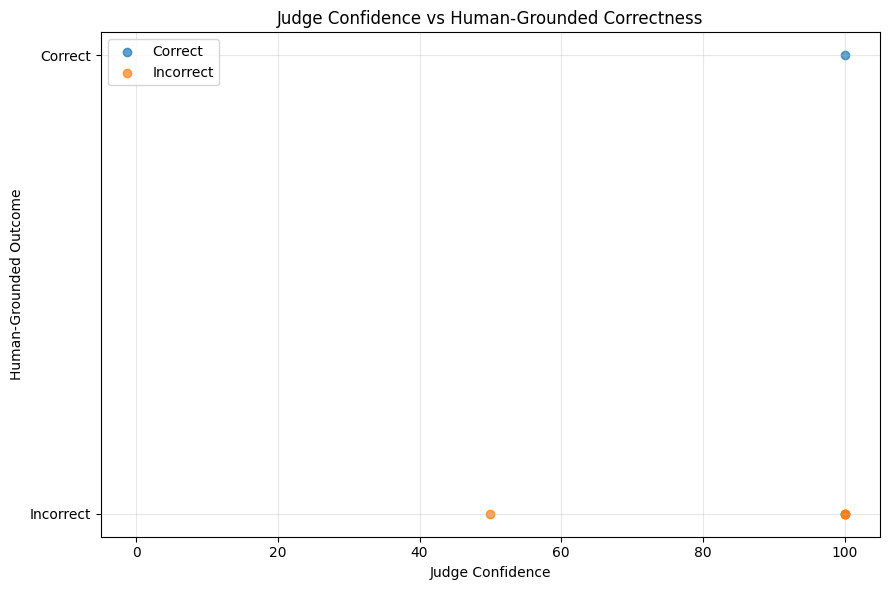

In [ ]:
# ============================================
# CELL 26: CONFIDENCE VS ACTUAL OUTCOME
# ============================================

if len(confidence_calibration) > 0:

    plt.figure(
        figsize=(9, 6)
    )


    correct_cases = (
        confidence_calibration[
            confidence_calibration[
                "initial_correct"
            ] == True
        ]
    )


    error_cases = (
        confidence_calibration[
            confidence_calibration[
                "initial_correct"
            ] == False
        ]
    )


    plt.scatter(

        correct_cases[
            "confidence"
        ],

        np.ones(
            len(correct_cases)
        ),

        alpha=0.7,

        label="Correct"
    )


    plt.scatter(

        error_cases[
            "confidence"
        ],

        np.zeros(
            len(error_cases)
        ),

        alpha=0.7,

        label="Incorrect"
    )


    plt.yticks(
        [0, 1],
        [
            "Incorrect",
            "Correct"
        ]
    )


    plt.xlabel(
        "Judge Confidence"
    )

    plt.ylabel(
        "Human-Grounded Outcome"
    )


    plt.title(
        "Judge Confidence vs Human-Grounded Correctness"
    )


    plt.xlim(
        -5,
        105
    )


    plt.grid(
        alpha=0.3
    )


    plt.legend()

    plt.tight_layout()


    plt.savefig(
        "results/calibration_confidence_vs_human.png",
        dpi=300
    )


    plt.show()

else:

    print(
        "No valid confidence-grounded cases."
    )

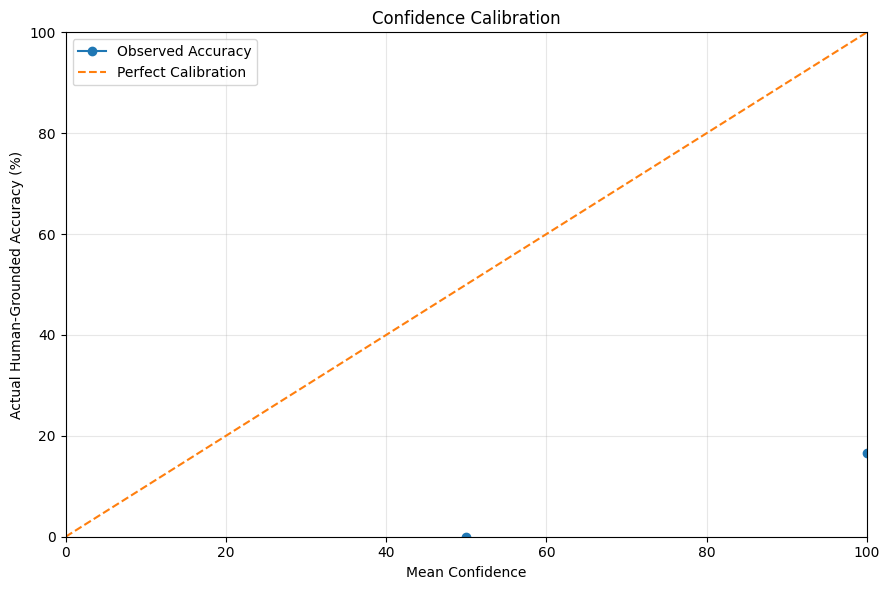

In [ ]:
# ============================================
# CELL 27: CONFIDENCE BIN CALIBRATION PLOT
# ============================================

if len(confidence_bin_summary) > 0:

    plt.figure(
        figsize=(9, 6)
    )


    plt.plot(

        confidence_bin_summary[
            "mean_confidence"
        ],

        confidence_bin_summary[
            "actual_accuracy"
        ],

        marker="o",

        label="Observed Accuracy"
    )


    plt.plot(

        [0, 100],

        [0, 100],

        linestyle="--",

        label="Perfect Calibration"
    )


    plt.xlabel(
        "Mean Confidence"
    )

    plt.ylabel(
        "Actual Human-Grounded Accuracy (%)"
    )


    plt.title(
        "Confidence Calibration"
    )


    plt.xlim(
        0,
        100
    )

    plt.ylim(
        0,
        100
    )


    plt.grid(
        alpha=0.3
    )


    plt.legend()

    plt.tight_layout()


    plt.savefig(
        "results/calibration_confidence_bins.png",
        dpi=300
    )


    plt.show()

In [ ]:
# ============================================
# CELL 28: SAVE CALIBRATION RESULTS
# ============================================

calibration_df.to_csv(
    "results/calibration_results.csv",
    index=False
)


calibration_summary.to_csv(
    "results/calibration_summary.csv",
    index=False
)


confidence_bin_summary.to_csv(
    "results/calibration_confidence_bins.csv",
    index=False
)


calibration_signal_summary.to_csv(
    "results/calibration_signal_summary.csv",
    index=False
)


judge_update_signals_df.to_csv(
    "results/judge_update_signals.csv",
    index=False
)


high_confidence_errors.to_csv(
    "results/high_confidence_errors.csv",
    index=False
)


print(
    "Calibration results saved:"
)

print(
    "✓ results/calibration_results.csv"
)

print(
    "✓ results/calibration_summary.csv"
)

print(
    "✓ results/calibration_confidence_bins.csv"
)

print(
    "✓ results/calibration_signal_summary.csv"
)

print(
    "✓ results/judge_update_signals.csv"
)

print(
    "✓ results/high_confidence_errors.csv"
)

print(
    "✓ results/calibration_confidence_vs_human.png"
)

print(
    "✓ results/calibration_confidence_bins.png"
)

Calibration results saved:
✓ results/calibration_results.csv
✓ results/calibration_summary.csv
✓ results/calibration_confidence_bins.csv
✓ results/calibration_signal_summary.csv
✓ results/judge_update_signals.csv
✓ results/high_confidence_errors.csv
✓ results/calibration_confidence_vs_human.png
✓ results/calibration_confidence_bins.png


In [ ]:
# ============================================
# CELL 29: FINAL INTEGRITY CHECK
# ============================================

print("=" * 70)
print("CALIBRATION FINAL INTEGRITY CHECK")
print("=" * 70)


print(
    "Total calibration cases:",
    len(calibration_df)
)

print(
    "Human-grounded cases:",
    len(confidence_calibration)
)

print(
    "Human-Judge accuracy:",
    f"{actual_accuracy:.2f}%"
)

print(
    "Mean confidence:",
    f"{mean_confidence:.2f}"
)

print(
    "Mean confidence-accuracy gap:",
    f"{mean_calibration_gap:.2f}"
)

print(
    "Brier score:",
    f"{brier_score:.4f}"
)

print(
    "\nOutput files:"
)


output_files = [

    "results/calibration_results.csv",

    "results/calibration_summary.csv",

    "results/calibration_confidence_bins.csv",

    "results/calibration_signal_summary.csv",

    "results/judge_update_signals.csv",

    "results/high_confidence_errors.csv",

    "results/calibration_confidence_vs_human.png",

    "results/calibration_confidence_bins.png"
]


for file_path in output_files:

    if os.path.exists(file_path):

        print(
            "✓",
            file_path
        )

    else:

        print(
            "✗ MISSING:",
            file_path
        )


print(
    "\nCalibration module completed successfully."
)

CALIBRATION FINAL INTEGRITY CHECK
Total calibration cases: 80
Human-grounded cases: 7
Human-Judge accuracy: 14.29%
Mean confidence: 92.86
Mean confidence-accuracy gap: 78.57
Brier score: 0.7500

Output files:
✓ results/calibration_results.csv
✓ results/calibration_summary.csv
✓ results/calibration_confidence_bins.csv
✓ results/calibration_signal_summary.csv
✓ results/judge_update_signals.csv
✓ results/high_confidence_errors.csv
✓ results/calibration_confidence_vs_human.png
✓ results/calibration_confidence_bins.png

Calibration module completed successfully.


# JUDGE UPDATE

In [ ]:
# ============================================
# JUDGE UPDATE MODULE
# CELL 1: INITIALIZATION
# ============================================

import os
import re
import json
import numpy as np
import pandas as pd

os.makedirs("results", exist_ok=True)

print("Judge Update module initialized.")

Judge Update module initialized.


In [ ]:
# ============================================
# CELL 2: CHECK PREVIOUS MODULES
# ============================================

required_objects = [
    "evaluation_rubric",
    "self_critique_df",
    "reliability_df",
    "position_df",
    "verbosity_df",
    "calibration_df",
    "calibration_summary",
    "judge_update_signals_df"
]

print("Checking previous modules...\n")

for obj in required_objects:

    if obj in globals():

        print(
            f"✓ {obj}: available"
        )

    else:

        print(
            f"✗ {obj}: NOT FOUND"
        )

Checking previous modules...

✓ evaluation_rubric: available
✓ self_critique_df: available
✓ reliability_df: available
✓ position_df: available
✓ verbosity_df: available
✓ calibration_df: available
✓ calibration_summary: available
✓ judge_update_signals_df: available


In [ ]:
# ============================================
# CELL 3: LOAD CALIBRATION OUTPUTS
# ============================================

if "calibration_df" not in globals():

    calibration_df = pd.read_csv(
        "results/calibration_results.csv"
    )

if "calibration_summary" not in globals():

    calibration_summary = pd.read_csv(
        "results/calibration_summary.csv"
    )

if "judge_update_signals_df" not in globals():

    judge_update_signals_df = pd.read_csv(
        "results/judge_update_signals.csv"
    )

print(
    "Calibration outputs loaded successfully."
)

print(
    "Calibration records:",
    len(calibration_df)
)

Calibration outputs loaded successfully.
Calibration records: 80


In [ ]:
# ============================================
# CELL 4: VALIDATE QUESTION ID ALIGNMENT
# ============================================

def validate_unique_ids(df, name):

    if "question_id" not in df.columns:

        raise ValueError(
            f"{name} does not contain question_id."
        )

    duplicate_count = (
        df["question_id"]
        .duplicated()
        .sum()
    )

    print(
        f"{name}: {len(df)} records | "
        f"duplicates: {duplicate_count}"
    )

    if duplicate_count > 0:

        raise ValueError(
            f"{name} contains duplicate question_id values."
        )


validate_unique_ids(
    self_critique_df,
    "Self-Critique"
)

validate_unique_ids(
    reliability_df,
    "Reliability"
)

validate_unique_ids(
    position_df,
    "Position"
)

validate_unique_ids(
    verbosity_df,
    "Verbosity"
)

validate_unique_ids(
    calibration_df,
    "Calibration"
)

print(
    "\n✓ Question ID validation completed."
)

Self-Critique: 80 records | duplicates: 0
Reliability: 80 records | duplicates: 0
Position: 80 records | duplicates: 0
Verbosity: 80 records | duplicates: 0
Calibration: 80 records | duplicates: 0

✓ Question ID validation completed.


In [ ]:
# ============================================
# CELL 5: SELF-CRITIQUE EVIDENCE
# ============================================

self_critique_update = {}

error_text = (
    self_critique_df[
        "detected_errors"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

bias_text = (
    self_critique_df[
        "detected_biases"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

self_critique_update[
    "total_cases"
] = len(self_critique_df)

self_critique_update[
    "error_signal_cases"
] = (
    ~error_text.isin(
        ["", "NONE", "NONE."]
    )
).sum()

self_critique_update[
    "bias_signal_cases"
] = (
    ~bias_text.isin(
        ["", "NONE", "NONE."]
    )
).sum()

print("SELF-CRITIQUE EVIDENCE")
print("======================")

print(
    "Total cases:",
    self_critique_update["total_cases"]
)

print(
    "Error signals:",
    self_critique_update["error_signal_cases"]
)

print(
    "Bias signals:",
    self_critique_update["bias_signal_cases"]
)

print(
    "\nNote: These are model-generated signals, "
    "not independently verified errors."
)

SELF-CRITIQUE EVIDENCE
Total cases: 80
Error signals: 25
Bias signals: 25

Note: These are model-generated signals, not independently verified errors.


In [ ]:
# ============================================
# CELL 6: HUMAN-GROUNDED BEFORE/AFTER ANALYSIS
# ============================================

required_calibration_columns = [
    "initial_correct",
    "revised_correct",
    "initial_decision",
    "revised_decision",
    "human_winner"
]

missing = [
    col
    for col in required_calibration_columns
    if col not in calibration_df.columns
]

if missing:

    raise ValueError(
        f"Missing calibration columns: {missing}"
    )


initial_valid = calibration_df[
    calibration_df[
        "initial_correct"
    ].notna()
].copy()


revised_valid = calibration_df[
    calibration_df[
        "revised_correct"
    ].notna()
].copy()


initial_accuracy = (
    initial_valid[
        "initial_correct"
    ].mean()
    * 100
)


revised_accuracy = (
    revised_valid[
        "revised_correct"
    ].mean()
    * 100
)


calibration_df[
    "self_critique_fixed_error"
] = (
    (calibration_df["initial_correct"] == False)
    &
    (calibration_df["revised_correct"] == True)
)


calibration_df[
    "self_critique_introduced_error"
] = (
    (calibration_df["initial_correct"] == True)
    &
    (calibration_df["revised_correct"] == False)
)


fixed_errors = calibration_df[
    "self_critique_fixed_error"
].sum()


introduced_errors = calibration_df[
    "self_critique_introduced_error"
].sum()


print("HUMAN-GROUNDED UPDATE ANALYSIS")
print("==============================")

print(
    f"Initial accuracy: {initial_accuracy:.2f}%"
)

print(
    f"Revised accuracy: {revised_accuracy:.2f}%"
)

print(
    f"Accuracy change: "
    f"{revised_accuracy - initial_accuracy:.2f} percentage points"
)

print(
    "Errors fixed by self-critique:",
    fixed_errors
)

print(
    "Errors introduced by self-critique:",
    introduced_errors
)

HUMAN-GROUNDED UPDATE ANALYSIS
Initial accuracy: 37.50%
Revised accuracy: 6.25%
Accuracy change: -31.25 percentage points
Errors fixed by self-critique: 2
Errors introduced by self-critique: 27


In [ ]:
# ============================================
# CELL 7: CALIBRATION EVIDENCE
# ============================================

def get_metric(df, metric_name):

    row = df[
        df["Metric"] == metric_name
    ]

    if len(row) == 0:

        return np.nan

    return row.iloc[0]["Value"]


mean_confidence = get_metric(
    calibration_summary,
    "Mean Confidence"
)

mean_calibration_gap = get_metric(
    calibration_summary,
    "Mean Confidence-Accuracy Gap"
)

brier_score = get_metric(
    calibration_summary,
    "Brier Score"
)

high_confidence_errors = get_metric(
    calibration_summary,
    "High-Confidence Errors"
)


print("CALIBRATION EVIDENCE")
print("====================")

print(
    f"Mean confidence: {mean_confidence}"
)

print(
    f"Confidence-accuracy gap: "
    f"{mean_calibration_gap}"
)

print(
    f"Brier score: {brier_score}"
)

print(
    f"High-confidence errors: "
    f"{high_confidence_errors}"
)

CALIBRATION EVIDENCE
Mean confidence: 92.85714285714286
Confidence-accuracy gap: 78.57142857142858
Brier score: 0.75
High-confidence errors: 5.0


In [ ]:
# ============================================
# CELL 8: POSITION SENSITIVITY
# ============================================

position_analysis = {}

position_analysis[
    "total_cases"
] = len(position_df)

position_analysis[
    "consistent_cases"
] = (
    position_df[
        "position_consistent"
    ]
    .fillna(False)
    .sum()
)

position_analysis[
    "sensitive_cases"
] = (
    ~position_df[
        "position_consistent"
    ]
    .fillna(True)
).sum()


if position_analysis["total_cases"] > 0:

    position_analysis[
        "consistency_rate"
    ] = (
        position_analysis[
            "consistent_cases"
        ]
        /
        position_analysis[
            "total_cases"
        ]
        *
        100
    )

else:

    position_analysis[
        "consistency_rate"
    ] = np.nan


print("POSITION SENSITIVITY")
print("====================")

print(
    "Total:",
    position_analysis["total_cases"]
)

print(
    "Consistent:",
    position_analysis["consistent_cases"]
)

print(
    "Position-sensitive:",
    position_analysis["sensitive_cases"]
)

print(
    f"Consistency rate: "
    f"{position_analysis['consistency_rate']:.2f}%"
)

print(
    "\nInterpretation: position sensitivity is treated "
    "as evidence for review, not automatic proof of bias."
)

POSITION SENSITIVITY
Total: 80
Consistent: 17
Position-sensitive: 39
Consistency rate: 21.25%

Interpretation: position sensitivity is treated as evidence for review, not automatic proof of bias.


/tmp/ipykernel_854/1817212222.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_854/1817212222.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(True)


In [ ]:

# ============================================
# CELL 9: VERBOSITY SENSITIVITY
# ============================================

verbosity_counts = (
    verbosity_results_df[
        "winner"
    ]
    .fillna("UNKNOWN")
    .astype(str)
    .str.upper()
    .value_counts()
)

print("VERBOSITY EVIDENCE")
print("==================")

print(verbosity_counts)

verbosity_preference_cases = (
    verbosity_results_df[
        "winner"
    ]
    .fillna("UNKNOWN")
    .astype(str)
    .str.upper()
    .isin(["SHORT", "LONG"])
    .sum()
)

print(
    "\nDirectional verbosity preferences:",
    verbosity_preference_cases
)

print(
    "TIE cases:",
    verbosity_counts.get("TIE", 0)
)

print(
    "\nInterpretation: this is preference evidence, "
    "not automatic proof of verbosity bias."
)


VERBOSITY EVIDENCE
winner
LONG       30
SHORT      24
UNKNOWN    16
TIE        10
Name: count, dtype: int64

Directional verbosity preferences: 54
TIE cases: 10

Interpretation: this is preference evidence, not automatic proof of verbosity bias.


In [ ]:
# ============================================
# CELL 10: EVIDENCE-BASED UPDATE SIGNALS
# ============================================

update_signals = {

    "human_grounded_performance_change":
        revised_accuracy != initial_accuracy,

    "self_critique_error_signal":
        self_critique_update[
            "error_signal_cases"
        ] > 0,

    "self_critique_bias_signal":
        self_critique_update[
            "bias_signal_cases"
        ] > 0,

    "position_sensitivity_evidence":
        position_analysis[
            "sensitive_cases"
        ] > 0,

    "verbosity_sensitivity_evidence":
        verbosity_preference_cases > 0,

    "high_confidence_error_evidence":
        (
            pd.notna(high_confidence_errors)
            and
            high_confidence_errors > 0
        )
}


print("JUDGE UPDATE EVIDENCE")
print("=====================")

for key, value in update_signals.items():

    print(
        f"{key}: {value}"
    )

JUDGE UPDATE EVIDENCE
human_grounded_performance_change: True
self_critique_error_signal: True
self_critique_bias_signal: True
position_sensitivity_evidence: True
verbosity_sensitivity_evidence: True
high_confidence_error_evidence: True


In [ ]:
# ============================================
# CELL 11: UPDATED EVALUATION RUBRIC
# ============================================

updated_rubric = {

    "Correctness":
        (
            "Evaluate factual accuracy, logical validity, "
            "and whether the answer reaches the correct conclusion."
        ),

    "Relevance":
        (
            "Evaluate whether the answer directly addresses "
            "the question without unnecessary or unrelated content."
        ),

    "Clarity":
        (
            "Evaluate whether the answer is clear, understandable, "
            "well structured, and logically presented."
        ),

    "Completeness":
        (
            "Evaluate whether the answer satisfies the important "
            "requirements of the question."
        ),

    "Instruction Following":
        (
            "Check whether the answer follows all explicit "
            "instructions and constraints."
        ),

    "Position Neutrality":
        (
            "Evaluate each answer independently of whether it "
            "appears as Answer A or Answer B."
        ),

    "Verbosity Neutrality":
        (
            "Do not reward or penalize an answer merely for being "
            "longer or shorter. Additional detail should improve "
            "the answer only when relevant, correct, and useful."
        ),

    "Evidence Based Decision":
        (
            "Base the final decision on the strongest evidence "
            "from the rubric rather than superficial features."
        )
}


print("UPDATED RUBRIC")
print("==============")

for criterion, description in updated_rubric.items():

    print(
        f"\n{criterion}:\n{description}"
    )

UPDATED RUBRIC

Correctness:
Evaluate factual accuracy, logical validity, and whether the answer reaches the correct conclusion.

Relevance:
Evaluate whether the answer directly addresses the question without unnecessary or unrelated content.

Clarity:
Evaluate whether the answer is clear, understandable, well structured, and logically presented.

Completeness:
Evaluate whether the answer satisfies the important requirements of the question.

Instruction Following:
Check whether the answer follows all explicit instructions and constraints.

Position Neutrality:
Evaluate each answer independently of whether it appears as Answer A or Answer B.

Verbosity Neutrality:
Do not reward or penalize an answer merely for being longer or shorter. Additional detail should improve the answer only when relevant, correct, and useful.

Evidence Based Decision:
Base the final decision on the strongest evidence from the rubric rather than superficial features.


In [ ]:
# ============================================
# CELL 12: UPDATED REASONING STRATEGY
# ============================================

reasoning_strategy = [

    "Understand the question and explicit requirements.",

    "Evaluate Answer A independently.",

    "Evaluate Answer B independently.",

    "Check factual and logical correctness.",

    "Check relevance and completeness.",

    "Check instruction following.",

    "Compare the strongest evidence for A and B.",

    "Check whether position affects the judgment.",

    "Check whether length affects the judgment without adding value.",

    "Verify that the final decision is supported by the evaluation.",

    "Assign confidence according to the strength and consistency of evidence.",

    "Return the final decision in the required format."
]


for step in reasoning_strategy:

    print(step)

Understand the question and explicit requirements.
Evaluate Answer A independently.
Evaluate Answer B independently.
Check factual and logical correctness.
Check relevance and completeness.
Check instruction following.
Compare the strongest evidence for A and B.
Check whether position affects the judgment.
Check whether length affects the judgment without adding value.
Verify that the final decision is supported by the evaluation.
Assign confidence according to the strength and consistency of evidence.
Return the final decision in the required format.


In [ ]:
# ============================================
# CELL 13: UPDATED JUDGE PROMPT
# ============================================

def create_updated_judge_prompt(
    question,
    answer_a,
    answer_b
):

    rubric_text = "\n".join(
        [
            f"{i+1}. {key}: {value}"
            for i, (key, value)
            in enumerate(
                updated_rubric.items()
            )
        ]
    )

    prompt = f"""
You are an impartial LLM judge.

Compare Answer A and Answer B for the given question.

IMPORTANT:

- Evaluate Answer A independently.
- Evaluate Answer B independently.
- Do not prefer an answer because it appears first.
- Do not prefer an answer because it is longer.
- Do not prefer an answer because it is shorter.
- Reward additional detail only when it is relevant, correct,
  and useful.
- Apply exactly the same criteria to both answers.
- Check factual and logical correctness.
- Check whether the answer satisfies the user's instructions.
- Before the final decision, verify that your reasoning supports it.

QUESTION:
{question}

ANSWER A:
{answer_a}

ANSWER B:
{answer_b}

RUBRIC:
{rubric_text}

SCORING:

Give each answer a score from 1 to 10 for:

Correctness
Relevance
Clarity
Completeness
Instruction Following

Then calculate:

SCORE A = average of the five criteria.

SCORE B = average of the five criteria.

DECISION RULE:

- If SCORE A > SCORE B, choose A.
- If SCORE B > SCORE A, choose B.
- If the scores are equal, choose TIE.

Do NOT use any other decision rule.

FINAL OUTPUT FORMAT:

ANALYSIS:
<brief comparison>

CORRECTNESS A: <number>
RELEVANCE A: <number>
CLARITY A: <number>
COMPLETENESS A: <number>
INSTRUCTION FOLLOWING A: <number>

CORRECTNESS B: <number>
RELEVANCE B: <number>
CLARITY B: <number>
COMPLETENESS B: <number>
INSTRUCTION FOLLOWING B: <number>

SCORE A: <number>
SCORE B: <number>

FINAL DECISION: <A/B/TIE>

FINAL REASON: <brief reason>

CONFIDENCE: <number from 0 to 100>

Return ONLY the requested fields.
"""

    return prompt

In [ ]:
# ============================================
# CELL 14: RUN UPDATED JUDGE
# ============================================

def run_updated_judge(
    question,
    answer_a,
    answer_b,
    max_new_tokens=450
):

    prompt = create_updated_judge_prompt(
        question,
        answer_a,
        answer_b
    )

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = (
        judge_tokenizer
        .apply_chat_template(
            messages,
            return_tensors="pt",
            add_generation_prompt=True
        )
        .to(judge_llm.device)
    )

    input_length = (
        inputs["input_ids"].shape[-1]
    )

    outputs = judge_llm.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=(
            judge_tokenizer.eos_token_id
        )
    )

    output_text = (
        judge_tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )
    )

    return output_text.strip()

In [ ]:
# ============================================
# CELL 15: ROBUST OUTPUT PARSER
# ============================================

def extract_number(
    text,
    patterns
):

    for pattern in patterns:

        match = re.search(
            pattern,
            text,
            re.IGNORECASE
        )

        if match:

            try:
                return float(
                    match.group(1)
                )

            except:
                pass

    return np.nan


def parse_updated_judge(text):

    if not isinstance(text, str):

        return {
            "decision": None,
            "confidence": np.nan,
            "score_a": np.nan,
            "score_b": np.nan
        }


    # -------------------------
    # Decision
    # -------------------------

    decision_patterns = [

        r"FINAL\s+DECISION\s*[:\-]\s*\**\s*(A|B|TIE)\b",

        r"DECISION\s*[:\-]\s*\**\s*(A|B|TIE)\b",

        r"\bFINAL\s+DECISION\b.*?\b(A|B|TIE)\b"

    ]


    decision = None

    for pattern in decision_patterns:

        match = re.search(
            pattern,
            text,
            re.IGNORECASE |
            re.DOTALL
        )

        if match:

            decision = (
                match.group(1)
                .upper()
            )

            break


    # -------------------------
    # Confidence
    # -------------------------

    confidence = extract_number(
        text,
        [
            r"CONFIDENCE\s*[:\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"CONFIDENCE\s+SCORE\s*[:\-]\s*\**\s*(\d+(?:\.\d+)?)"
        ]
    )


    # -------------------------
    # Score A
    # -------------------------

    score_a = extract_number(
        text,
        [
            r"SCORE\s+A\s*[:\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"TOTAL\s+SCORE\s+A\s*[:\-]\s*\**\s*(\d+(?:\.\d+)?)"
        ]
    )


    # -------------------------
    # Score B
    # -------------------------

    score_b = extract_number(
        text,
        [
            r"SCORE\s+B\s*[:\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"TOTAL\s+SCORE\s+B\s*[:\-]\s*\**\s*(\d+(?:\.\d+)?)"
        ]
    )


    if pd.notna(confidence):

        confidence = np.clip(
            confidence,
            0,
            100
        )


    return {

        "decision": decision,

        "confidence": confidence,

        "score_a": score_a,

        "score_b": score_b
    }

In [ ]:
# ============================================
# CELL 16: TEST UPDATED PARSER
# ============================================

test_output = """
ANALYSIS:
Answer B is more complete.

CORRECTNESS A: 8
RELEVANCE A: 9
CLARITY A: 8
COMPLETENESS A: 7
INSTRUCTION FOLLOWING A: 9

CORRECTNESS B: 9
RELEVANCE B: 9
CLARITY B: 9
COMPLETENESS B: 9
INSTRUCTION FOLLOWING B: 9

SCORE A: 8.2
SCORE B: 9.0

FINAL DECISION: B

FINAL REASON: Answer B is more complete.

CONFIDENCE: 90
"""


parsed_test = parse_updated_judge(
    test_output
)

print(
    json.dumps(
        parsed_test,
        indent=2
    )
)

{
  "decision": "B",
  "confidence": 90.0,
  "score_a": 8.2,
  "score_b": 9.0
}


In [ ]:
# ============================================
# CELL 17: TEST ONE REAL SAMPLE
# ============================================

sample = candidate_answers[0]

sample_output = run_updated_judge(
    sample["question"],
    sample["answer_a"],
    sample["answer_b"]
)

print(sample_output)

print("\n" + "=" * 60)
print("PARSED RESULT")
print("=" * 60)

sample_parsed = parse_updated_judge(
    sample_output
)

print(
    json.dumps(
        sample_parsed,
        indent=2
    )
)

ANALYSIS:
Correctness A: 8/10
Relevance A: 9/10
Clarity A: 9/10
Completeness A: 9/10
Instruction Following A: 9/10

Correctness B: 7/10
Relevance B: 8/10
Clarity B: 8/10
Completeness B: 8/10
Instruction Following B: 8/10

SCORE A: 8.4
SCORE B: 7.6

FINAL DECISION: A

PARSED RESULT
{
  "decision": "A",
  "confidence": NaN,
  "score_a": 8.4,
  "score_b": 7.6
}


In [ ]:
# ============================================
# CELL 18: RUN UPDATED JUDGE ON ALL CASES
# WITH CHECKPOINT / RESUME
# ============================================

import os
import json
import pandas as pd

from pathlib import Path

# Checkpoint path
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/LLM_Judge/checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_FILE = (
    CHECKPOINT_DIR / "updated_judge_results.json"
)


# --------------------------------------------
# 1. LOAD EXISTING CHECKPOINT
# --------------------------------------------

if CHECKPOINT_FILE.exists():

    with open(
        CHECKPOINT_FILE,
        "r",
        encoding="utf-8"
    ) as f:
        updated_judge_results = json.load(f)

    print(
        "Loaded checkpoint:",
        len(updated_judge_results),
        "records"
    )

else:

    updated_judge_results = []

    print("No checkpoint found. Starting fresh.")


# Completed question IDs
completed_ids = {
    str(row["question_id"])
    for row in updated_judge_results
}


# --------------------------------------------
# 2. ATOMIC CHECKPOINT SAVE
# --------------------------------------------

def save_updated_judge_checkpoint(results):

    temp_file = CHECKPOINT_FILE.with_suffix(".tmp")

    with open(
        temp_file,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            ensure_ascii=False,
            indent=2
        )

        f.flush()
        os.fsync(f.fileno())

    os.replace(
        temp_file,
        CHECKPOINT_FILE
    )


# --------------------------------------------
# 3. RUN UPDATED JUDGE
# --------------------------------------------

for i, item in enumerate(candidate_answers):

    question_id = str(item["question_id"])

    # Skip already completed cases
    if question_id in completed_ids:
        continue

    try:

        output_text = run_updated_judge(
            item["question"],
            item["answer_a"],
            item["answer_b"]
        )

        parsed = parse_updated_judge(
            output_text
        )

        result = {
            "question_id": item["question_id"],
            "category": item["category"],
            "decision": parsed["decision"],
            "confidence": parsed["confidence"],
            "score_a": parsed["score_a"],
            "score_b": parsed["score_b"],
            "judge_output": output_text
        }

        updated_judge_results.append(result)

        completed_ids.add(question_id)

        # Save after every successful case
        save_updated_judge_checkpoint(
            updated_judge_results
        )

        if len(updated_judge_results) % 10 == 0:

            print(
                f"Processed "
                f"{len(updated_judge_results)}/"
                f"{len(candidate_answers)}"
            )

    except Exception as e:

        # Preserve completed work before stopping
        save_updated_judge_checkpoint(
            updated_judge_results
        )

        print(
            f"\nError at question_id={question_id}: {e}"
        )

        print(
            "Checkpoint saved. Re-run this cell to resume."
        )

        raise


# --------------------------------------------
# 4. FINAL DATAFRAME
# --------------------------------------------

updated_judge_df = pd.DataFrame(
    updated_judge_results
)

# Restore input order
question_order = {
    str(item["question_id"]): idx
    for idx, item in enumerate(candidate_answers)
}

if not updated_judge_df.empty:

    updated_judge_df["_order"] = (
        updated_judge_df["question_id"]
        .astype(str)
        .map(question_order)
    )

    updated_judge_df = (
        updated_judge_df
        .sort_values("_order")
        .drop(columns="_order")
        .reset_index(drop=True)
    )

print(
    "\nUpdated judge records:",
    len(updated_judge_df)
)

print(
    "Checkpoint:",
    CHECKPOINT_FILE
)

display(updated_judge_df.head())

No checkpoint found. Starting fresh.
Processed 10/80
Processed 20/80
Processed 30/80
Processed 40/80
Processed 50/80
Processed 60/80
Processed 70/80
Processed 80/80

Updated judge records: 80
Checkpoint: /content/drive/MyDrive/LLM_Judge/checkpoints/updated_judge_results.json


,question_id,category,decision,confidence,score_a,score_b,judge_output
0,81,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
1,82,writing,TIE,NaN,8.0,7.5,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...
2,83,writing,A,95.0,8.4,9.1,**Analysis**\n\nAnswer A: Correctness - 8/10 (...
3,84,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
4,85,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...


In [ ]:
# ============================================
# CELL 19: PARSE QUALITY CHECK
# ============================================

total = len(
    updated_judge_df
)

decision_parsed = (
    updated_judge_df[
        "decision"
    ]
    .notna()
    .sum()
)

confidence_parsed = (
    updated_judge_df[
        "confidence"
    ]
    .notna()
    .sum()
)

score_a_parsed = (
    updated_judge_df[
        "score_a"
    ]
    .notna()
    .sum()
)

score_b_parsed = (
    updated_judge_df[
        "score_b"
    ]
    .notna()
    .sum()
)


print("PARSING QUALITY")
print("===============")

print(
    f"Decision parsed: "
    f"{decision_parsed}/{total} "
    f"({decision_parsed/total*100:.2f}%)"
)

print(
    f"Confidence parsed: "
    f"{confidence_parsed}/{total} "
    f"({confidence_parsed/total*100:.2f}%)"
)

print(
    f"Score A parsed: "
    f"{score_a_parsed}/{total} "
    f"({score_a_parsed/total*100:.2f}%)"
)

print(
    f"Score B parsed: "
    f"{score_b_parsed}/{total} "
    f"({score_b_parsed/total*100:.2f}%)"
)

PARSING QUALITY
Decision parsed: 76/80 (95.00%)
Confidence parsed: 3/80 (3.75%)
Score A parsed: 62/80 (77.50%)
Score B parsed: 62/80 (77.50%)


In [ ]:
# ============================================
# CELL 20: UPDATED DECISION DISTRIBUTION
# ============================================

print(
    "UPDATED JUDGE DECISIONS"
)

print(
    "======================="
)

print(
    updated_judge_df[
        "decision"
    ]
    .value_counts(
        dropna=False
    )
)


print(
    "\nUPDATED CONFIDENCE"
)

print(
    updated_judge_df[
        "confidence"
    ]
    .describe()
)

UPDATED JUDGE DECISIONS
decision
A       38
TIE     25
B       13
None     4
Name: count, dtype: int64

UPDATED CONFIDENCE
count      3.000000
mean      96.666667
std        2.886751
min       95.000000
25%       95.000000
50%       95.000000
75%       97.500000
max      100.000000
Name: confidence, dtype: float64


In [ ]:
# ============================================
# CELL 21: UPDATED JUDGE VS HUMAN
# ============================================

human_ground_truth = (
    calibration_df[
        [
            "question_id",
            "human_winner"
        ]
    ]
    .drop_duplicates(
        "question_id"
    )
)


updated_evaluation = (
    updated_judge_df
    .merge(
        human_ground_truth,
        on="question_id",
        how="left"
    )
)


updated_evaluation[
    "human_correct"
] = (
    updated_evaluation[
        "decision"
    ]
    ==
    updated_evaluation[
        "human_winner"
    ]
)


valid_updated = updated_evaluation[
    updated_evaluation[
        "decision"
    ].notna()
    &
    updated_evaluation[
        "human_winner"
    ].isin(["A", "B"])
].copy()


updated_accuracy = (
    valid_updated[
        "human_correct"
    ].mean()
    * 100
)


print(
    "UPDATED JUDGE HUMAN-GROUNDED PERFORMANCE"
)

print(
    "========================================="
)

print(
    "Valid comparisons:",
    len(valid_updated)
)

print(
    f"Updated Judge Accuracy: "
    f"{updated_accuracy:.2f}%"
)

print(
    f"Original Judge Accuracy: "
    f"{initial_accuracy:.2f}%"
)

print(
    f"Performance change: "
    f"{updated_accuracy - initial_accuracy:.2f} "
    f"percentage points"
)

UPDATED JUDGE HUMAN-GROUNDED PERFORMANCE
Valid comparisons: 76
Updated Judge Accuracy: 42.11%
Original Judge Accuracy: 37.50%
Performance change: 4.61 percentage points


In [ ]:
# ============================================
# CELL 22: ORIGINAL VS UPDATED JUDGE
# ============================================

original_decisions = (
    calibration_df[
        [
            "question_id",
            "initial_decision",
            "human_winner",
            "initial_correct"
        ]
    ]
    .drop_duplicates(
        "question_id"
    )
)


comparison_df = (
    original_decisions
    .merge(
        updated_evaluation[
            [
                "question_id",
                "decision",
                "human_correct"
            ]
        ],
        on="question_id",
        how="left"
    )
)


comparison_df[
    "updated_fixed_error"
] = (
    (comparison_df["initial_correct"] == False)
    &
    (comparison_df["human_correct"] == True)
)


comparison_df[
    "updated_introduced_error"
] = (
    (comparison_df["initial_correct"] == True)
    &
    (comparison_df["human_correct"] == False)
)


print(
    "UPDATED JUDGE IMPACT"
)

print(
    "===================="
)

print(
    "Errors fixed:",
    comparison_df[
        "updated_fixed_error"
    ].sum()
)

print(
    "Errors introduced:",
    comparison_df[
        "updated_introduced_error"
    ].sum()
)

UPDATED JUDGE IMPACT
Errors fixed: 19
Errors introduced: 17


In [ ]:
# ============================================
# CELL 23: SAVE UPDATED JUDGE RESULTS
# ============================================

updated_judge_df.to_csv(
    "results/updated_judge_results.csv",
    index=False
)

updated_judge_df.to_json(
    "results/updated_judge_results.json",
    orient="records",
    indent=2
)

updated_evaluation.to_csv(
    "results/updated_judge_human_evaluation.csv",
    index=False
)

comparison_df.to_csv(
    "results/original_vs_updated_judge.csv",
    index=False
)


print("Saved:")

print(
    "✓ results/updated_judge_results.csv"
)

print(
    "✓ results/updated_judge_results.json"
)

print(
    "✓ results/updated_judge_human_evaluation.csv"
)

print(
    "✓ results/original_vs_updated_judge.csv"
)

Saved:
✓ results/updated_judge_results.csv
✓ results/updated_judge_results.json
✓ results/updated_judge_human_evaluation.csv
✓ results/original_vs_updated_judge.csv


In [ ]:
# ============================================
# CELL 24: SAVE JUDGE UPDATE CONFIGURATION
# ============================================

judge_update_config = {

    "module":
        "Evidence-Based Judge Update",

    "updated_rubric":
        updated_rubric,

    "reasoning_strategy":
        reasoning_strategy,

    "update_evidence": {

        "initial_human_accuracy":
            float(initial_accuracy),

        "revised_self_critique_accuracy":
            float(revised_accuracy),

        "updated_judge_accuracy":
            float(updated_accuracy),

        "self_critique_fixed_errors":
            int(fixed_errors),

        "self_critique_introduced_errors":
            int(introduced_errors),

        "position_sensitive_cases":
            int(
                position_analysis[
                    "sensitive_cases"
                ]
            ),

        "verbosity_preference_cases":
            int(
                verbosity_preference_cases
            ),

        "high_confidence_errors":
            int(
                high_confidence_errors
            )
            if pd.notna(
                high_confidence_errors
            )
            else None
    },

    "decision_rule":
        "Choose the answer with the higher mean of the five core rubric scores; choose TIE only when the two mean scores are equal.",

    "position_policy":
        "Position sensitivity is treated as diagnostic evidence, not as an automatic bias penalty.",

    "verbosity_policy":
        "Verbosity preference is treated as diagnostic evidence, not as an automatic bias penalty.",

    "confidence_policy":
        "Confidence is evaluated against human-grounded correctness."
}


with open(
    "results/judge_update_config.json",
    "w"
) as f:

    json.dump(
        judge_update_config,
        f,
        indent=2
    )


print(
    "✓ results/judge_update_config.json saved."
)

✓ results/judge_update_config.json saved.


In [ ]:
# ============================================
# CELL 25: FINAL INTEGRITY CHECK
# ============================================

print("=" * 70)
print("JUDGE UPDATE FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    "Total updated judge cases:",
    len(updated_judge_df)
)

print(
    "Decision parsed:",
    updated_judge_df[
        "decision"
    ].notna().sum()
)

print(
    "Confidence parsed:",
    updated_judge_df[
        "confidence"
    ].notna().sum()
)

print(
    f"\nOriginal human accuracy: "
    f"{initial_accuracy:.2f}%"
)

print(
    f"Self-critique revised accuracy: "
    f"{revised_accuracy:.2f}%"
)

print(
    f"Updated Judge accuracy: "
    f"{updated_accuracy:.2f}%"
)

print(
    f"Updated vs Original: "
    f"{updated_accuracy - initial_accuracy:.2f} percentage points"
)


print("\nOutput files:")

output_files = [

    "results/updated_judge_results.csv",

    "results/updated_judge_results.json",

    "results/updated_judge_human_evaluation.csv",

    "results/original_vs_updated_judge.csv",

    "results/judge_update_config.json"
]


for file_path in output_files:

    if os.path.exists(file_path):

        print(
            "✓",
            file_path
        )

    else:

        print(
            "✗ MISSING:",
            file_path
        )


print(
    "\nJudge Update module completed."
)

JUDGE UPDATE FINAL INTEGRITY CHECK
Total updated judge cases: 80
Decision parsed: 76
Confidence parsed: 3

Original human accuracy: 37.50%
Self-critique revised accuracy: 6.25%
Updated Judge accuracy: 42.11%
Updated vs Original: 4.61 percentage points

Output files:
✓ results/updated_judge_results.csv
✓ results/updated_judge_results.json
✓ results/updated_judge_human_evaluation.csv
✓ results/original_vs_updated_judge.csv
✓ results/judge_update_config.json

Judge Update module completed.


# ***BETTER JUDGE***

In [ ]:
# ============================================
# BETTER JUDGE — REPAIRED MODULE
# CELL 1: INITIALIZATION
# ============================================

import os
import re
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

os.makedirs("results", exist_ok=True)

print("Repaired Better Judge module initialized.")

Repaired Better Judge module initialized.


In [ ]:
# ============================================
# CELL 2: LOAD UPDATED JUDGE RESULTS
# ============================================

updated_judge_df = pd.read_csv(
    "results/updated_judge_results.csv"
)

print("Updated Judge Results Loaded")
print("Total cases:", len(updated_judge_df))

display(
    updated_judge_df.head()
)

Updated Judge Results Loaded
Total cases: 80


,question_id,category,decision,confidence,score_a,score_b,judge_output
0,81,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
1,82,writing,TIE,NaN,8.0,7.5,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...
2,83,writing,A,95.0,8.4,9.1,**Analysis**\n\nAnswer A: Correctness - 8/10 (...
3,84,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
4,85,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...


In [ ]:
# ============================================
# CELL 3: LOAD HUMAN GROUND TRUTH
# ============================================

if "calibration_df" in globals():

    human_ground_truth = (
        calibration_df[
            [
                "question_id",
                "human_winner"
            ]
        ]
        .drop_duplicates(
            "question_id"
        )
        .copy()
    )

else:

    human_ground_truth = pd.read_csv(
        "results/calibration_external_feedback.csv"
    )

    human_ground_truth = (
        human_ground_truth[
            [
                "question_id",
                "human_winner"
            ]
        ]
        .drop_duplicates(
            "question_id"
        )
        .copy()
    )


human_ground_truth["human_winner"] = (
    human_ground_truth[
        "human_winner"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)


print(
    "Human ground-truth cases:",
    len(human_ground_truth)
)

print(
    human_ground_truth[
        "human_winner"
    ].value_counts(
        dropna=False
    )
)

Human ground-truth cases: 80
human_winner
A    47
B    33
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 4: VALIDATE QUESTION IDS
# ============================================

def validate_ids(df, name):

    if "question_id" not in df.columns:

        raise ValueError(
            f"{name} does not contain question_id."
        )

    duplicates = (
        df["question_id"]
        .duplicated()
        .sum()
    )

    print(
        f"{name}: {len(df)} rows | "
        f"duplicates: {duplicates}"
    )

    if duplicates > 0:

        raise ValueError(
            f"{name} contains duplicate question_id values."
        )


validate_ids(
    updated_judge_df,
    "Updated Judge"
)

validate_ids(
    human_ground_truth,
    "Human Ground Truth"
)

Updated Judge: 80 rows | duplicates: 0
Human Ground Truth: 80 rows | duplicates: 0


In [ ]:
# ============================================
# CELL 5: ROBUST UPDATED-JUDGE PARSER
# ============================================

CORE_CRITERIA = [
    "correctness",
    "relevance",
    "clarity",
    "completeness",
    "instruction_following"
]


def clean_text(text):

    if text is None:
        return ""

    return str(text).strip()


def normalize_decision(value):

    if value is None:
        return None

    text = str(value).strip().upper()

    if text in ["A", "B", "TIE"]:
        return text

    return None


def safe_float(value):

    try:
        value = float(value)

        if np.isfinite(value):
            return value

    except:
        pass

    return np.nan


def parse_updated_judge_output(raw_output):

    result = {
        "decision": None,
        "confidence": np.nan,
        "score_a": np.nan,
        "score_b": np.nan
    }

    text = clean_text(raw_output)

    if not text:
        return result


    # ========================================
    # 1. JSON EXTRACTION
    # ========================================

    json_candidates = []

    # Remove markdown fences
    cleaned = re.sub(
        r"```(?:json)?",
        "",
        text,
        flags=re.IGNORECASE
    )

    cleaned = cleaned.replace(
        "```",
        ""
    ).strip()


    # Find possible JSON object
    match = re.search(
        r"\{.*\}",
        cleaned,
        re.DOTALL
    )

    if match:

        json_candidates.append(
            match.group(0)
        )


    for candidate in json_candidates:

        try:

            data = json.loads(candidate)

            if isinstance(data, dict):

                # Decision
                for key in [
                    "final_decision",
                    "decision",
                    "winner"
                ]:

                    if key in data:

                        result["decision"] = (
                            normalize_decision(
                                data[key]
                            )
                        )

                        if result["decision"]:
                            break


                # Confidence
                for key in [
                    "confidence",
                    "confidence_score"
                ]:

                    if key in data:

                        result["confidence"] = (
                            safe_float(
                                data[key]
                            )
                        )

                        break


                # Direct scores
                for key in [
                    "score_a",
                    "overall_score_a"
                ]:

                    if key in data:

                        result["score_a"] = (
                            safe_float(
                                data[key]
                            )
                        )

                        break


                for key in [
                    "score_b",
                    "overall_score_b"
                ]:

                    if key in data:

                        result["score_b"] = (
                            safe_float(
                                data[key]
                            )
                        )

                        break

        except:
            pass


    # ========================================
    # 2. REGEX DECISION
    # ========================================

    if result["decision"] is None:

        decision_patterns = [

            r"FINAL\s+DECISION\s*[:=\-]\s*\**\s*(A|B|TIE)\b",

            r"DECISION\s*[:=\-]\s*\**\s*(A|B|TIE)\b",

            r"WINNER\s*[:=\-]\s*\**\s*(A|B|TIE)\b",

            r"PREFERRED\s+ANSWER\s*[:=\-]\s*\**\s*(A|B|TIE)\b"
        ]


        for pattern in decision_patterns:

            match = re.search(
                pattern,
                text,
                re.IGNORECASE
            )

            if match:

                result["decision"] = (
                    match.group(1).upper()
                )

                break


    # ========================================
    # 3. SCORE A
    # ========================================

    if pd.isna(result["score_a"]):

        score_a_patterns = [

            r"SCORE\s*A\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"A\s*SCORE\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"OVERALL\s*SCORE\s*A\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"TOTAL\s*SCORE\s*A\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)"
        ]


        for pattern in score_a_patterns:

            match = re.search(
                pattern,
                text,
                re.IGNORECASE
            )

            if match:

                result["score_a"] = (
                    safe_float(
                        match.group(1)
                    )
                )

                break


    # ========================================
    # 4. SCORE B
    # ========================================

    if pd.isna(result["score_b"]):

        score_b_patterns = [

            r"SCORE\s*B\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"B\s*SCORE\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"OVERALL\s*SCORE\s*B\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"TOTAL\s*SCORE\s*B\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)"
        ]


        for pattern in score_b_patterns:

            match = re.search(
                pattern,
                text,
                re.IGNORECASE
            )

            if match:

                result["score_b"] = (
                    safe_float(
                        match.group(1)
                    )
                )

                break


    # ========================================
    # 5. CRITERION FALLBACK
    # ========================================

    def extract_criterion_scores(
        section
    ):

        values = []

        for criterion in CORE_CRITERIA:

            criterion_pattern = re.escape(
                criterion
            ).replace(
                r"_",
                r"[\s_]+"
            )

            pattern = (
                rf"{criterion_pattern}"
                rf"\s*[:=\-]\s*"
                rf"(\d+(?:\.\d+)?)"
            )

            match = re.search(
                pattern,
                section,
                re.IGNORECASE
            )

            if match:

                value = safe_float(
                    match.group(1)
                )

                if pd.notna(value):

                    values.append(
                        value
                    )

        if values:

            return float(
                np.mean(values)
            )

        return np.nan


    if (
        pd.isna(result["score_a"])
        or
        pd.isna(result["score_b"])
    ):

        section_a_match = re.search(
            r"(?:ANSWER\s*A|A\s*EVALUATION)"
            r"(.*?)(?="
            r"(?:ANSWER\s*B|B\s*EVALUATION|FINAL\s+DECISION)"
            r"|$)",
            text,
            re.IGNORECASE |
            re.DOTALL
        )

        section_b_match = re.search(
            r"(?:ANSWER\s*B|B\s*EVALUATION)"
            r"(.*?)(?="
            r"(?:FINAL\s+DECISION)"
            r"|$)",
            text,
            re.IGNORECASE |
            re.DOTALL
        )


        if (
            pd.isna(result["score_a"])
            and
            section_a_match
        ):

            result["score_a"] = (
                extract_criterion_scores(
                    section_a_match.group(1)
                )
            )


        if (
            pd.isna(result["score_b"])
            and
            section_b_match
        ):

            result["score_b"] = (
                extract_criterion_scores(
                    section_b_match.group(1)
                )
            )


    # ========================================
    # 6. CONFIDENCE
    # ========================================

    if pd.isna(result["confidence"]):

        confidence_patterns = [

            r"CONFIDENCE\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)",

            r"CONFIDENCE\s+SCORE\s*[:=\-]\s*\**\s*(\d+(?:\.\d+)?)"
        ]


        for pattern in confidence_patterns:

            match = re.search(
                pattern,
                text,
                re.IGNORECASE
            )

            if match:

                result["confidence"] = (
                    safe_float(
                        match.group(1)
                    )
                )

                break


    # ========================================
    # 7. VALIDATE RANGES
    # ========================================

    if pd.notna(result["score_a"]):

        if not 0 <= result["score_a"] <= 10:

            result["score_a"] = np.nan


    if pd.notna(result["score_b"]):

        if not 0 <= result["score_b"] <= 10:

            result["score_b"] = np.nan


    if pd.notna(result["confidence"]):

        if not 0 <= result["confidence"] <= 100:

            result["confidence"] = np.nan


    return result

In [ ]:
# ============================================
# CELL 6: RE-PARSE EXISTING JUDGE OUTPUTS
# ============================================

reparsed_results = []

for _, row in updated_judge_df.iterrows():

    parsed = parse_updated_judge_output(
        row["judge_output"]
    )

    reparsed_results.append({

        "question_id":
            row["question_id"],

        "category":
            row.get(
                "category",
                None
            ),

        "decision":
            parsed["decision"],

        "confidence":
            parsed["confidence"],

        "score_a":
            parsed["score_a"],

        "score_b":
            parsed["score_b"],

        "judge_output":
            row["judge_output"]
    })


updated_judge_df = pd.DataFrame(
    reparsed_results
)


print(
    "Results re-parsed successfully."
)

display(
    updated_judge_df.head()
)

Results re-parsed successfully.


,question_id,category,decision,confidence,score_a,score_b,judge_output
0,81,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
1,82,writing,TIE,NaN,8.0,7.5,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...
2,83,writing,A,95.0,8.4,9.1,**Analysis**\n\nAnswer A: Correctness - 8/10 (...
3,84,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
4,85,writing,A,NaN,8.4,7.6,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...


In [ ]:
# ============================================
# CELL 7: PARSING QUALITY
# ============================================

total_cases = len(
    updated_judge_df
)

decision_count = (
    updated_judge_df[
        "decision"
    ]
    .notna()
    .sum()
)

confidence_count = (
    updated_judge_df[
        "confidence"
    ]
    .notna()
    .sum()
)

score_a_count = (
    updated_judge_df[
        "score_a"
    ]
    .notna()
    .sum()
)

score_b_count = (
    updated_judge_df[
        "score_b"
    ]
    .notna()
    .sum()
)


print("PARSING QUALITY")
print("=" * 50)

print(
    f"Decision: "
    f"{decision_count}/{total_cases} "
    f"({decision_count / total_cases * 100:.2f}%)"
)

print(
    f"Confidence: "
    f"{confidence_count}/{total_cases} "
    f"({confidence_count / total_cases * 100:.2f}%)"
)

print(
    f"Score A: "
    f"{score_a_count}/{total_cases} "
    f"({score_a_count / total_cases * 100:.2f}%)"
)

print(
    f"Score B: "
    f"{score_b_count}/{total_cases} "
    f"({score_b_count / total_cases * 100:.2f}%)"
)

PARSING QUALITY
Decision: 72/80 (90.00%)
Confidence: 4/80 (5.00%)
Score A: 75/80 (93.75%)
Score B: 73/80 (91.25%)


In [ ]:
# ============================================
# CELL 8: HUMAN-GROUNDED EVALUATION
# ============================================

updated_evaluation = (
    updated_judge_df
    .merge(
        human_ground_truth,
        on="question_id",
        how="left"
    )
)


updated_evaluation[
    "decision_valid"
] = (
    updated_evaluation[
        "decision"
    ].isin(
        ["A", "B", "TIE"]
    )
)


updated_evaluation[
    "human_label_available"
] = (
    updated_evaluation[
        "human_winner"
    ].isin(
        ["A", "B"]
    )
)


updated_evaluation[
    "human_correct"
] = np.where(

    updated_evaluation[
        "decision_valid"
    ]
    &
    updated_evaluation[
        "human_label_available"
    ],

    updated_evaluation[
        "decision"
    ]
    ==
    updated_evaluation[
        "human_winner"
    ],

    np.nan
)


valid_comparisons = (
    updated_evaluation[
        "human_correct"
    ].notna()
)


correct_count = (
    updated_evaluation.loc[
        valid_comparisons,
        "human_correct"
    ]
    .sum()
)


valid_count = (
    valid_comparisons.sum()
)


human_accuracy = (
    correct_count
    /
    valid_count
    *
    100
    if valid_count > 0
    else np.nan
)


decision_coverage = (
    updated_evaluation[
        "decision_valid"
    ].mean()
    * 100
)


print(
    "HUMAN-GROUNDED PERFORMANCE"
)

print("=" * 50)

print(
    f"Total cases: {total_cases}"
)

print(
    f"Valid decisions: "
    f"{decision_count}/{total_cases}"
)

print(
    f"Decision coverage: "
    f"{decision_coverage:.2f}%"
)

print(
    f"Valid human comparisons: "
    f"{valid_count}"
)

print(
    f"Correct decisions: "
    f"{int(correct_count)}"
)

print(
    f"Human-Judge Agreement: "
    f"{human_accuracy:.2f}%"
)

HUMAN-GROUNDED PERFORMANCE
Total cases: 80
Valid decisions: 72/80
Decision coverage: 90.00%
Valid human comparisons: 72
Correct decisions: 29
Human-Judge Agreement: 40.28%


In [ ]:
# ============================================
# CELL 9: OUTPUT COVERAGE
# ============================================

updated_evaluation[
    "output_status"
] = np.select(

    [
        updated_evaluation[
            "decision_valid"
        ],

        updated_evaluation[
            "judge_output"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
    ],

    [
        "VALID_DECISION",
        "INVALID_DECISION"
    ],

    default="MISSING_OUTPUT"
)


output_status_counts = (
    updated_evaluation[
        "output_status"
    ]
    .value_counts()
)


print(
    output_status_counts
)

print()

for status, count in output_status_counts.items():

    print(
        f"{status}: "
        f"{count}/{total_cases} "
        f"({count / total_cases * 100:.2f}%)"
    )

output_status
VALID_DECISION      72
INVALID_DECISION     8
Name: count, dtype: int64

VALID_DECISION: 72/80 (90.00%)
INVALID_DECISION: 8/80 (10.00%)


In [ ]:
# ============================================
# CELL 10: DECISION DISTRIBUTION
# ============================================

decision_distribution = (
    updated_evaluation[
        "decision"
    ]
    .value_counts(
        dropna=False
    )
)


print(
    "UPDATED JUDGE DECISION DISTRIBUTION"
)

print(
    decision_distribution
)

UPDATED JUDGE DECISION DISTRIBUTION
decision
A       34
TIE     25
B       13
None     8
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 11: SCORE STABILITY
# ============================================

# This requires repeated evaluation results.
# Use the reliability_df created by the repeated-evaluation cells.

if "reliability_df" not in globals():

    raise ValueError(
        "reliability_df not found. "
        "Run the repeated-evaluation cell first."
    )


score_a_columns = [
    "score_a_1",
    "score_a_2",
    "score_a_3"
]

score_b_columns = [
    "score_b_1",
    "score_b_2",
    "score_b_3"
]


# Complete score cases only
score_complete_mask = (
    reliability_df[
        score_a_columns + score_b_columns
    ]
    .notna()
    .all(axis=1)
)


score_complete_df = (
    reliability_df[
        score_complete_mask
    ]
    .copy()
)


print(
    "Complete repeated-score cases:",
    len(score_complete_df),
    "/",
    len(reliability_df)
)


if len(score_complete_df) > 0:

    score_complete_df[
        "score_a_sd"
    ] = score_complete_df[
        score_a_columns
    ].std(
        axis=1,
        ddof=0
    )

    score_complete_df[
        "score_b_sd"
    ] = score_complete_df[
        score_b_columns
    ].std(
        axis=1,
        ddof=0
    )

    score_complete_df[
        "score_a_range"
    ] = (
        score_complete_df[
            score_a_columns
        ].max(axis=1)
        -
        score_complete_df[
            score_a_columns
        ].min(axis=1)
    )

    score_complete_df[
        "score_b_range"
    ] = (
        score_complete_df[
            score_b_columns
        ].max(axis=1)
        -
        score_complete_df[
            score_b_columns
        ].min(axis=1)
    )


    score_mean_sd = (
        pd.concat(
            [
                score_complete_df[
                    "score_a_sd"
                ],
                score_complete_df[
                    "score_b_sd"
                ]
            ]
        )
        .mean()
    )


    score_mean_range = (
        pd.concat(
            [
                score_complete_df[
                    "score_a_range"
                ],
                score_complete_df[
                    "score_b_range"
                ]
            ]
        )
        .mean()
    )

else:

    score_mean_sd = np.nan
    score_mean_range = np.nan


print(
    f"Mean score SD: "
    f"{score_mean_sd:.4f}"
)

print(
    f"Mean score range: "
    f"{score_mean_range:.4f}"
)

Complete repeated-score cases: 35 / 80
Mean score SD: 1.3774
Mean score range: 3.1514


In [ ]:
# ============================================
# CELL 12: STRICT REPEATED DECISION AGREEMENT
# ============================================

decision_columns = [
    "decision_1",
    "decision_2",
    "decision_3"
]


def strict_agreement(row):

    decisions = [
        row[col]
        for col in decision_columns
    ]

    # Missing decision means
    # agreement cannot be established.
    if any(
        pd.isna(x)
        for x in decisions
    ):
        return False

    return (
        len(
            set(decisions)
        ) == 1
    )


reliability_df[
    "strict_exact_agreement"
] = (
    reliability_df
    .apply(
        strict_agreement,
        axis=1
    )
)


strict_agreement_rate = (
    reliability_df[
        "strict_exact_agreement"
    ].mean()
    * 100
)


print(
    f"Strict Exact Decision Agreement: "
    f"{strict_agreement_rate:.2f}%"
)

Strict Exact Decision Agreement: 11.25%


In [ ]:
# ============================================
# CELL 13: REPEATED-RUN COVERAGE
# ============================================

run_coverage = {}

for col in decision_columns:

    valid = (
        reliability_df[
            col
        ]
        .isin(
            ["A", "B", "TIE"]
        )
    )

    run_coverage[col] = (
        valid.mean() * 100
    )


print(
    "REPEATED RUN DECISION COVERAGE"
)

for run, coverage in run_coverage.items():

    print(
        f"{run}: {coverage:.2f}%"
    )

REPEATED RUN DECISION COVERAGE
decision_1: 87.50%
decision_2: 83.75%
decision_3: 90.00%


In [ ]:
# ============================================
# CELL 14: CONTROLLED POSITION TEST
# ============================================

def run_position_test_judge(
    question,
    answer_a,
    answer_b
):

    prompt = create_updated_judge_prompt(
        question,
        answer_a,
        answer_b
    )

    messages = [
        {
            "role": "user",
            "content": str(prompt)
        }
    ]

    inputs = (
        judge_tokenizer
        .apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt"
        )
        .to(judge_llm.device)
    )

    input_ids = inputs["input_ids"]

    with torch.no_grad():

        outputs = judge_llm.generate(
            **inputs,
            max_new_tokens=350,
            do_sample=False,
            pad_token_id=(
                judge_tokenizer.eos_token_id
            )
        )

    input_length = (
        input_ids.shape[-1]
    )

    generated_tokens = outputs[
        0,
        input_length:
    ]

    output_text = (
        judge_tokenizer.decode(
            generated_tokens,
            skip_special_tokens=True
        )
        .strip()
    )

    return output_text

In [ ]:
# ============================================
# CELL 15: AB vs BA POSITION TEST
# WITH CHECKPOINT / RESUME
# ============================================

import os
import json
from pathlib import Path

position_results = []

# Checkpoint path
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/LLM_Judge/checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_FILE = (
    CHECKPOINT_DIR / "position_bias_results.json"
)


# --------------------------------------------
# 1. LOAD EXISTING CHECKPOINT
# --------------------------------------------

if CHECKPOINT_FILE.exists():

    with open(
        CHECKPOINT_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        position_results = json.load(f)

    print(
        "Loaded position checkpoint:",
        len(position_results),
        "records"
    )

else:

    print("No existing checkpoint found. Starting fresh.")


completed_ids = {
    str(row["question_id"])
    for row in position_results
}


# --------------------------------------------
# 2. ATOMIC CHECKPOINT SAVE
# --------------------------------------------

def save_position_checkpoint(results):

    temp_file = CHECKPOINT_FILE.with_suffix(".tmp")

    with open(
        temp_file,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            ensure_ascii=False,
            indent=2
        )

        f.flush()
        os.fsync(f.fileno())

    os.replace(
        temp_file,
        CHECKPOINT_FILE
    )


# --------------------------------------------
# 3. RUN AB vs BA POSITION TEST
# --------------------------------------------

for i, item in enumerate(candidate_answers):

    question_id = str(item["question_id"])

    # Skip already completed questions
    if question_id in completed_ids:
        continue

    try:

        # -------------------------
        # A first, B second
        # -------------------------

        output_ab = run_position_test_judge(
            item["question"],
            item["answer_a"],
            item["answer_b"]
        )

        parsed_ab = parse_updated_judge_output(
            output_ab
        )


        # -------------------------
        # B first, A second
        # -------------------------

        output_ba = run_position_test_judge(
            item["question"],
            item["answer_b"],
            item["answer_a"]
        )

        parsed_ba = parse_updated_judge_output(
            output_ba
        )


        decision_ab = parsed_ab["decision"]
        decision_ba = parsed_ba["decision"]


        # Convert BA decision back
        # to original answer identity.

        if decision_ba == "A":

            mapped_ba = "B"

        elif decision_ba == "B":

            mapped_ba = "A"

        elif decision_ba == "TIE":

            mapped_ba = "TIE"

        else:

            mapped_ba = None


        # Only valid AB/BA pairs
        # can establish consistency.

        if (
            decision_ab in ["A", "B", "TIE"]
            and
            mapped_ba in ["A", "B", "TIE"]
        ):

            position_consistent = (
                decision_ab == mapped_ba
            )

        else:

            position_consistent = None


        position_results.append({

            "question_id":
                item["question_id"],

            "decision_ab":
                decision_ab,

            "decision_ba":
                decision_ba,

            "decision_ba_mapped":
                mapped_ba,

            "position_consistent":
                position_consistent
        })


        completed_ids.add(question_id)

        # Save after every completed AB/BA pair
        save_position_checkpoint(position_results)


        if (i + 1) % 10 == 0:

            print(
                f"Position tests: "
                f"{i + 1}/{len(candidate_answers)}"
            )

    except Exception as e:

        # Preserve completed questions before stopping
        save_position_checkpoint(position_results)

        print(
            f"Error at question_id={question_id}: {e}"
        )

        print(
            "Checkpoint saved. Re-run this cell to resume."
        )

        raise


# --------------------------------------------
# 4. BUILD FINAL DATAFRAME
# --------------------------------------------

better_position_df = pd.DataFrame(
    position_results
)

# Restore original candidate order
question_order = {
    str(item["question_id"]): idx
    for idx, item in enumerate(candidate_answers)
}

if not better_position_df.empty:

    better_position_df["_order"] = (
        better_position_df["question_id"]
        .astype(str)
        .map(question_order)
    )

    better_position_df = (
        better_position_df
        .sort_values("_order")
        .drop(columns="_order")
        .reset_index(drop=True)
    )


print(
    "\nPosition test records:",
    len(better_position_df)
)

print(
    "Checkpoint file:",
    CHECKPOINT_FILE
)

display(
    better_position_df.head()
)

Loaded position checkpoint: 80 records

Position test records: 80
Checkpoint file: /content/drive/MyDrive/LLM_Judge/checkpoints/position_bias_results.json


,question_id,decision_ab,decision_ba,original_winner_ba,position_consistent,output_ab,output_ba
0,81,B,A,B,True,ANALYSIS:\nCandidate Answer A presents a more ...,ANALYSIS:\nAfter carefully evaluating both can...
1,82,A,None,None,None,ANALYSIS:\nCandidate A provides a clear and co...,ANALYSIS:\n\nBoth candidate answers are well-w...
2,83,B,B,A,False,ANALYSIS:\nBoth answers present a clear outlin...,ANALYSIS:\nUpon comparing both candidate answe...
3,84,A,A,B,False,ANALYSIS:\nBoth candidate answers address the ...,ANALYSIS:\nBoth candidate answers present comp...
4,85,B,A,B,True,ANALYSIS:\nAfter carefully evaluating both ans...,ANALYSIS:\nBoth candidate answers attempt to v...


In [ ]:
# ============================================
# CELL 16: POSITION SENSITIVITY RESULT
# ============================================

valid_position_tests = (
    better_position_df[
        "position_consistent"
    ].notna()
)


position_valid_count = (
    valid_position_tests.sum()
)


position_consistency = (
    better_position_df.loc[
        valid_position_tests,
        "position_consistent"
    ].mean()
    * 100
    if position_valid_count > 0
    else np.nan
)


position_inconsistency = (
    100 - position_consistency
    if pd.notna(position_consistency)
    else np.nan
)


print(
    "POSITION SENSITIVITY"
)

print("=" * 50)

print(
    f"Valid AB/BA pairs: "
    f"{position_valid_count}"
)

print(
    f"Position consistency: "
    f"{position_consistency:.2f}%"
)

print(
    f"Position inconsistency: "
    f"{position_inconsistency:.2f}%"
)

print(
    "\nImportant:"
)

print(
    "This is a direct paired position-sensitivity "
    "measurement, not a proxy score."
)

POSITION SENSITIVITY
Valid AB/BA pairs: 56
Position consistency: 30.36%
Position inconsistency: 69.64%

Important:
This is a direct paired position-sensitivity measurement, not a proxy score.


In [ ]:
# ============================================
# CELL 17: POSITION DISTRIBUTION
# ============================================

first_position_wins = (
    better_position_df[
        "decision_ab"
    ]
    .eq("A")
    .sum()
)

second_position_wins = (
    better_position_df[
        "decision_ab"
    ]
    .eq("B")
    .sum()
)

ties = (
    better_position_df[
        "decision_ab"
    ]
    .eq("TIE")
    .sum()
)

invalid_position_decisions = (
    better_position_df[
        "decision_ab"
    ]
    .isna()
    .sum()
)


print(
    "AB ORDER DECISION DISTRIBUTION"
)

print(
    f"First-position answer (A): "
    f"{first_position_wins}"
)

print(
    f"Second-position answer (B): "
    f"{second_position_wins}"
)

print(
    f"TIE: {ties}"
)

print(
    f"Invalid/missing: "
    f"{invalid_position_decisions}"
)

AB ORDER DECISION DISTRIBUTION
First-position answer (A): 31
Second-position answer (B): 22
TIE: 16
Invalid/missing: 11


In [ ]:
# ============================================
# CELL 18: VERBOSITY ANALYSIS
# ============================================

verbosity_results = []


for item in candidate_answers:

    words_a = len(
        str(
            item["answer_a"]
        ).split()
    )

    words_b = len(
        str(
            item["answer_b"]
        ).split()
    )


    if words_a < words_b:

        short_answer = "A"
        long_answer = "B"

    elif words_b < words_a:

        short_answer = "B"
        long_answer = "A"

    else:

        short_answer = None
        long_answer = None


    verbosity_results.append({

        "question_id":
            item["question_id"],

        "words_a":
            words_a,

        "words_b":
            words_b,

        "short_answer":
            short_answer,

        "long_answer":
            long_answer
    })


better_verbosity_df = pd.DataFrame(
    verbosity_results
)


better_verbosity_df = (
    better_verbosity_df
    .merge(
        updated_judge_df[
            [
                "question_id",
                "decision"
            ]
        ],
        on="question_id",
        how="left"
    )
)


def classify_length_winner(row):

    decision = row["decision"]

    if decision == "TIE":

        return "TIE"

    if pd.isna(
        row["short_answer"]
    ):

        return "EQUAL_LENGTH"

    if decision == row["short_answer"]:

        return "SHORT"

    if decision == row["long_answer"]:

        return "LONG"

    return "INVALID"


better_verbosity_df[
    "winner_length"
] = (
    better_verbosity_df
    .apply(
        classify_length_winner,
        axis=1
    )
)


print(
    better_verbosity_df[
        "winner_length"
    ].value_counts()
)

winner_length
SHORT           28
TIE             25
LONG            17
INVALID          8
EQUAL_LENGTH     2
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 19: VERBOSITY RESULT
# ============================================

verbosity_valid = (
    better_verbosity_df[
        "winner_length"
    ]
    .isin(
        ["SHORT", "LONG", "TIE"]
    )
)


verbosity_summary = (
    better_verbosity_df.loc[
        verbosity_valid,
        "winner_length"
    ]
    .value_counts()
)


print(
    "VERBOSITY-RELATED DECISION DISTRIBUTION"
)

print(
    verbosity_summary
)

print(
    "\nInterpretation:"
)

print(
    "This describes whether the judge selected "
    "the shorter or longer answer."
)

print(
    "It is not treated as a numerical verbosity-bias proxy."
)

VERBOSITY-RELATED DECISION DISTRIBUTION
winner_length
SHORT    28
TIE      25
LONG     17
Name: count, dtype: int64

Interpretation:
This describes whether the judge selected the shorter or longer answer.
It is not treated as a numerical verbosity-bias proxy.


In [ ]:
# ============================================
# CELL 20: HUMAN-GROUNDED CONFIDENCE CALIBRATION
# ============================================

calibration_eval = (
    updated_evaluation[
        [
            "question_id",
            "decision",
            "confidence",
            "human_winner",
            "human_correct"
        ]
    ]
    .copy()
)


calibration_eval = calibration_eval[
    calibration_eval[
        "decision"
    ].isin(
        ["A", "B"]
    )
    &
    calibration_eval[
        "human_winner"
    ].isin(
        ["A", "B"]
    )
    &
    calibration_eval[
        "confidence"
    ].notna()
].copy()


calibration_eval[
    "correct_binary"
] = (
    calibration_eval[
        "human_correct"
    ].astype(float)
)


print(
    "Human-grounded calibration cases:",
    len(calibration_eval)
)

Human-grounded calibration cases: 2


In [ ]:
# ============================================
# CELL 21: BRIER SCORE
# ============================================

if len(calibration_eval) > 0:

    confidence_probability = (
        calibration_eval[
            "confidence"
        ]
        / 100.0
    )

    brier_score = np.mean(
        (
            confidence_probability
            -
            calibration_eval[
                "correct_binary"
            ]
        ) ** 2
    )

else:

    brier_score = np.nan


print(
    f"Human-grounded Brier Score: "
    f"{brier_score:.4f}"
)

Human-grounded Brier Score: 0.4525


In [ ]:
# ============================================
# CELL 22: EXPECTED CALIBRATION ERROR
# ============================================

def calculate_ece(
    df,
    confidence_column,
    correctness_column,
    n_bins=10
):

    if len(df) == 0:

        return np.nan, pd.DataFrame()


    temp = df[
        [
            confidence_column,
            correctness_column
        ]
    ].dropna().copy()


    temp["confidence_probability"] = (
        temp[
            confidence_column
        ] / 100.0
    )


    temp["bin"] = pd.cut(
        temp[
            "confidence_probability"
        ],
        bins=np.linspace(
            0,
            1,
            n_bins + 1
        ),
        include_lowest=True
    )


    rows = []


    for interval, group in temp.groupby(
        "bin",
        observed=False
    ):

        if len(group) == 0:
            continue


        mean_confidence = (
            group[
                "confidence_probability"
            ].mean()
        )


        accuracy = (
            group[
                correctness_column
            ].mean()
        )


        count = len(group)


        rows.append({

            "bin":
                str(interval),

            "count":
                count,

            "mean_confidence":
                mean_confidence,

            "accuracy":
                accuracy,

            "absolute_gap":
                abs(
                    mean_confidence
                    -
                    accuracy
                )
        })


    bin_df = pd.DataFrame(rows)


    if len(bin_df) == 0:

        return np.nan, bin_df


    total = bin_df[
        "count"
    ].sum()


    ece = (
        (
            bin_df[
                "count"
            ]
            /
            total
        )
        *
        bin_df[
            "absolute_gap"
        ]
    ).sum()


    return ece, bin_df


ece, calibration_bins = (
    calculate_ece(
        calibration_eval,
        "confidence",
        "correct_binary",
        n_bins=10
    )
)


print(
    f"Human-grounded ECE: "
    f"{ece:.4f}"
)


display(
    calibration_bins
)

Human-grounded ECE: 0.4500


,bin,count,mean_confidence,accuracy,absolute_gap
0,"(0.9, 1.0]",2,0.95,0.5,0.45


In [ ]:
# ============================================
# CELL 23: CALIBRATION SUMMARY
# ============================================

if len(calibration_eval) > 0:

    mean_confidence = (
        calibration_eval[
            "confidence"
        ].mean()
    )

    actual_accuracy = (
        calibration_eval[
            "correct_binary"
        ].mean()
        * 100
    )

    mean_confidence_accuracy_gap = (
        mean_confidence
        -
        actual_accuracy
    )

else:

    mean_confidence = np.nan
    actual_accuracy = np.nan
    mean_confidence_accuracy_gap = np.nan


print(
    "HUMAN-GROUNDED CALIBRATION"
)

print("=" * 50)

print(
    f"Mean confidence: "
    f"{mean_confidence:.2f}%"
)

print(
    f"Actual accuracy: "
    f"{actual_accuracy:.2f}%"
)

print(
    f"Confidence - accuracy gap: "
    f"{mean_confidence_accuracy_gap:.2f} percentage points"
)

print(
    f"Brier score: "
    f"{brier_score:.4f}"
)

print(
    f"ECE: "
    f"{ece:.4f}"
)

HUMAN-GROUNDED CALIBRATION
Mean confidence: 95.00%
Actual accuracy: 50.00%
Confidence - accuracy gap: 45.00 percentage points
Brier score: 0.4525
ECE: 0.4500


In [ ]:
# ============================================
# CELL 24: BEFORE VS AFTER HUMAN ACCURACY
# ============================================

if "initial_accuracy" in globals():

    original_accuracy = initial_accuracy

else:

    # Recover original accuracy
    if "calibration_df" in globals():

        original_valid = calibration_df[
            calibration_df[
                "initial_correct"
            ].notna()
        ]

        original_accuracy = (
            original_valid[
                "initial_correct"
            ].mean()
            * 100
        )

    else:

        original_accuracy = np.nan


accuracy_change = (
    human_accuracy
    -
    original_accuracy
)


print(
    "BEFORE vs AFTER"
)

print("=" * 50)

print(
    f"Original Judge Accuracy: "
    f"{original_accuracy:.2f}%"
)

print(
    f"Updated Judge Accuracy: "
    f"{human_accuracy:.2f}%"
)

print(
    f"Change: "
    f"{accuracy_change:+.2f} percentage points"
)

BEFORE vs AFTER
Original Judge Accuracy: 37.50%
Updated Judge Accuracy: 40.28%
Change: +2.78 percentage points


In [ ]:
# ============================================
# CELL 25: ERROR TRANSITION
# ============================================

original_eval = (
    calibration_df[
        [
            "question_id",
            "initial_decision",
            "human_winner",
            "initial_correct"
        ]
    ]
    .drop_duplicates(
        "question_id"
    )
    .copy()
)


transition_df = (
    original_eval
    .merge(
        updated_evaluation[
            [
                "question_id",
                "decision",
                "human_correct"
            ]
        ],
        on="question_id",
        how="left"
    )
)


transition_df[
    "updated_fixed_error"
] = (
    (transition_df["initial_correct"] == False)
    &
    (transition_df["human_correct"] == True)
)


transition_df[
    "updated_introduced_error"
] = (
    (transition_df["initial_correct"] == True)
    &
    (transition_df["human_correct"] == False)
)


transition_df[
    "remained_correct"
] = (
    (transition_df["initial_correct"] == True)
    &
    (transition_df["human_correct"] == True)
)


transition_df[
    "remained_wrong"
] = (
    (transition_df["initial_correct"] == False)
    &
    (transition_df["human_correct"] == False)
)


print(
    "ERROR TRANSITION"
)

print("=" * 50)

print(
    "Errors fixed:",
    transition_df[
        "updated_fixed_error"
    ].sum()
)

print(
    "Errors introduced:",
    transition_df[
        "updated_introduced_error"
    ].sum()
)

print(
    "Correct → Correct:",
    transition_df[
        "remained_correct"
    ].sum()
)

print(
    "Wrong → Wrong:",
    transition_df[
        "remained_wrong"
    ].sum()
)

ERROR TRANSITION
Errors fixed: 17
Errors introduced: 16
Correct → Correct: 12
Wrong → Wrong: 27


In [ ]:
# ============================================
# CELL 26: FINAL METRIC TABLE
# ============================================

final_metrics = pd.DataFrame({

    "Metric": [

        "Human-Judge Agreement",

        "Decision Coverage",

        "Strict Repeated Decision Agreement",

        "Mean Score SD",

        "Mean Score Range",

        "Position Consistency",

        "Mean Confidence",

        "Human-grounded Accuracy",

        "Brier Score",

        "ECE"
    ],

    "Value": [

        human_accuracy,

        decision_coverage,

        strict_agreement_rate,

        score_mean_sd,

        score_mean_range,

        position_consistency,

        mean_confidence,

        actual_accuracy,

        brier_score,

        ece
    ]
})


display(
    final_metrics
)

,Metric,Value
0,Human-Judge Agreement,40.277778
1,Decision Coverage,90.000000
2,Strict Repeated Decision Agreement,11.250000
3,Mean Score SD,1.377423
4,Mean Score Range,3.151429
5,Position Consistency,30.357143
6,Mean Confidence,95.000000
7,Human-grounded Accuracy,50.000000
8,Brier Score,0.452500
9,ECE,0.450000


In [ ]:
# ============================================
# CELL 27: SAVE CALIBRATION RESULTS
# ============================================

calibration_bins.to_csv(
    "results/better_judge_calibration_bins.csv",
    index=False
)


updated_evaluation.to_csv(
    "results/better_judge_human_evaluation.csv",
    index=False
)


transition_df.to_csv(
    "results/better_judge_error_transition.csv",
    index=False
)


better_position_df.to_csv(
    "results/better_judge_position_test.csv",
    index=False
)


better_verbosity_df.to_csv(
    "results/better_judge_verbosity_analysis.csv",
    index=False
)


print(
    "Evaluation files saved."
)

Evaluation files saved.


In [ ]:
# ============================================
# CELL 28: SAVE REPAIRED RESULTS
# ============================================

reliability_df.to_csv(
    "results/better_judge_reliability.csv",
    index=False
)


updated_judge_df.to_csv(
    "results/updated_judge_results_reparsed.csv",
    index=False
)


final_metrics.to_csv(
    "results/better_judge_final_metrics.csv",
    index=False
)


print("Saved:")

print(
    "✓ results/better_judge_reliability.csv"
)

print(
    "✓ results/updated_judge_results_reparsed.csv"
)

print(
    "✓ results/better_judge_final_metrics.csv"
)

print(
    "✓ results/better_judge_calibration_bins.csv"
)

print(
    "✓ results/better_judge_human_evaluation.csv"
)

print(
    "✓ results/better_judge_error_transition.csv"
)

print(
    "✓ results/better_judge_position_test.csv"
)

print(
    "✓ results/better_judge_verbosity_analysis.csv"
)

Saved:
✓ results/better_judge_reliability.csv
✓ results/updated_judge_results_reparsed.csv
✓ results/better_judge_final_metrics.csv
✓ results/better_judge_calibration_bins.csv
✓ results/better_judge_human_evaluation.csv
✓ results/better_judge_error_transition.csv
✓ results/better_judge_position_test.csv
✓ results/better_judge_verbosity_analysis.csv


In [ ]:
# ============================================
# CELL 29: FINAL RESEARCH REPORT
# ============================================

print("=" * 70)
print("REPAIRED BETTER JUDGE — FINAL EVALUATION")
print("=" * 70)

print()

print(
    f"Total cases: "
    f"{total_cases}"
)

print(
    f"Decision coverage: "
    f"{decision_coverage:.2f}%"
)

print(
    f"Human-Judge Agreement: "
    f"{human_accuracy:.2f}%"
)

print(
    f"Original Judge Accuracy: "
    f"{original_accuracy:.2f}%"
)

print(
    f"Accuracy Change: "
    f"{accuracy_change:+.2f} pp"
)

print()

print(
    f"Strict repeated decision agreement: "
    f"{strict_agreement_rate:.2f}%"
)

print(
    f"Mean score SD: "
    f"{score_mean_sd:.4f}"
)

print(
    f"Mean score range: "
    f"{score_mean_range:.4f}"
)

print()

print(
    f"Position consistency: "
    f"{position_consistency:.2f}%"
)

print(
    f"Position inconsistency: "
    f"{position_inconsistency:.2f}%"
)

print()

print(
    f"Mean confidence: "
    f"{mean_confidence:.2f}%"
)

print(
    f"Human-grounded calibration Brier: "
    f"{brier_score:.4f}"
)

print(
    f"Human-grounded ECE: "
    f"{ece:.4f}"
)

print()

print(
    f"Errors fixed: "
    f"{transition_df['updated_fixed_error'].sum()}"
)

print(
    f"Errors introduced: "
    f"{transition_df['updated_introduced_error'].sum()}"
)

print("=" * 70)

REPAIRED BETTER JUDGE — FINAL EVALUATION

Total cases: 80
Decision coverage: 90.00%
Human-Judge Agreement: 40.28%
Original Judge Accuracy: 37.50%
Accuracy Change: +2.78 pp

Strict repeated decision agreement: 11.25%
Mean score SD: 1.3774
Mean score range: 3.1514

Position consistency: 30.36%
Position inconsistency: 69.64%

Mean confidence: 95.00%
Human-grounded calibration Brier: 0.4525
Human-grounded ECE: 0.4500

Errors fixed: 17
Errors introduced: 16


In [ ]:
# ============================================
# CELL 30: FINAL INTEGRITY CHECK
# ============================================

print("=" * 70)
print("BETTER JUDGE — INTEGRITY CHECK")
print("=" * 70)


checks = {

    "Updated judge cases":
        len(updated_judge_df) == 80,

    "Human ground truth available":
        len(human_ground_truth) == 80,

    "Unique question IDs":
        updated_judge_df[
            "question_id"
        ].is_unique,

    "Human IDs unique":
        human_ground_truth[
            "question_id"
        ].is_unique,

    "Human-grounded evaluation exists":
        len(updated_evaluation) == 80,

    "Calibration uses actual correctness":
        "human_correct"
        in updated_evaluation.columns,

    "No reliability proxy":
        "reliability_proxy"
        not in reliability_df.columns,

    "No calibration proxy":
        "calibration_gap"
        not in reliability_df.columns
}


for name, status in checks.items():

    print(
        f"{'✓' if status else '✗'} "
        f"{name}"
    )


print()

print(
    "Better Judge module completed."
)

BETTER JUDGE — INTEGRITY CHECK
✓ Updated judge cases
✓ Human ground truth available
✓ Unique question IDs
✓ Human IDs unique
✓ Human-grounded evaluation exists
✓ Calibration uses actual correctness
✓ No reliability proxy
✓ No calibration proxy

Better Judge module completed.


# ***Re-evaluation***

In [ ]:
# ============================================
# RE-EVALUATION MODULE
# CELL 1: INITIALIZATION
# ============================================

import os
import re
import json
import numpy as np
import pandas as pd
import torch

os.makedirs("results", exist_ok=True)

print("=" * 70)
print("RE-EVALUATION MODULE - REPAIRED VERSION")
print("=" * 70)

print("Candidate questions:", len(candidate_answers))

print("Judge model: Llama 3.2-1B-Instruct")
print("Purpose: Independent re-evaluation of existing MT-Bench A/B answers")
print("Evaluation basis: Human-grounded validation")
print("Proxy metrics: NONE")

RE-EVALUATION MODULE - REPAIRED VERSION
Candidate questions: 80
Judge model: Llama 3.2-1B-Instruct
Purpose: Independent re-evaluation of existing MT-Bench A/B answers
Evaluation basis: Human-grounded validation
Proxy metrics: NONE


In [ ]:
# ============================================
# CELL 2: DEPENDENCY CHECK
# ============================================

required_objects = [
    "candidate_answers",
    "candidate_answers_df",
    "judge_llm",
    "judge_tokenizer",
    "create_updated_judge_prompt"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing_objects)
    )

print("✓ candidate_answers")
print("✓ candidate_answers_df")
print("✓ judge_llm")
print("✓ judge_tokenizer")
print("✓ create_updated_judge_prompt")
print("\nAll required dependencies are available.")

✓ candidate_answers
✓ candidate_answers_df
✓ judge_llm
✓ judge_tokenizer
✓ create_updated_judge_prompt

All required dependencies are available.


In [ ]:
# ============================================
# CELL 3: LOAD HUMAN GROUND TRUTH
# ============================================

if "calibration_df" not in globals():

    if os.path.exists("results/calibration_results.csv"):
        calibration_df = pd.read_csv(
            "results/calibration_results.csv"
        )
    else:
        raise FileNotFoundError(
            "Human ground truth not found."
        )

required_columns = [
    "question_id",
    "human_winner"
]

missing = [
    col
    for col in required_columns
    if col not in calibration_df.columns
]

if missing:
    raise ValueError(
        f"Missing human-ground-truth columns: {missing}"
    )

human_ground_truth = (
    calibration_df[
        ["question_id", "human_winner"]
    ]
    .drop_duplicates("question_id")
    .copy()
)

human_ground_truth["human_winner"] = (
    human_ground_truth["human_winner"]
    .astype(str)
    .str.upper()
    .str.strip()
)

# Only human labels that are actually valid
human_ground_truth = human_ground_truth[
    human_ground_truth["human_winner"].isin(
        ["A", "B", "TIE"]
    )
].copy()

print("Human ground-truth records:",
      len(human_ground_truth))

print(
    human_ground_truth["human_winner"]
    .value_counts(dropna=False)
)

Human ground-truth records: 80
human_winner
A    47
B    33
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 4: QUESTION ID INTEGRITY
# ============================================

candidate_ids = pd.Series(
    [item["question_id"] for item in candidate_answers]
)

if candidate_ids.duplicated().any():
    duplicates = candidate_ids[
        candidate_ids.duplicated()
    ].tolist()

    raise ValueError(
        f"Duplicate candidate question IDs: {duplicates}"
    )

if human_ground_truth["question_id"].duplicated().any():
    raise ValueError(
        "Duplicate question_id found in human ground truth."
    )

missing_human = sorted(
    set(candidate_ids)
    - set(human_ground_truth["question_id"])
)

if missing_human:
    print(
        "WARNING: Human labels missing for:",
        missing_human
    )
else:
    print(
        "✓ All candidate questions have human labels."
    )

print("Candidate questions:", len(candidate_ids))
print("Human labels:", len(human_ground_truth))

✓ All candidate questions have human labels.
Candidate questions: 80
Human labels: 80


In [ ]:
# ============================================
# CELL 5: RE-EVALUATION FUNCTION
# ============================================

def re_evaluate_once(
    question,
    answer_a,
    answer_b,
    max_new_tokens=500
):

    prompt = create_updated_judge_prompt(
        question,
        answer_a,
        answer_b
    )

    # -----------------------------
    # Prepare messages
    # -----------------------------

    if isinstance(prompt, list):

        if all(
            isinstance(msg, dict)
            and "role" in msg
            and "content" in msg
            for msg in prompt
        ):
            messages = prompt

        else:
            messages = [
                {
                    "role": "user",
                    "content": "\n".join(
                        str(x) for x in prompt
                    )
                }
            ]

    else:

        messages = [
            {
                "role": "user",
                "content": str(prompt)
            }
        ]

    # -----------------------------
    # Tokenize
    # -----------------------------

    inputs = (
        judge_tokenizer
        .apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt"
        )
        .to(judge_llm.device)
    )

    input_ids = inputs["input_ids"]

    # -----------------------------
    # Deterministic generation
    # -----------------------------

    with torch.no_grad():

        outputs = judge_llm.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=(
                judge_tokenizer.eos_token_id
            )
        )

    # -----------------------------
    # Decode generated part only
    # -----------------------------

    input_length = input_ids.shape[-1]

    generated_tokens = outputs[
        0,
        input_length:
    ]

    response = (
        judge_tokenizer.decode(
            generated_tokens,
            skip_special_tokens=True
        )
        .strip()
    )

    return response

In [ ]:
# ============================================
# CELL 6: ROBUST RE-EVALUATION PARSER
# ============================================

CORE_CRITERIA = [
    "correctness",
    "relevance",
    "clarity",
    "completeness",
    "instruction_following"
]


def extract_number(text, patterns):

    for pattern in patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:

            try:
                return float(match.group(1))

            except (ValueError, TypeError):
                pass

    return np.nan


def parse_re_evaluation_output(text):

    result = {
        "decision": None,
        "decision_source": None,
        "score_a": np.nan,
        "score_b": np.nan,
        "confidence": np.nan
    }

    if not isinstance(text, str):
        return result

    # ==================================================
    # 1. EXPLICIT FINAL DECISION ONLY
    # ==================================================

    decision_patterns = [

        r"FINAL\s+DECISION\s*[:\-]\s*"
        r"\**\s*(A|B|TIE)\b",

        r"FINAL\s+DECISION\s*[:\-]\s*"
        r"\**\s*ANSWER\s+(A|B|TIE)\b",

        r"DECISION\s*[:\-]\s*"
        r"\**\s*(A|B|TIE)\b",

        r"DECISION\s*[:\-]\s*"
        r"\**\s*ANSWER\s+(A|B|TIE)\b"
    ]

    for pattern in decision_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:

            result["decision"] = (
                match.group(1).upper()
            )

            result["decision_source"] = "explicit"

            break

    # ==================================================
    # 2. SCORE A
    # ==================================================

    result["score_a"] = extract_number(
        text,
        [
            r"\bSCORE\s+A\s*[:\-]\s*\**"
            r"(\d+(?:\.\d+)?)",

            r"\bFINAL\s+SCORE\s+A\s*[:\-]\s*\**"
            r"(\d+(?:\.\d+)?)"
        ]
    )

    # ==================================================
    # 3. SCORE B
    # ==================================================

    result["score_b"] = extract_number(
        text,
        [
            r"\bSCORE\s+B\s*[:\-]\s*\**"
            r"(\d+(?:\.\d+)?)",

            r"\bFINAL\s+SCORE\s+B\s*[:\-]\s*\**"
            r"(\d+(?:\.\d+)?)"
        ]
    )

    # ==================================================
    # 4. CRITERION SCORES
    # ==================================================

    criterion_scores = {}

    for criterion in CORE_CRITERIA:

        key = criterion.replace("_", r"[\s_]")

        pattern_a = (
            rf"{key}\s*A\s*[:\-]\s*"
            rf"\**\s*(\d+(?:\.\d+)?)"
        )

        pattern_b = (
            rf"{key}\s*B\s*[:\-]\s*"
            rf"\**\s*(\d+(?:\.\d+)?)"
        )

        score_a = extract_number(
            text,
            [pattern_a]
        )

        score_b = extract_number(
            text,
            [pattern_b]
        )

        criterion_scores[
            f"{criterion}_a"
        ] = score_a

        criterion_scores[
            f"{criterion}_b"
        ] = score_b

    result.update(criterion_scores)

    # ==================================================
    # 5. DERIVE SCORE FROM CRITERION SCORES
    # ==================================================

    a_values = [
        result[f"{c}_a"]
        for c in CORE_CRITERIA
        if pd.notna(result[f"{c}_a"])
    ]

    b_values = [
        result[f"{c}_b"]
        for c in CORE_CRITERIA
        if pd.notna(result[f"{c}_b"])
    ]

    if pd.isna(result["score_a"]) and len(a_values) == 5:
        result["score_a"] = np.mean(a_values)

    if pd.isna(result["score_b"]) and len(b_values) == 5:
        result["score_b"] = np.mean(b_values)

    # ==================================================
    # 6. SCORE VALIDATION
    # ==================================================

    for key in ["score_a", "score_b"]:

        if pd.notna(result[key]):

            if not 1 <= result[key] <= 10:
                result[key] = np.nan

    # ==================================================
    # 7. SCORE-BASED DECISION FALLBACK
    # ==================================================

    # Only use this if explicit FINAL DECISION is missing.
    # This follows the exact decision rule in the
    # Updated Judge prompt.

    if result["decision"] is None:

        a = result["score_a"]
        b = result["score_b"]

        if pd.notna(a) and pd.notna(b):

            if a > b:
                result["decision"] = "A"

            elif b > a:
                result["decision"] = "B"

            else:
                result["decision"] = "TIE"

            result["decision_source"] = (
                "score_rule_fallback"
            )

    # ==================================================
    # 8. CONFIDENCE
    # ==================================================

    result["confidence"] = extract_number(
        text,
        [
            r"\bCONFIDENCE\s*[:\-]\s*\**"
            r"(\d+(?:\.\d+)?)",

            r"\bCONFIDENCE\s+SCORE\s*[:\-]\s*\**"
            r"(\d+(?:\.\d+)?)"
        ]
    )

    if pd.notna(result["confidence"]):

        if not 0 <= result["confidence"] <= 100:
            result["confidence"] = np.nan

    return result

In [ ]:
# ============================================
# CELL 7: PARSER UNIT TEST
# ============================================

parser_test_output = """
ANALYSIS:
Answer A has some inaccuracies.
Answer B is more accurate.

CORRECTNESS A: 8
RELEVANCE A: 9
CLARITY A: 9
COMPLETENESS A: 9
INSTRUCTION FOLLOWING A: 9

CORRECTNESS B: 10
RELEVANCE B: 10
CLARITY B: 10
COMPLETENESS B: 10
INSTRUCTION FOLLOWING B: 10

SCORE A: 8.8
SCORE B: 10.0

FINAL DECISION: B

FINAL REASON: Answer B is more accurate.

CONFIDENCE: 100
"""

parsed_test = parse_re_evaluation_output(
    parser_test_output
)

print(
    json.dumps(
        parsed_test,
        indent=2
    )
)

assert parsed_test["decision"] == "B"
assert parsed_test["decision_source"] == "explicit"
assert parsed_test["score_a"] == 8.8
assert parsed_test["score_b"] == 10.0
assert parsed_test["confidence"] == 100

print("\n✓ Parser test passed.")

{
  "decision": "B",
  "decision_source": "explicit",
  "score_a": 8.8,
  "score_b": 10.0,
  "confidence": 100.0,
  "correctness_a": 8.0,
  "correctness_b": 10.0,
  "relevance_a": 9.0,
  "relevance_b": 10.0,
  "clarity_a": 9.0,
  "clarity_b": 10.0,
  "completeness_a": 9.0,
  "completeness_b": 10.0,
  "instruction_following_a": 9.0,
  "instruction_following_b": 10.0
}

✓ Parser test passed.


In [ ]:
# ============================================
# CELL 8: TEST ONE REAL SAMPLE
# ============================================

sample = candidate_answers[0]

sample_output = re_evaluate_once(
    sample["question"],
    sample["answer_a"],
    sample["answer_b"]
)

sample_parsed = parse_re_evaluation_output(
    sample_output
)

print("=" * 70)
print("RAW JUDGE OUTPUT")
print("=" * 70)

print(sample_output)

print("\n" + "=" * 70)
print("PARSED OUTPUT")
print("=" * 70)

print(
    json.dumps(
        sample_parsed,
        indent=2
    )
)

RAW JUDGE OUTPUT
ANALYSIS:
Correctness A: 8/10
Relevance A: 9/10
Clarity A: 9/10
Completeness A: 9/10
Instruction Following A: 9/10

Correctness B: 7/10
Relevance B: 8/10
Clarity B: 8/10
Completeness B: 8/10
Instruction Following B: 8/10

SCORE A: 8.4
SCORE B: 7.6

FINAL DECISION: A

PARSED OUTPUT
{
  "decision": "A",
  "decision_source": "explicit",
  "score_a": 8.4,
  "score_b": 7.6,
  "confidence": NaN,
  "correctness_a": 8.0,
  "correctness_b": 7.0,
  "relevance_a": 9.0,
  "relevance_b": 8.0,
  "clarity_a": 9.0,
  "clarity_b": 8.0,
  "completeness_a": 9.0,
  "completeness_b": 8.0,
  "instruction_following_a": 9.0,
  "instruction_following_b": 8.0
}


In [ ]:
# ============================================
# CELL 9: RE-EVALUATE ALL CASES (CHECKPOINT)
# ============================================

import os
import json
import numpy as np
import pandas as pd

# --------------------------------------------
# 1. CHECKPOINT PATH
# --------------------------------------------

checkpoint_dir = (
    "/content/drive/MyDrive/LLM_Judge/checkpoints"
)

os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir,
    "reevaluation_results.json"
)

# --------------------------------------------
# 2. LOAD EXISTING CHECKPOINT
# --------------------------------------------

if os.path.exists(checkpoint_path):

    with open(
        checkpoint_path,
        "r",
        encoding="utf-8"
    ) as f:

        reevaluation_results = json.load(f)

    completed_ids = {
        str(record["question_id"])
        for record in reevaluation_results
    }

    print(
        f"Resuming from checkpoint: "
        f"{len(completed_ids)} cases already saved."
    )

else:

    reevaluation_results = []
    completed_ids = set()

    print("No checkpoint found. Starting fresh.")


# --------------------------------------------
# 3. ATOMIC CHECKPOINT SAVE
# --------------------------------------------

def save_reevaluation_checkpoint(results):

    temp_path = checkpoint_path + ".tmp"

    with open(
        temp_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            ensure_ascii=False,
            indent=2,
            default=lambda x: (
                None if pd.isna(x) else x.item()
                if isinstance(x, np.generic)
                else str(x)
            )
        )

        f.flush()
        os.fsync(f.fileno())

    os.replace(
        temp_path,
        checkpoint_path
    )


# --------------------------------------------
# 4. RE-EVALUATE REMAINING CASES
# --------------------------------------------

total_cases = len(candidate_answers)

for i, item in enumerate(candidate_answers):

    question_id = str(item["question_id"])

    # Skip previously completed cases
    if question_id in completed_ids:
        continue

    try:

        raw_output = re_evaluate_once(
            item["question"],
            item["answer_a"],
            item["answer_b"]
        )

        parsed = parse_re_evaluation_output(
            raw_output
        )

        record = {
            "question_id":
                item["question_id"],

            "category":
                item["category"],

            "decision":
                parsed["decision"],

            "decision_source":
                parsed["decision_source"],

            "score_a":
                parsed["score_a"],

            "score_b":
                parsed["score_b"],

            "confidence":
                parsed["confidence"],

            "judge_output":
                raw_output
        }

        for criterion in CORE_CRITERIA:

            record[f"{criterion}_a"] = (
                parsed[f"{criterion}_a"]
            )

            record[f"{criterion}_b"] = (
                parsed[f"{criterion}_b"]
            )

    except Exception as e:

        record = {
            "question_id":
                item["question_id"],

            "category":
                item["category"],

            "decision": None,

            "decision_source": "runtime_error",

            "score_a": None,

            "score_b": None,

            "confidence": None,

            "judge_output":
                f"ERROR: {repr(e)}"
        }

        # Preserve the original schema for error records
        for criterion in CORE_CRITERIA:

            record[f"{criterion}_a"] = None
            record[f"{criterion}_b"] = None

    # Save the completed case
    reevaluation_results.append(record)

    completed_ids.add(question_id)

    save_reevaluation_checkpoint(
        reevaluation_results
    )

    if (i + 1) % 10 == 0 or (i + 1) == total_cases:

        print(
            f"Progress: {len(completed_ids)}/"
            f"{total_cases} cases saved."
        )


# --------------------------------------------
# 5. BUILD FINAL DATAFRAME
# --------------------------------------------

reevaluation_df = pd.DataFrame(
    reevaluation_results
)

# Restore candidate_answers order
order = {
    str(item["question_id"]): idx
    for idx, item in enumerate(candidate_answers)
}

reevaluation_df["_order"] = (
    reevaluation_df["question_id"]
    .astype(str)
    .map(order)
)

reevaluation_df = (
    reevaluation_df
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

print(
    "\nRe-evaluation completed:",
    len(reevaluation_df)
)

print(
    "Checkpoint saved at:",
    checkpoint_path
)

display(reevaluation_df.head())

No checkpoint found. Starting fresh.
Progress: 10/80 cases saved.
Progress: 20/80 cases saved.
Progress: 30/80 cases saved.
Progress: 40/80 cases saved.
Progress: 50/80 cases saved.
Progress: 60/80 cases saved.
Progress: 70/80 cases saved.
Progress: 80/80 cases saved.

Re-evaluation completed: 80
Checkpoint saved at: /content/drive/MyDrive/LLM_Judge/checkpoints/reevaluation_results.json


,question_id,category,decision,decision_source,score_a,score_b,confidence,judge_output,correctness_a,correctness_b,relevance_a,relevance_b,clarity_a,clarity_b,completeness_a,completeness_b,instruction_following_a,instruction_following_b
0,81,writing,A,explicit,8.4,7.6,NaN,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,8.0,7.0,9.0,8.0,9.0,8.0,9.0,8.0,9.0,8.0
1,82,writing,TIE,explicit,8.0,7.5,NaN,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...,9.0,8.0,8.0,7.5,9.0,8.0,9.0,8.0,9.0,8.0
2,83,writing,A,explicit,8.4,9.1,95.0,**Analysis**\n\nAnswer A: Correctness - 8/10 (...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,84,writing,A,explicit,8.4,7.6,NaN,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,8.0,7.0,9.0,8.0,9.0,8.0,9.0,8.0,9.0,8.0
4,85,writing,A,explicit,8.4,7.6,NaN,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,8.0,7.0,9.0,8.0,9.0,8.0,9.0,8.0,9.0,8.0


In [ ]:
# ============================================
# CELL 10: PARSE QUALITY
# ============================================

total = len(reevaluation_df)

explicit_decisions = (
    reevaluation_df["decision_source"]
    == "explicit"
).sum()

score_fallback_decisions = (
    reevaluation_df["decision_source"]
    == "score_rule_fallback"
).sum()

missing_decisions = (
    reevaluation_df["decision"]
    .isna()
).sum()

score_a_parsed = (
    reevaluation_df["score_a"]
    .notna()
).sum()

score_b_parsed = (
    reevaluation_df["score_b"]
    .notna()
).sum()

confidence_parsed = (
    reevaluation_df["confidence"]
    .notna()
).sum()

print("=" * 70)
print("PARSING QUALITY")
print("=" * 70)

print(
    f"Total outputs: {total}"
)

print(
    f"Explicit decisions: "
    f"{explicit_decisions}/{total} "
    f"({explicit_decisions / total * 100:.2f}%)"
)

print(
    f"Score-rule fallback decisions: "
    f"{score_fallback_decisions}/{total} "
    f"({score_fallback_decisions / total * 100:.2f}%)"
)

print(
    f"Missing decisions: "
    f"{missing_decisions}/{total} "
    f"({missing_decisions / total * 100:.2f}%)"
)

print(
    f"Score A parsed: "
    f"{score_a_parsed}/{total} "
    f"({score_a_parsed / total * 100:.2f}%)"
)

print(
    f"Score B parsed: "
    f"{score_b_parsed}/{total} "
    f"({score_b_parsed / total * 100:.2f}%)"
)

print(
    f"Confidence parsed: "
    f"{confidence_parsed}/{total} "
    f"({confidence_parsed / total * 100:.2f}%)"
)

PARSING QUALITY
Total outputs: 80
Explicit decisions: 76/80 (95.00%)
Score-rule fallback decisions: 1/80 (1.25%)
Missing decisions: 3/80 (3.75%)
Score A parsed: 72/80 (90.00%)
Score B parsed: 72/80 (90.00%)
Confidence parsed: 4/80 (5.00%)


In [ ]:
# ============================================
# CELL 11: DECISION VALIDITY
# ============================================

valid_decisions = ["A", "B", "TIE"]

reevaluation_df["decision_valid"] = (
    reevaluation_df["decision"]
    .isin(valid_decisions)
)

valid_count = (
    reevaluation_df["decision_valid"]
    .sum()
)

invalid_count = (
    total - valid_count
)

print("=" * 70)
print("DECISION VALIDITY")
print("=" * 70)

print("Valid decisions:", valid_count)
print("Invalid/missing:", invalid_count)

print(
    "Decision validity rate:",
    f"{valid_count / total * 100:.2f}%"
)

print("\nDecision distribution:")

print(
    reevaluation_df[
        "decision"
    ].value_counts(
        dropna=False
    )
)

DECISION VALIDITY
Valid decisions: 77
Invalid/missing: 3
Decision validity rate: 96.25%

Decision distribution:
decision
A       38
TIE     25
B       14
None     3
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 12: HUMAN-GROUNDED ACCURACY
# ============================================

reevaluation_evaluation = (
    reevaluation_df
    .merge(
        human_ground_truth,
        on="question_id",
        how="left"
    )
)

reevaluation_evaluation["human_correct"] = (
    reevaluation_evaluation["decision"]
    ==
    reevaluation_evaluation["human_winner"]
)

valid_human_cases = (
    reevaluation_evaluation[
        reevaluation_evaluation["decision"].isin(
            ["A", "B", "TIE"]
        )
        &
        reevaluation_evaluation["human_winner"].isin(
            ["A", "B", "TIE"]
        )
    ]
    .copy()
)

if len(valid_human_cases) == 0:

    raise ValueError(
        "No valid human-grounded comparisons available."
    )

human_accuracy = (
    valid_human_cases[
        "human_correct"
    ].mean()
    * 100
)

coverage = (
    len(valid_human_cases)
    /
    len(human_ground_truth)
    * 100
)

print("=" * 70)
print("HUMAN-GROUNDED RE-EVALUATION")
print("=" * 70)

print(
    "Human-labeled cases:",
    len(human_ground_truth)
)

print(
    "Valid evaluated cases:",
    len(valid_human_cases)
)

print(
    f"Coverage: {coverage:.2f}%"
)

print(
    f"Re-evaluation human agreement: "
    f"{human_accuracy:.2f}%"
)

HUMAN-GROUNDED RE-EVALUATION
Human-labeled cases: 80
Valid evaluated cases: 77
Coverage: 96.25%
Re-evaluation human agreement: 42.86%


In [ ]:
# ============================================
# CELL 13: ORIGINAL VS RE-EVALUATION
# ============================================

original_results = (
    calibration_df[
        [
            "question_id",
            "initial_decision",
            "human_winner",
            "initial_correct"
        ]
    ]
    .drop_duplicates("question_id")
    .copy()
)

comparison_df = (
    original_results
    .merge(
        reevaluation_evaluation[
            [
                "question_id",
                "decision",
                "human_correct"
            ]
        ],
        on="question_id",
        how="left"
    )
)

comparison_df["reevaluation_fixed_error"] = (
    (comparison_df["initial_correct"] == False)
    &
    (comparison_df["human_correct"] == True)
)

comparison_df["reevaluation_introduced_error"] = (
    (comparison_df["initial_correct"] == True)
    &
    (comparison_df["human_correct"] == False)
)

original_valid = comparison_df[
    comparison_df["initial_correct"].notna()
]

reeval_valid = comparison_df[
    comparison_df["human_correct"].notna()
]

original_accuracy = (
    original_valid["initial_correct"]
    .mean()
    * 100
)

reeval_accuracy = (
    reeval_valid["human_correct"]
    .mean()
    * 100
)

fixed_errors = (
    comparison_df[
        "reevaluation_fixed_error"
    ]
    .sum()
)

introduced_errors = (
    comparison_df[
        "reevaluation_introduced_error"
    ]
    .sum()
)

print("=" * 70)
print("ORIGINAL VS RE-EVALUATION")
print("=" * 70)

print(
    f"Original Judge accuracy: "
    f"{original_accuracy:.2f}%"
)

print(
    f"Re-evaluation accuracy: "
    f"{reeval_accuracy:.2f}%"
)

print(
    f"Change: "
    f"{reeval_accuracy - original_accuracy:.2f} "
    f"percentage points"
)

print(
    "Errors fixed:",
    fixed_errors
)

print(
    "Errors introduced:",
    introduced_errors
)

ORIGINAL VS RE-EVALUATION
Original Judge accuracy: 37.50%
Re-evaluation accuracy: 41.25%
Change: 3.75 percentage points
Errors fixed: 19
Errors introduced: 16


In [ ]:
# ============================================
# CELL 14: PREVIOUS UPDATED JUDGE COMPARISON
# ============================================

previous_path = (
    "results/updated_judge_results.csv"
)

if os.path.exists(previous_path):

    previous_updated = pd.read_csv(
        previous_path
    )

    previous_updated = (
        previous_updated[
            [
                "question_id",
                "decision",
                "confidence"
            ]
        ]
        .rename(
            columns={
                "decision":
                    "previous_updated_decision",

                "confidence":
                    "previous_updated_confidence"
            }
        )
    )

    previous_comparison = (
        reevaluation_evaluation
        .merge(
            previous_updated,
            on="question_id",
            how="left"
        )
    )

    comparable = previous_comparison[
        previous_comparison[
            "decision"
        ].isin(["A", "B", "TIE"])
        &
        previous_comparison[
            "previous_updated_decision"
        ].isin(["A", "B", "TIE"])
    ].copy()

    if len(comparable) > 0:

        comparable[
            "decision_agreement"
        ] = (
            comparable["decision"]
            ==
            comparable["previous_updated_decision"]
        )

        agreement_rate = (
            comparable[
                "decision_agreement"
            ].mean()
            * 100
        )

    else:

        agreement_rate = np.nan

    print("=" * 70)
    print("PREVIOUS UPDATED JUDGE COMPARISON")
    print("=" * 70)

    print(
        "Comparable cases:",
        len(comparable)
    )

    print(
        f"Decision agreement: "
        f"{agreement_rate:.2f}%"
    )

    print(
        "\nNote: This is agreement between two judge runs, "
        "not human-grounded accuracy."
    )

else:

    previous_comparison = None

    print(
        "Previous updated judge results not found."
    )

PREVIOUS UPDATED JUDGE COMPARISON
Comparable cases: 74
Decision agreement: 100.00%

Note: This is agreement between two judge runs, not human-grounded accuracy.


In [ ]:
# ============================================
# CELL 15: CONFIDENCE VS HUMAN CORRECTNESS
# ============================================

confidence_df = valid_human_cases[
    [
        "question_id",
        "decision",
        "human_winner",
        "human_correct",
        "confidence"
    ]
].copy()

confidence_df = confidence_df[
    confidence_df["confidence"].notna()
].copy()

confidence_df["confidence_probability"] = (
    confidence_df["confidence"] / 100.0
)

confidence_df["brier_component"] = (
    (
        confidence_df["confidence_probability"]
        -
        confidence_df["human_correct"].astype(float)
    ) ** 2
)

brier_score = (
    confidence_df["brier_component"].mean()
)

print("=" * 70)
print("HUMAN-GROUNDED CONFIDENCE")
print("=" * 70)

print(
    "Cases with confidence:",
    len(confidence_df)
)

print(
    f"Brier score: {brier_score:.4f}"
)

HUMAN-GROUNDED CONFIDENCE
Cases with confidence: 4
Brier score: 0.6787


In [ ]:
# ============================================
# CELL 16: CONFIDENCE CALIBRATION BINS
# ============================================

bins = [
    0, 10, 20, 30, 40,
    50, 60, 70, 80, 90, 100
]

labels = [
    "0-10",
    "10-20",
    "20-30",
    "30-40",
    "40-50",
    "50-60",
    "60-70",
    "70-80",
    "80-90",
    "90-100"
]

confidence_df["confidence_bin"] = pd.cut(
    confidence_df["confidence"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

calibration_bins = (
    confidence_df
    .groupby(
        "confidence_bin",
        observed=False
    )
    .agg(
        cases=("human_correct", "size"),
        mean_confidence=("confidence", "mean"),
        empirical_accuracy=("human_correct", "mean")
    )
    .reset_index()
)

calibration_bins[
    "empirical_accuracy"
] *= 100

calibration_bins[
    "calibration_gap_percentage_points"
] = (
    calibration_bins["mean_confidence"]
    -
    calibration_bins["empirical_accuracy"]
)

print(calibration_bins)

  confidence_bin  cases  mean_confidence  empirical_accuracy  \
0           0-10      0              NaN                 NaN   
1          10-20      0              NaN                 NaN   
2          20-30      0              NaN                 NaN   
3          30-40      0              NaN                 NaN   
4          40-50      0              NaN                 NaN   
5          50-60      0              NaN                 NaN   
6          60-70      0              NaN                 NaN   
7          70-80      0              NaN                 NaN   
8          80-90      1        90.000000            0.000000   
9         90-100      3        96.666667           33.333333   

   calibration_gap_percentage_points  
0                                NaN  
1                                NaN  
2                                NaN  
3                                NaN  
4                                NaN  
5                                NaN  
6                     

In [ ]:
# ============================================
# CELL 17: SCORE DESCRIPTIVES
# ============================================

score_df = reevaluation_df[
    reevaluation_df["score_a"].notna()
    &
    reevaluation_df["score_b"].notna()
].copy()

print("=" * 70)
print("SCORE DESCRIPTIVES")
print("=" * 70)

print(
    "Cases with both scores:",
    len(score_df)
)

print(
    "Mean score A:",
    round(
        score_df["score_a"].mean(),
        4
    )
)

print(
    "Mean score B:",
    round(
        score_df["score_b"].mean(),
        4
    )
)

print(
    "Mean score difference (A-B):",
    round(
        (
            score_df["score_a"]
            -
            score_df["score_b"]
        ).mean(),
        4
    )
)

SCORE DESCRIPTIVES
Cases with both scores: 72
Mean score A: 8.2881
Mean score B: 7.745
Mean score difference (A-B): 0.5431


In [ ]:
# ============================================
# CELL 18: PARSER REVIEW CASES
# ============================================

parser_review = reevaluation_df[
    (
        reevaluation_df["decision_source"]
        != "explicit"
    )
    |
    (
        reevaluation_df["decision"].isna()
    )
    |
    (
        reevaluation_df["score_a"].isna()
    )
    |
    (
        reevaluation_df["score_b"].isna()
    )
].copy()

print("=" * 70)
print("CASES REQUIRING PARSER REVIEW")
print("=" * 70)

print(
    "Cases requiring review:",
    len(parser_review)
)

display(
    parser_review[
        [
            "question_id",
            "decision",
            "decision_source",
            "score_a",
            "score_b",
            "confidence"
        ]
    ]
)

CASES REQUIRING PARSER REVIEW
Cases requiring review: 9


,question_id,decision,decision_source,score_a,score_b,confidence
12,93,A,explicit,NaN,NaN,NaN
40,121,A,explicit,NaN,NaN,NaN
42,123,None,None,NaN,NaN,NaN
44,125,A,explicit,NaN,NaN,NaN
47,128,None,None,NaN,NaN,NaN
48,129,A,explicit,NaN,NaN,100.0
49,130,TIE,explicit,NaN,NaN,NaN
51,132,B,score_rule_fallback,8.4,8.6,NaN
73,154,None,None,NaN,NaN,NaN


In [ ]:
# ============================================
# CELL 19: SAVE RE-EVALUATION RESULTS
# ============================================

reevaluation_df.to_csv(
    "results/reevaluation_results.csv",
    index=False
)

reevaluation_evaluation.to_csv(
    "results/reevaluation_human_evaluation.csv",
    index=False
)

comparison_df.to_csv(
    "results/original_vs_reevaluation.csv",
    index=False
)

parser_review.to_csv(
    "results/reevaluation_parser_review.csv",
    index=False
)

if previous_comparison is not None:
    previous_comparison.to_csv(
        "results/previous_updated_vs_reevaluation.csv",
        index=False
    )

calibration_bins.to_csv(
    "results/reevaluation_calibration_bins.csv",
    index=False
)

print("Saved:")
print("✓ reevaluation_results.csv")
print("✓ reevaluation_human_evaluation.csv")
print("✓ original_vs_reevaluation.csv")
print("✓ reevaluation_parser_review.csv")
print("✓ reevaluation_calibration_bins.csv")

if previous_comparison is not None:
    print("✓ previous_updated_vs_reevaluation.csv")

Saved:
✓ reevaluation_results.csv
✓ reevaluation_human_evaluation.csv
✓ original_vs_reevaluation.csv
✓ reevaluation_parser_review.csv
✓ reevaluation_calibration_bins.csv
✓ previous_updated_vs_reevaluation.csv


In [ ]:
# ============================================
# CELL 20: PREPARE RELIABILITY INPUT
# ============================================

reevaluation_reliability_input = (
    candidate_answers_df[
        [
            "question_id",
            "category",
            "question",
            "answer_a",
            "answer_b"
        ]
    ]
    .merge(
        reevaluation_evaluation[
            [
                "question_id",
                "decision",
                "decision_source",
                "score_a",
                "score_b",
                "confidence",
                "human_winner",
                "human_correct"
            ]
        ],
        on="question_id",
        how="left"
    )
)

reevaluation_reliability_input.to_csv(
    "results/reevaluation_reliability_input.csv",
    index=False
)

display(
    reevaluation_reliability_input.head()
)

print(
    "\n✓ Reliability input saved."
)

,question_id,category,question,answer_a,answer_b,decision,decision_source,score_a,score_b,confidence,human_winner,human_correct
0,81,writing,Compose an engaging travel blog post about a r...,Welcome to our latest adventure in Hawaii! As ...,Welcome to our latest adventure in Hawaii! Our...,A,explicit,8.4,7.6,NaN,B,False
1,82,writing,Draft a professional email seeking your superv...,Subject: Request for Feedback on 'Quarterly Fi...,"Dear [Supervisor],\nI hope this message finds ...",TIE,explicit,8.0,7.5,NaN,B,False
2,83,writing,Imagine you are writing a blog post comparing ...,Certainly! Here is a detailed outline for your...,"Sure, here's a detailed outline for your blog ...",A,explicit,8.4,9.1,95.0,B,False
3,84,writing,Write a persuasive email to convince your intr...,"Dear [Friend's Name],\n\nI hope this message f...","Dear [Friend's Name],\n\nI hope this message f...",A,explicit,8.4,7.6,NaN,A,True
4,85,writing,"Describe a vivid and unique character, using s...","In the heart of a bustling city, there lived a...",Certainly! Let's imagine a character named Ari...,A,explicit,8.4,7.6,NaN,B,False



✓ Reliability input saved.


In [ ]:
# ============================================
# CELL 21: FINAL RE-EVALUATION SUMMARY
# ============================================

summary_rows = [

    {
        "Metric":
            "Total Questions",
        "Value":
            len(reevaluation_df)
    },

    {
        "Metric":
            "Explicit Decisions",
        "Value":
            explicit_decisions
    },

    {
        "Metric":
            "Score-rule Fallback Decisions",
        "Value":
            score_fallback_decisions
    },

    {
        "Metric":
            "Missing Decisions",
        "Value":
            missing_decisions
    },

    {
        "Metric":
            "Decision Validity Rate",
        "Value":
            valid_count / total * 100
    },

    {
        "Metric":
            "Human-Grounded Coverage",
        "Value":
            coverage
    },

    {
        "Metric":
            "Human-Grounded Accuracy",
        "Value":
            human_accuracy
    },

    {
        "Metric":
            "Original Judge Accuracy",
        "Value":
            original_accuracy
    },

    {
        "Metric":
            "Accuracy Change",
        "Value":
            reeval_accuracy - original_accuracy
    },

    {
        "Metric":
            "Errors Fixed",
        "Value":
            fixed_errors
    },

    {
        "Metric":
            "Errors Introduced",
        "Value":
            introduced_errors
    },

    {
        "Metric":
            "Brier Score",
        "Value":
            brier_score
    }
]

reevaluation_summary = pd.DataFrame(
    summary_rows
)

display(
    reevaluation_summary
)

reevaluation_summary.to_csv(
    "results/reevaluation_summary.csv",
    index=False
)

print(
    "\n✓ results/reevaluation_summary.csv saved."
)

,Metric,Value
0,Total Questions,80.000000
1,Explicit Decisions,76.000000
2,Score-rule Fallback Decisions,1.000000
3,Missing Decisions,3.000000
4,Decision Validity Rate,96.250000
5,Human-Grounded Coverage,96.250000
6,Human-Grounded Accuracy,42.857143
7,Original Judge Accuracy,37.500000
8,Accuracy Change,3.750000
9,Errors Fixed,19.000000



✓ results/reevaluation_summary.csv saved.


In [ ]:
# ============================================
# CELL 22: FINAL INTEGRITY CHECK
# ============================================

print("=" * 70)
print("RE-EVALUATION FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    "Total cases:",
    len(reevaluation_df)
)

print(
    "Human labels:",
    len(human_ground_truth)
)

print(
    "Valid decisions:",
    valid_count
)

print(
    "Missing/invalid decisions:",
    invalid_count
)

print(
    "Explicit decisions:",
    explicit_decisions
)

print(
    "Score-derived decisions:",
    score_fallback_decisions
)

print(
    f"Human-grounded accuracy: "
    f"{human_accuracy:.2f}%"
)

print(
    f"Original accuracy: "
    f"{original_accuracy:.2f}%"
)

print(
    f"Accuracy change: "
    f"{reeval_accuracy - original_accuracy:.2f} pp"
)

print(
    "\nOutput files:"
)

output_files = [
    "results/reevaluation_results.csv",
    "results/reevaluation_human_evaluation.csv",
    "results/original_vs_reevaluation.csv",
    "results/reevaluation_parser_review.csv",
    "results/reevaluation_calibration_bins.csv",
    "results/reevaluation_reliability_input.csv",
    "results/reevaluation_summary.csv"
]

if previous_comparison is not None:
    output_files.append(
        "results/previous_updated_vs_reevaluation.csv"
    )

for path in output_files:

    if os.path.exists(path):
        print("✓", path)
    else:
        print("✗ MISSING:", path)

print(
    "\nRe-evaluation module completed."
)

RE-EVALUATION FINAL INTEGRITY CHECK
Total cases: 80
Human labels: 80
Valid decisions: 77
Missing/invalid decisions: 3
Explicit decisions: 76
Score-derived decisions: 1
Human-grounded accuracy: 42.86%
Original accuracy: 37.50%
Accuracy change: 3.75 pp

Output files:
✓ results/reevaluation_results.csv
✓ results/reevaluation_human_evaluation.csv
✓ results/original_vs_reevaluation.csv
✓ results/reevaluation_parser_review.csv
✓ results/reevaluation_calibration_bins.csv
✓ results/reevaluation_reliability_input.csv
✓ results/reevaluation_summary.csv
✓ results/previous_updated_vs_reevaluation.csv

Re-evaluation module completed.


# ***POST-UPDATE RELIABILITY ANALYSIS***

In [ ]:
# ============================================================
# POST-UPDATE RELIABILITY ANALYSIS
# Cell 1: Imports and Configuration
# ============================================================

import os
import re
import json
import numpy as np
import pandas as pd

from collections import Counter

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# Repeated evaluation settings
# ------------------------------------------------------------

POST_UPDATE_RUNS = 3

# IMPORTANT:
# We use deterministic decoding for repeatability analysis.
DO_SAMPLE = False

# ------------------------------------------------------------
# Official judge score scale
# ------------------------------------------------------------

MIN_SCORE = 1.0
MAX_SCORE = 10.0

# ------------------------------------------------------------
# Confidence scale
# ------------------------------------------------------------

MIN_CONFIDENCE = 0.0
MAX_CONFIDENCE = 100.0

# ------------------------------------------------------------
# Core criteria expected from updated judge
# ------------------------------------------------------------

CORE_CRITERIA = [
    "correctness",
    "relevance",
    "clarity",
    "completeness",
    "instruction_following"
]

print("Post-Update Reliability configuration loaded.")
print("Repeated runs:", POST_UPDATE_RUNS)
print("Deterministic decoding:", not DO_SAMPLE)
print("Score range:", MIN_SCORE, "-", MAX_SCORE)

Post-Update Reliability configuration loaded.
Repeated runs: 3
Deterministic decoding: True
Score range: 1.0 - 10.0


In [ ]:
# ============================================================
# Cell 2: Dependency Check
# ============================================================

required_objects = {
    "candidate_answers_df": "Candidate answers dataframe",
    "calibration_df": "Human-grounded calibration dataframe",
    "judge_llm": "Updated judge model",
    "judge_tokenizer": "Updated judge tokenizer"
}

missing_objects = []

for obj_name, description in required_objects.items():
    if obj_name not in globals():
        missing_objects.append(
            f"{obj_name} -> {description}"
        )

if missing_objects:
    print("❌ Missing required dependencies:")
    for item in missing_objects:
        print("  -", item)

    raise RuntimeError(
        "Please run the required previous modules before "
        "running Post-Update Reliability Analysis."
    )

print("✓ All required dependencies are available.")

print("\nCandidate answers shape:", candidate_answers_df.shape)
print("Calibration shape:", calibration_df.shape)

✓ All required dependencies are available.

Candidate answers shape: (80, 5)
Calibration shape: (80, 30)


In [ ]:
# ============================================================
# Cell 3: Load Re-evaluation Results
# ============================================================

REEVALUATION_FILE = os.path.join(
    RESULTS_DIR,
    "reevaluation_results.csv"
)

if not os.path.exists(REEVALUATION_FILE):
    raise FileNotFoundError(
        f"Required file not found: {REEVALUATION_FILE}"
    )

reevaluation_df = pd.read_csv(
    REEVALUATION_FILE
)

print("Re-evaluation results loaded.")
print("Shape:", reevaluation_df.shape)

print("\nColumns:")
for col in reevaluation_df.columns:
    print(" -", col)

print("\nFirst 5 rows:")
display(reevaluation_df.head())

Re-evaluation results loaded.
Shape: (80, 19)

Columns:
 - question_id
 - category
 - decision
 - decision_source
 - score_a
 - score_b
 - confidence
 - judge_output
 - correctness_a
 - correctness_b
 - relevance_a
 - relevance_b
 - clarity_a
 - clarity_b
 - completeness_a
 - completeness_b
 - instruction_following_a
 - instruction_following_b
 - decision_valid

First 5 rows:


,question_id,category,decision,decision_source,score_a,score_b,confidence,judge_output,correctness_a,correctness_b,relevance_a,relevance_b,clarity_a,clarity_b,completeness_a,completeness_b,instruction_following_a,instruction_following_b,decision_valid
0,81,writing,A,explicit,8.4,7.6,NaN,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,8.0,7.0,9.0,8.0,9.0,8.0,9.0,8.0,9.0,8.0,True
1,82,writing,TIE,explicit,8.0,7.5,NaN,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...,9.0,8.0,8.0,7.5,9.0,8.0,9.0,8.0,9.0,8.0,True
2,83,writing,A,explicit,8.4,9.1,95.0,**Analysis**\n\nAnswer A: Correctness - 8/10 (...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,84,writing,A,explicit,8.4,7.6,NaN,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,8.0,7.0,9.0,8.0,9.0,8.0,9.0,8.0,9.0,8.0,True
4,85,writing,A,explicit,8.4,7.6,NaN,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,8.0,7.0,9.0,8.0,9.0,8.0,9.0,8.0,9.0,8.0,True


In [ ]:
# ============================================================
# Cell 4: Validate Re-evaluation Dataset
# ============================================================

required_reeval_columns = [
    "question_id",
    "decision",
    "score_a",
    "score_b",
    "confidence",
    "judge_output"
]

missing_columns = [
    col
    for col in required_reeval_columns
    if col not in reevaluation_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns in reevaluation_results.csv:\n"
        + "\n".join(f"- {c}" for c in missing_columns)
    )

# ------------------------------------------------------------
# Question ID validation
# ------------------------------------------------------------

duplicate_ids = (
    reevaluation_df["question_id"]
    .duplicated()
    .sum()
)

missing_ids = (
    reevaluation_df["question_id"]
    .isna()
    .sum()
)

print("Duplicate question IDs:", duplicate_ids)
print("Missing question IDs:", missing_ids)

if duplicate_ids > 0:
    print(
        "⚠️ Warning: duplicate question IDs detected."
    )

if missing_ids > 0:
    print(
        "⚠️ Warning: missing question IDs detected."
    )

# ------------------------------------------------------------
# Decision distribution
# ------------------------------------------------------------

print("\nDecision distribution:")
print(
    reevaluation_df["decision"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# Score ranges before validation
# ------------------------------------------------------------

print("\nRaw score A range:")
print(
    reevaluation_df["score_a"]
    .describe()
)

print("\nRaw score B range:")
print(
    reevaluation_df["score_b"]
    .describe()
)

Duplicate question IDs: 0
Missing question IDs: 0

Decision distribution:
decision
A      38
TIE    25
B      14
NaN     3
Name: count, dtype: int64

Raw score A range:
count    72.000000
mean      8.288056
std       0.323896
min       7.000000
25%       8.200000
50%       8.400000
75%       8.400000
max       8.800000
Name: score_a, dtype: float64

Raw score B range:
count    72.000000
mean      7.745000
std       0.591234
min       6.000000
25%       7.552500
50%       7.600000
75%       8.000000
max       9.100000
Name: score_b, dtype: float64


In [ ]:
# ============================================================
# Cell 5: Updated Judge Parser
# ============================================================

def _valid_score(value):
    """
    Validate judge score.

    Official scale:
        1 <= score <= 10
    """

    if value is None:
        return None

    try:
        value = float(value)
    except (TypeError, ValueError):
        return None

    if MIN_SCORE <= value <= MAX_SCORE:
        return value

    return None


def _valid_confidence(value):
    """
    Validate confidence score.

    Official scale:
        0 <= confidence <= 100
    """

    if value is None:
        return None

    try:
        value = float(value)
    except (TypeError, ValueError):
        return None

    if MIN_CONFIDENCE <= value <= MAX_CONFIDENCE:
        return value

    return None


def parse_updated_judge_output(text):
    """
    Research-grade parser for updated judge output.

    Returns:
        decision
        decision_source
        score_a
        score_b
        confidence
        parser_status
    """

    result = {
        "decision": None,
        "decision_source": None,
        "score_a": None,
        "score_b": None,
        "confidence": None,
        "parser_status": "missing_output"
    }

    # --------------------------------------------------------
    # Missing / invalid raw output
    # --------------------------------------------------------

    if not isinstance(text, str):
        return result

    text = text.strip()

    if not text:
        return result

    # --------------------------------------------------------
    # Decision extraction
    # --------------------------------------------------------

    decision_patterns = [
        r"FINAL\s+DECISION\s*:\s*(?:ANSWER\s*)?(A|B|TIE)\b",

        r"\bDECISION\s*:\s*(?:ANSWER\s*)?(A|B|TIE)\b",

        r"FINAL\s+DECISION\s*[-–—]\s*(?:ANSWER\s*)?(A|B|TIE)\b",

        r"FINAL\s+DECISION[\s\S]{0,100}?\bANSWER\s+(A|B|TIE)\b"
    ]

    decision = None

    for pattern in decision_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:
            decision = match.group(1).upper()
            break

    if decision is not None:
        result["decision"] = decision
        result["decision_source"] = "explicit"

    # --------------------------------------------------------
    # SCORE A
    # --------------------------------------------------------

    score_a_patterns = [
        r"\bSCORE\s*A\s*:\s*(\d+(?:\.\d+)?)\s*(?:/\s*10)?",
        r"\bTOTAL\s*SCORE\s*A\s*:\s*(\d+(?:\.\d+)?)\s*(?:/\s*10)?"
    ]

    raw_score_a = None

    for pattern in score_a_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:
            raw_score_a = match.group(1)
            break

    result["score_a"] = _valid_score(raw_score_a)

    # --------------------------------------------------------
    # SCORE B
    # --------------------------------------------------------

    score_b_patterns = [
        r"\bSCORE\s*B\s*:\s*(\d+(?:\.\d+)?)\s*(?:/\s*10)?",
        r"\bTOTAL\s*SCORE\s*B\s*:\s*(\d+(?:\.\d+)?)\s*(?:/\s*10)?"
    ]

    raw_score_b = None

    for pattern in score_b_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:
            raw_score_b = match.group(1)
            break

    result["score_b"] = _valid_score(raw_score_b)

    # --------------------------------------------------------
    # CONFIDENCE
    # --------------------------------------------------------

    confidence_patterns = [
        r"\bCONFIDENCE\s*:\s*(\d+(?:\.\d+)?)\s*%?",
        r"\bCONFIDENCE\s*SCORE\s*:\s*(\d+(?:\.\d+)?)\s*%?"
    ]

    raw_confidence = None

    for pattern in confidence_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:
            raw_confidence = match.group(1)
            break

    result["confidence"] = _valid_confidence(
        raw_confidence
    )

    # --------------------------------------------------------
    # Score-rule fallback
    # --------------------------------------------------------

    if (
        result["decision"] is None
        and result["score_a"] is not None
        and result["score_b"] is not None
    ):

        if result["score_a"] > result["score_b"]:
            result["decision"] = "A"

        elif result["score_b"] > result["score_a"]:
            result["decision"] = "B"

        else:
            result["decision"] = "TIE"

        result["decision_source"] = (
            "score_rule_fallback"
        )

    # --------------------------------------------------------
    # Parser status
    # --------------------------------------------------------

    if result["decision"] is not None:
        result["parser_status"] = "valid_decision"

    elif text:
        result["parser_status"] = "invalid_decision"

    return result

In [ ]:
# ============================================================
# Cell 6: Parser Unit Tests
# ============================================================

parser_test_cases = [

    {
        "name": "Explicit valid decision",
        "text": """
        SCORE A: 8
        SCORE B: 6
        FINAL DECISION: A
        CONFIDENCE: 90
        """
    },

    {
        "name": "Explicit TIE",
        "text": """
        SCORE A: 8
        SCORE B: 8
        FINAL DECISION: TIE
        CONFIDENCE: 80
        """
    },

    {
        "name": "Score fallback",
        "text": """
        SCORE A: 9
        SCORE B: 7
        CONFIDENCE: 85
        """
    },

    {
        "name": "Invalid score",
        "text": """
        SCORE A: 42
        SCORE B: 48
        FINAL DECISION: B
        CONFIDENCE: 90
        """
    },

    {
        "name": "Missing output",
        "text": ""
    }
]

for case in parser_test_cases:

    parsed = parse_updated_judge_output(
        case["text"]
    )

    print("=" * 60)
    print(case["name"])
    print(parsed)

Explicit valid decision
{'decision': 'A', 'decision_source': 'explicit', 'score_a': 8.0, 'score_b': 6.0, 'confidence': 90.0, 'parser_status': 'valid_decision'}
Explicit TIE
{'decision': 'TIE', 'decision_source': 'explicit', 'score_a': 8.0, 'score_b': 8.0, 'confidence': 80.0, 'parser_status': 'valid_decision'}
Score fallback
{'decision': 'A', 'decision_source': 'score_rule_fallback', 'score_a': 9.0, 'score_b': 7.0, 'confidence': 85.0, 'parser_status': 'valid_decision'}
Invalid score
{'decision': 'B', 'decision_source': 'explicit', 'score_a': None, 'score_b': None, 'confidence': 90.0, 'parser_status': 'valid_decision'}
Missing output
{'decision': None, 'decision_source': None, 'score_a': None, 'score_b': None, 'confidence': None, 'parser_status': 'missing_output'}


In [ ]:
# ============================================================
# Cell 7: Re-Parse Existing Re-evaluation Outputs
# ============================================================

parsed_results = []

for _, row in reevaluation_df.iterrows():

    parsed = parse_updated_judge_output(
        row["judge_output"]
    )

    parsed["question_id"] = row["question_id"]

    parsed_results.append(parsed)


parsed_reevaluation_df = pd.DataFrame(
    parsed_results
)

print(
    "Parsed re-evaluation shape:",
    parsed_reevaluation_df.shape
)

display(
    parsed_reevaluation_df.head()
)

Parsed re-evaluation shape: (80, 7)


,decision,decision_source,score_a,score_b,confidence,parser_status,question_id
0,A,explicit,8.4,7.6,NaN,valid_decision,81
1,TIE,explicit,8.0,7.5,NaN,valid_decision,82
2,A,explicit,8.4,9.1,95.0,valid_decision,83
3,A,explicit,8.4,7.6,NaN,valid_decision,84
4,A,explicit,8.4,7.6,NaN,valid_decision,85


In [ ]:
# ============================================================
# Cell 8: Parser Quality Audit
# ============================================================

print("Parser status:")
display(
    parsed_reevaluation_df[
        "parser_status"
    ].value_counts(dropna=False)
)

print("\nDecision source:")
display(
    parsed_reevaluation_df[
        "decision_source"
    ].value_counts(dropna=False)
)

print("\nValid decisions:",
      parsed_reevaluation_df["decision"].notna().sum())

print("Invalid decisions:",
      parsed_reevaluation_df["decision"].isna().sum())

print("\nValid score A:",
      parsed_reevaluation_df["score_a"].notna().sum())

print("Valid score B:",
      parsed_reevaluation_df["score_b"].notna().sum())

print("\nValid confidence:",
      parsed_reevaluation_df["confidence"].notna().sum())

Parser status:


,count
parser_status,
valid_decision,77
invalid_decision,3



Decision source:


,count
decision_source,
explicit,77
None,3



Valid decisions: 77
Invalid decisions: 3

Valid score A: 63
Valid score B: 63

Valid confidence: 4


In [ ]:
# ============================================================
# Cell 9: Save Clean Re-evaluation Results
# ============================================================

clean_reevaluation_df = reevaluation_df[
    [
        "question_id",
        "judge_output"
    ]
].copy()

clean_reevaluation_df = clean_reevaluation_df.merge(
    parsed_reevaluation_df,
    on="question_id",
    how="left"
)

clean_reevaluation_file = os.path.join(
    RESULTS_DIR,
    "clean_reevaluation_results.csv"
)

clean_reevaluation_df.to_csv(
    clean_reevaluation_file,
    index=False
)

print(
    "Saved:",
    clean_reevaluation_file
)

display(
    clean_reevaluation_df.head()
)

Saved: results/clean_reevaluation_results.csv


,question_id,judge_output,decision,decision_source,score_a,score_b,confidence,parser_status
0,81,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,A,explicit,8.4,7.6,NaN,valid_decision
1,82,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...,TIE,explicit,8.0,7.5,NaN,valid_decision
2,83,**Analysis**\n\nAnswer A: Correctness - 8/10 (...,A,explicit,8.4,9.1,95.0,valid_decision
3,84,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,A,explicit,8.4,7.6,NaN,valid_decision
4,85,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...,A,explicit,8.4,7.6,NaN,valid_decision


In [ ]:
# ============================================================
# Cell 10: Human Ground Truth Preparation
# ============================================================

required_human_columns = [
    "question_id",
    "human_winner"
]

missing_human_columns = [
    col
    for col in required_human_columns
    if col not in calibration_df.columns
]

if missing_human_columns:
    raise ValueError(
        "Missing human-ground-truth columns:\n"
        + "\n".join(
            f"- {c}"
            for c in missing_human_columns
        )
    )

human_ground_truth = (
    calibration_df[
        [
            "question_id",
            "human_winner"
        ]
    ]
    .drop_duplicates(
        subset=["question_id"]
    )
    .copy()
)

human_ground_truth["human_winner"] = (
    human_ground_truth["human_winner"]
    .astype(str)
    .str.upper()
    .str.strip()
)

print(
    "Human ground-truth rows:",
    len(human_ground_truth)
)

print("\nHuman winner distribution:")
display(
    human_ground_truth[
        "human_winner"
    ].value_counts(dropna=False)
)

Human ground-truth rows: 80

Human winner distribution:


,count
human_winner,
A,47
B,33


In [ ]:
# ============================================================
# Cell 11: Human-Grounded Re-evaluation Accuracy
# ============================================================

reevaluation_human_df = (
    clean_reevaluation_df
    .merge(
        human_ground_truth,
        on="question_id",
        how="left"
    )
)

# Only A/B/TIE decisions are considered valid
valid_decisions = (
    reevaluation_human_df["decision"]
    .isin(["A", "B", "TIE"])
)

reevaluation_human_df["human_correct"] = np.where(
    valid_decisions &
    reevaluation_human_df["human_winner"].notna(),

    reevaluation_human_df["decision"]
    ==
    reevaluation_human_df["human_winner"],

    np.nan
)

valid_accuracy_df = (
    reevaluation_human_df[
        reevaluation_human_df["human_correct"].notna()
    ]
)

reevaluation_accuracy = (
    valid_accuracy_df["human_correct"]
    .mean()
)

print(
    f"Human-grounded re-evaluation accuracy: "
    f"{reevaluation_accuracy:.4f}"
)

print(
    f"Valid human-grounded decisions: "
    f"{len(valid_accuracy_df)}"
)

print(
    f"Invalid / unavailable decisions: "
    f"{len(reevaluation_human_df) - len(valid_accuracy_df)}"
)

Human-grounded re-evaluation accuracy: 0.4286
Valid human-grounded decisions: 77
Invalid / unavailable decisions: 3


In [ ]:
# ============================================================
# Cell 12: Deterministic Repeated Judge Function
# ============================================================

def run_post_update_judge_once(
    prompt,
    model,
    tokenizer
):
    """
    Run the updated judge once using deterministic decoding.
    """

    if isinstance(prompt, str):

        messages = [
            {
                "role": "user",
                "content": prompt
            }
        ]

    elif isinstance(prompt, list):

        messages = prompt

    else:
        raise TypeError(
            "Prompt must be a string or message list."
        )

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        return_tensors="pt",
        add_generation_prompt=True
    )

    # Handle tokenizer output
    if hasattr(inputs, "input_ids"):
        input_ids = inputs["input_ids"].to(model.device)
        model_inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
            if hasattr(value, "to")
        }

    elif isinstance(inputs, dict):
        model_inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
            if hasattr(value, "to")
        }
        input_ids = model_inputs["input_ids"]

    else:
        input_ids = inputs.to(model.device)
        model_inputs = {"input_ids": input_ids}

    with torch.no_grad():

        outputs = model.generate(
            **model_inputs,
            do_sample=False,
            max_new_tokens=500
        )

    generated_tokens = outputs[
        0
    ][
        input_ids.shape[-1]:
    ]

    raw_output = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return raw_output

In [ ]:
# ============================================================
# Cell 13: Verify Updated Judge Prompt Function
# ============================================================

if "create_updated_judge_prompt" not in globals():
    raise RuntimeError(
        "create_updated_judge_prompt() is not available. "
        "Run the NEW JUDGE UPDATE MODULE first."
    )

required_candidate_columns = [
    "question_id",
    "question",
    "answer_a",
    "answer_b"
]

missing_candidate_columns = [
    col
    for col in required_candidate_columns
    if col not in candidate_answers_df.columns
]

if missing_candidate_columns:
    raise ValueError(
        "Missing candidate-answer columns:\n"
        + "\n".join(
            f"- {c}"
            for c in missing_candidate_columns
        )
    )

print(
    "✓ Updated judge prompt function is available."
)

✓ Updated judge prompt function is available.


In [ ]:
# ============================================================
# Cell 14: Test Updated Judge Prompt
# ============================================================

sample_item = candidate_answers_df.iloc[0]

sample_prompt = create_updated_judge_prompt(
    sample_item["question"],
    sample_item["answer_a"],
    sample_item["answer_b"]
)

print(sample_prompt[:5000])


You are an impartial LLM judge.

Compare Answer A and Answer B for the given question.

IMPORTANT:

- Evaluate Answer A independently.
- Evaluate Answer B independently.
- Do not prefer an answer because it appears first.
- Do not prefer an answer because it is longer.
- Do not prefer an answer because it is shorter.
- Reward additional detail only when it is relevant, correct,
  and useful.
- Apply exactly the same criteria to both answers.
- Check factual and logical correctness.
- Check whether the answer satisfies the user's instructions.
- Before the final decision, verify that your reasoning supports it.

QUESTION:
Compose an engaging travel blog post about a recent trip to Hawaii, highlighting cultural experiences and must-see attractions.

ANSWER A:
Welcome to our latest adventure in Hawaii! As we embark on this journey, we are eager to share with you some of the most memorable moments from our trip. From the vibrant culture of Hawaii to the breathtaking beauty of the islands,

In [ ]:
# ============================================================
# Cell 15: Single Deterministic Judge Test
# ============================================================

sample_raw_output = run_post_update_judge_once(
    sample_prompt,
    judge_llm,
    judge_tokenizer
)

print(sample_raw_output)

sample_parsed = parse_updated_judge_output(
    sample_raw_output
)

print("\nParsed result:")
print(sample_parsed)

ANALYSIS:
Correctness A: 8/10
Relevance A: 9/10
Clarity A: 9/10
Completeness A: 9/10
Instruction Following A: 9/10

Correctness B: 7/10
Relevance B: 8/10
Clarity B: 8/10
Completeness B: 8/10
Instruction Following B: 8/10

SCORE A: 8.4
SCORE B: 7.6

FINAL DECISION: A

Parsed result:
{'decision': 'A', 'decision_source': 'explicit', 'score_a': 8.4, 'score_b': 7.6, 'confidence': None, 'parser_status': 'valid_decision'}


In [ ]:
# ============================================================
# Cell 16: Repeated Evaluation (WITH CHECKPOINT)
# ============================================================

import os
import json

# ------------------------------------------------------------
# 1. Checkpoint configuration
# ------------------------------------------------------------

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/LLM_Judge/checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "post_update_repeated_results.json"
)

# ------------------------------------------------------------
# 2. Load existing checkpoint
# ------------------------------------------------------------

if os.path.exists(CHECKPOINT_PATH):

    with open(
        CHECKPOINT_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        repeated_results = json.load(f)

    completed_pairs = {
        (
            str(record["question_id"]),
            int(record["run_id"])
        )
        for record in repeated_results
    }

    print(
        f"Resuming checkpoint: "
        f"{len(completed_pairs)} completed evaluations found."
    )

else:

    repeated_results = []
    completed_pairs = set()

    print("No checkpoint found. Starting fresh.")


# ------------------------------------------------------------
# 3. checkpoint save
# ------------------------------------------------------------

def save_repeated_checkpoint(results):

    temp_path = CHECKPOINT_PATH + ".tmp"

    with open(
        temp_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            ensure_ascii=False,
            indent=2,
            default=lambda x: (
                x.item()
                if isinstance(x, np.generic)
                else str(x)
            )
        )

        f.flush()
        os.fsync(f.fileno())

    os.replace(
        temp_path,
        CHECKPOINT_PATH
    )


# ------------------------------------------------------------
# 4. Repeated evaluation
# ------------------------------------------------------------

total_cases = len(candidate_answers_df)
total_evaluations = total_cases * POST_UPDATE_RUNS

for run_id in range(
    1,
    POST_UPDATE_RUNS + 1
):

    print(
        f"\nRunning repeat {run_id}/{POST_UPDATE_RUNS}..."
    )

    for idx, row in candidate_answers_df.iterrows():

        question_id = row["question_id"]

        pair = (
            str(question_id),
            int(run_id)
        )

        # Skip only completed question/run pairs
        if pair in completed_pairs:
            continue

        prompt = create_updated_judge_prompt(
            row["question"],
            row["answer_a"],
            row["answer_b"]
        )

        try:

            raw_output = run_post_update_judge_once(
                prompt,
                judge_llm,
                judge_tokenizer
            )

            parsed = parse_updated_judge_output(
                raw_output
            )

            record = {
                "question_id": question_id,
                "run_id": run_id,
                "decision": parsed["decision"],
                "decision_source": parsed["decision_source"],
                "score_a": parsed["score_a"],
                "score_b": parsed["score_b"],
                "confidence": parsed["confidence"],
                "parser_status": parsed["parser_status"],
                "judge_output": raw_output
            }

        except Exception as e:

            record = {
                "question_id": question_id,
                "run_id": run_id,
                "decision": None,
                "decision_source": "runtime_error",
                "score_a": None,
                "score_b": None,
                "confidence": None,
                "parser_status": "runtime_error",
                "judge_output": f"ERROR: {repr(e)}"
            }

        # Save each completed evaluation immediately
        repeated_results.append(record)
        completed_pairs.add(pair)

        save_repeated_checkpoint(
            repeated_results
        )

        if len(completed_pairs) % 10 == 0:

            print(
                f"Progress: {len(completed_pairs)}/"
                f"{total_evaluations} evaluations saved."
            )

    print(
        f"Completed repeat {run_id}."
    )


# ------------------------------------------------------------
# 5. Build final DataFrame
# ------------------------------------------------------------

repeated_df = pd.DataFrame(
    repeated_results
)

# Restore original question order, then run order
question_order = {
    str(question_id): idx
    for idx, question_id in enumerate(
        candidate_answers_df["question_id"]
    )
}

repeated_df["_question_order"] = (
    repeated_df["question_id"]
    .astype(str)
    .map(question_order)
)

repeated_df = (
    repeated_df
    .sort_values(
        ["run_id", "_question_order"]
    )
    .drop(columns="_question_order")
    .reset_index(drop=True)
)

print(
    "\nRepeated evaluation shape:",
    repeated_df.shape
)

print(
    "Completed evaluations:",
    len(completed_pairs),
    "/",
    total_evaluations
)

print(
    "Checkpoint saved at:",
    CHECKPOINT_PATH
)

display(
    repeated_df.head()
)

No checkpoint found. Starting fresh.

Running repeat 1/3...
Progress: 10/240 evaluations saved.
Progress: 20/240 evaluations saved.
Progress: 30/240 evaluations saved.
Progress: 40/240 evaluations saved.
Progress: 50/240 evaluations saved.
Progress: 60/240 evaluations saved.
Progress: 70/240 evaluations saved.
Progress: 80/240 evaluations saved.
Completed repeat 1.

Running repeat 2/3...
Progress: 90/240 evaluations saved.
Progress: 100/240 evaluations saved.
Progress: 110/240 evaluations saved.
Progress: 120/240 evaluations saved.
Progress: 130/240 evaluations saved.
Progress: 140/240 evaluations saved.
Progress: 150/240 evaluations saved.
Progress: 160/240 evaluations saved.
Completed repeat 2.

Running repeat 3/3...
Progress: 170/240 evaluations saved.
Progress: 180/240 evaluations saved.
Progress: 190/240 evaluations saved.
Progress: 200/240 evaluations saved.
Progress: 210/240 evaluations saved.
Progress: 220/240 evaluations saved.
Progress: 230/240 evaluations saved.
Progress: 24

,question_id,run_id,decision,decision_source,score_a,score_b,confidence,parser_status,judge_output
0,81,1,A,explicit,8.4,7.6,NaN,valid_decision,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
1,82,1,TIE,explicit,8.0,7.5,NaN,valid_decision,ANALYSIS:\nScore A: 8/10\nScore B: 7.5/10\n\nC...
2,83,1,A,explicit,8.4,9.1,95.0,valid_decision,**Analysis**\n\nAnswer A: Correctness - 8/10 (...
3,84,1,A,explicit,8.4,7.6,NaN,valid_decision,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...
4,85,1,A,explicit,8.4,7.6,NaN,valid_decision,ANALYSIS:\nCorrectness A: 8/10\nRelevance A: 9...


In [ ]:
# ============================================================
# Cell 17: Repeated Evaluation Integrity
# ============================================================

expected_rows = (
    len(candidate_answers_df)
    * POST_UPDATE_RUNS
)

actual_rows = len(repeated_df)

print("Expected rows:", expected_rows)
print("Actual rows:", actual_rows)

if actual_rows != expected_rows:
    print(
        "⚠️ Warning: row count mismatch."
    )

# ------------------------------------------------------------
# Every question should have exactly 3 runs
# ------------------------------------------------------------

run_counts = (
    repeated_df
    .groupby("question_id")["run_id"]
    .nunique()
)

print(
    "\nRun-count distribution:"
)

display(
    run_counts.value_counts()
)

# ------------------------------------------------------------
# Parser status
# ------------------------------------------------------------

print(
    "\nParser status distribution:"
)

display(
    repeated_df[
        "parser_status"
    ].value_counts(dropna=False)
)

Expected rows: 240
Actual rows: 240

Run-count distribution:


,count
run_id,
3,80



Parser status distribution:


,count
parser_status,
valid_decision,231
invalid_decision,9


In [ ]:
# ============================================================
# Cell 18: Pivot Repeated Decisions
# ============================================================

decision_pivot = (
    repeated_df
    .pivot(
        index="question_id",
        columns="run_id",
        values="decision"
    )
    .rename(
        columns=lambda x:
        f"decision_run_{x}"
    )
    .reset_index()
)

display(
    decision_pivot.head()
)

run_id,question_id,decision_run_1,decision_run_2,decision_run_3
0,81,A,A,A
1,82,TIE,TIE,TIE
2,83,A,A,A
3,84,A,A,A
4,85,A,A,A


In [ ]:
# ============================================================
# Cell 19: Strict Decision Repeatability
# ============================================================

decision_columns = [
    f"decision_run_{i}"
    for i in range(
        1,
        POST_UPDATE_RUNS + 1
    )
]

# ------------------------------------------------------------
# All runs must contain valid decisions
# ------------------------------------------------------------

all_valid = (
    decision_pivot[
        decision_columns
    ]
    .isin(["A", "B", "TIE"])
    .all(axis=1)
)

# ------------------------------------------------------------
# Exact agreement
# ------------------------------------------------------------

exact_agreement = (
    decision_pivot[
        decision_columns
    ]
    .nunique(axis=1)
    == 1
)

# Only complete valid cases count
strict_exact_agreement = (
    exact_agreement
    & all_valid
)

valid_repeatability_cases = (
    all_valid.sum()
)

exact_agreement_cases = (
    strict_exact_agreement.sum()
)

repeatability_rate = (
    exact_agreement_cases
    / valid_repeatability_cases
    if valid_repeatability_cases > 0
    else np.nan
)

print(
    "Complete valid repeated cases:",
    valid_repeatability_cases
)

print(
    "Exact agreement cases:",
    exact_agreement_cases
)

print(
    f"Strict decision repeatability: "
    f"{repeatability_rate:.4f}"
)

Complete valid repeated cases: 77
Exact agreement cases: 77
Strict decision repeatability: 1.0000


In [ ]:
# ============================================================
# Cell 20: Score Stability
# ============================================================

score_a_pivot = (
    repeated_df
    .pivot(
        index="question_id",
        columns="run_id",
        values="score_a"
    )
)

score_b_pivot = (
    repeated_df
    .pivot(
        index="question_id",
        columns="run_id",
        values="score_b"
    )
)

score_a_columns = [
    i for i in range(
        1,
        POST_UPDATE_RUNS + 1
    )
]

score_b_columns = score_a_columns.copy()

# ------------------------------------------------------------
# Complete valid score cases only
# ------------------------------------------------------------

valid_score_a = (
    score_a_pivot[
        score_a_columns
    ]
    .notna()
    .all(axis=1)
)

valid_score_b = (
    score_b_pivot[
        score_b_columns
    ]
    .notna()
    .all(axis=1)
)

# ------------------------------------------------------------
# Standard deviation
# ------------------------------------------------------------

score_a_sd = pd.Series(
    np.nan,
    index=score_a_pivot.index
)

score_b_sd = pd.Series(
    np.nan,
    index=score_b_pivot.index
)

score_a_range = pd.Series(
    np.nan,
    index=score_a_pivot.index
)

score_b_range = pd.Series(
    np.nan,
    index=score_b_pivot.index
)

score_a_sd.loc[valid_score_a] = (
    score_a_pivot.loc[
        valid_score_a,
        score_a_columns
    ]
    .std(axis=1, ddof=0)
)

score_b_sd.loc[valid_score_b] = (
    score_b_pivot.loc[
        valid_score_b,
        score_b_columns
    ]
    .std(axis=1, ddof=0)
)

score_a_range.loc[valid_score_a] = (
    score_a_pivot.loc[
        valid_score_a,
        score_a_columns
    ]
    .max(axis=1)
    -
    score_a_pivot.loc[
        valid_score_a,
        score_a_columns
    ]
    .min(axis=1)
)

score_b_range.loc[valid_score_b] = (
    score_b_pivot.loc[
        valid_score_b,
        score_b_columns
    ]
    .max(axis=1)
    -
    score_b_pivot.loc[
        valid_score_b,
        score_b_columns
    ]
    .min(axis=1)
)

score_stability_df = pd.DataFrame({
    "question_id": score_a_pivot.index,

    "score_a_sd": score_a_sd.values,

    "score_b_sd": score_b_sd.values,

    "score_a_range": score_a_range.values,

    "score_b_range": score_b_range.values
})

score_stability_df[
    "mean_score_sd"
] = score_stability_df[
    [
        "score_a_sd",
        "score_b_sd"
    ]
].mean(axis=1)

score_stability_df[
    "mean_score_range"
] = score_stability_df[
    [
        "score_a_range",
        "score_b_range"
    ]
].mean(axis=1)

display(
    score_stability_df.head()
)

,question_id,score_a_sd,score_b_sd,score_a_range,score_b_range,mean_score_sd,mean_score_range
0,81,0.0,8.881784e-16,0.0,0.0,4.440892e-16,0.0
1,82,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0
2,83,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0
3,84,0.0,8.881784e-16,0.0,0.0,4.440892e-16,0.0
4,85,0.0,8.881784e-16,0.0,0.0,4.440892e-16,0.0


In [ ]:
# ============================================================
# Cell 21: Score Stability Summary
# ============================================================

valid_score_stability = (
    score_stability_df[
        "mean_score_sd"
    ]
    .notna()
)

print(
    "Complete score-stability cases:",
    valid_score_stability.sum()
)

print(
    "Mean score SD:",
    score_stability_df.loc[
        valid_score_stability,
        "mean_score_sd"
    ].mean()
)

print(
    "Mean score range:",
    score_stability_df.loc[
        valid_score_stability,
        "mean_score_range"
    ].mean()
)

Complete score-stability cases: 63
Mean score SD: 2.044220172325685e-16
Mean score range: 0.0


In [ ]:
# ============================================================
# DIAGNOSTIC: CHECK POST-UPDATE RELIABILITY OUTPUTS
# ============================================================

required_objects = [
    "repeated_df",
    "score_stability_df",
    "position_df",
    "verbosity_results_df",
]

for name in required_objects:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: AVAILABLE")

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)
            print("Columns:", list(obj.columns))
    else:
        print(f"\n{name}: NOT FOUND")


repeated_df: AVAILABLE
Shape: (240, 9)
Columns: ['question_id', 'run_id', 'decision', 'decision_source', 'score_a', 'score_b', 'confidence', 'parser_status', 'judge_output']

score_stability_df: AVAILABLE
Shape: (80, 7)
Columns: ['question_id', 'score_a_sd', 'score_b_sd', 'score_a_range', 'score_b_range', 'mean_score_sd', 'mean_score_range']

position_df: AVAILABLE
Shape: (80, 7)
Columns: ['question_id', 'decision_ab', 'decision_ba', 'original_winner_ba', 'position_consistent', 'output_ab', 'output_ba']

verbosity_results_df: AVAILABLE
Shape: (80, 6)
Columns: ['question_id', 'short_length', 'long_length', 'decision', 'winner', 'judge_output']


In [ ]:

# ============================================================
# EXPORT POST-UPDATE RELIABILITY OUTPUTS FOR THE LOOP MODULE
# ============================================================

import os
import numpy as np
import pandas as pd

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Preserve raw repeated-run data (240 rows)
# ------------------------------------------------------------
repeated_df.to_csv(
    os.path.join(RESULTS_DIR, "post_update_reliability_raw.csv"),
    index=False
)

# ------------------------------------------------------------
# 2. Validate the expected three runs per question
# ------------------------------------------------------------
run_counts = repeated_df.groupby("question_id")["run_id"].nunique()

print("Unique questions:", repeated_df["question_id"].nunique())
print("Run IDs per question — counts:")
print(run_counts.value_counts().sort_index())

if repeated_df["question_id"].nunique() != 80:
    raise ValueError("Expected 80 unique question IDs.")

if not (run_counts == 3).all():
    raise ValueError(
        "Not every question has exactly 3 unique run IDs. "
        "Inspect repeated_df before exporting."
    )

# ------------------------------------------------------------
# 3. Build one row per question for LOOP compatibility
# ------------------------------------------------------------
decision_pivot = repeated_df.pivot(
    index="question_id",
    columns="run_id",
    values="decision"
)

# Give the three observed run columns stable names
if decision_pivot.shape[1] != 3:
    raise ValueError("Expected exactly 3 run columns.")

decision_pivot.columns = [
    f"decision_{i}" for i in range(1, 4)
]
decision_pivot = decision_pivot.reset_index()

confidence_pivot = repeated_df.pivot(
    index="question_id",
    columns="run_id",
    values="confidence"
)
confidence_pivot.columns = [
    f"confidence_{i}" for i in range(1, 4)
]
confidence_pivot = confidence_pivot.reset_index()

post_reliability_df = (
    decision_pivot
    .merge(confidence_pivot, on="question_id", validate="one_to_one")
    .merge(score_stability_df, on="question_id", validate="one_to_one")
)

post_reliability_df.to_csv(
    os.path.join(RESULTS_DIR, "post_update_reliability.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. Export position-bias results
# ------------------------------------------------------------
position_export_df = position_df.copy()

# Keep the original columns and add standard names if needed
if "position_consistency" not in position_export_df.columns:
    position_export_df["position_consistency"] = (
        position_export_df["position_consistent"]
    )

position_export_df.to_csv(
    os.path.join(RESULTS_DIR, "post_update_position_bias.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. Export verbosity results
# ------------------------------------------------------------
verbosity_results_df.to_csv(
    os.path.join(RESULTS_DIR, "post_update_verbosity.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. Export descriptive summary
# ------------------------------------------------------------
valid_decisions = {"A", "B", "TIE"}
valid_mask = repeated_df["decision"].isin(valid_decisions)

decision_counts = (
    repeated_df.loc[valid_mask, "decision"]
    .value_counts()
    .to_dict()
)

summary_df = pd.DataFrame([{
    "total_runs": len(repeated_df),
    "unique_questions": repeated_df["question_id"].nunique(),
    "valid_decision_runs": int(valid_mask.sum()),
    "invalid_decision_runs": int((~valid_mask).sum()),
    "decision_A_count": int(decision_counts.get("A", 0)),
    "decision_B_count": int(decision_counts.get("B", 0)),
    "decision_TIE_count": int(decision_counts.get("TIE", 0)),
    "mean_score_sd": score_stability_df["mean_score_sd"].mean(),
    "mean_score_range": score_stability_df["mean_score_range"].mean(),
    "position_consistency_rate": (
        position_df["position_consistent"].astype(bool).mean()
    )
}])

summary_df.to_csv(
    os.path.join(RESULTS_DIR, "post_update_reliability_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. Verify generated files and schemas
# ------------------------------------------------------------
expected_files = [
    "post_update_reliability.csv",
    "post_update_reliability_summary.csv",
    "post_update_position_bias.csv",
    "post_update_verbosity.csv",
    "post_update_reliability_raw.csv",
]

for filename in expected_files:
    path = os.path.join(RESULTS_DIR, filename)
    print(f"{filename}: {'OK' if os.path.exists(path) else 'MISSING'}")

print("\nAggregated reliability shape:", post_reliability_df.shape)
print("Aggregated columns:", post_reliability_df.columns.tolist())
print("\nPosition columns:", position_export_df.columns.tolist())
print("\nExport completed.")


Unique questions: 80
Run IDs per question — counts:
run_id
3    80
Name: count, dtype: int64
post_update_reliability.csv: OK
post_update_reliability_summary.csv: OK
post_update_position_bias.csv: OK
post_update_verbosity.csv: OK
post_update_reliability_raw.csv: OK

Aggregated reliability shape: (80, 13)
Aggregated columns: ['question_id', 'decision_1', 'decision_2', 'decision_3', 'confidence_1', 'confidence_2', 'confidence_3', 'score_a_sd', 'score_b_sd', 'score_a_range', 'score_b_range', 'mean_score_sd', 'mean_score_range']

Position columns: ['question_id', 'decision_ab', 'decision_ba', 'original_winner_ba', 'position_consistent', 'output_ab', 'output_ba', 'position_consistency']

Export completed.


In [ ]:

# Find existing pre-update/baseline reliability DataFrames
for name, obj in list(globals().items()):
    if (
        isinstance(obj, pd.DataFrame)
        and any(term in name.lower() for term in [
            "before", "baseline", "original", "reliability"
        ])
    ):
        print(f"\n{name}: {obj.shape}")
        print(obj.columns.tolist())



reliability_df: (80, 22)
['question_id', 'category', 'score_a_1', 'score_a_2', 'score_a_3', 'score_b_1', 'score_b_2', 'score_b_3', 'decision_1', 'decision_2', 'decision_3', 'judge_output_1', 'judge_output_2', 'judge_output_3', 'exact_agreement', 'score_a_sd', 'score_b_sd', 'mean_score_sd', 'score_a_range', 'score_b_range', 'mean_score_range', 'strict_exact_agreement']

reliability_evidence: (80, 4)
['question_id', 'mean_score_sd', 'mean_score_range', 'exact_agreement']

original_decisions: (80, 4)
['question_id', 'initial_decision', 'human_winner', 'initial_correct']

original_eval: (80, 4)
['question_id', 'initial_decision', 'human_winner', 'initial_correct']

original_results: (80, 4)
['question_id', 'initial_decision', 'human_winner', 'initial_correct']

original_valid: (80, 8)
['question_id', 'initial_decision', 'human_winner', 'initial_correct', 'decision', 'human_correct', 'reevaluation_fixed_error', 'reevaluation_introduced_error']

reevaluation_reliability_input: (80, 12)
['qu

# ***🔁 LOOP***

In [ ]:
# ============================================================
# LOOP MODULE
# Cell 1: Imports and Configuration
# ============================================================

import os
import json
import numpy as np
import pandas as pd

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("🔁 RESEARCH-GRADE LOOP MODULE INITIALIZED")

🔁 RESEARCH-GRADE LOOP MODULE INITIALIZED


In [ ]:

# ============================================================
# CREATE BEFORE-AFTER RELIABILITY COMPARISON
# ============================================================

import os
import pandas as pd

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Match only metrics that exist in both datasets
metric_map = {
    "Average Score SD": ("mean_score_sd", "mean_score_sd"),
    "Average Score Range": ("mean_score_range", "mean_score_range"),
}

before_after_rows = []

# Exact Agreement: use the pre-update column only if available.
if "exact_agreement" in reliability_df.columns:
    before_after_rows.append({
        "Metric": "Exact Agreement",
        "Before_Update": reliability_df["exact_agreement"].mean()
    })

# Add pre/post metrics that exist in both dataframes.
for metric_name, (before_col, after_col) in metric_map.items():
    if before_col in reliability_df.columns and after_col in post_reliability_df.columns:
        before_after_rows.append({
            "Metric": metric_name,
            "Before_Update": reliability_df[before_col].mean(),
            "After_Update": post_reliability_df[after_col].mean()
        })

# Add Exact Agreement's post-update value if the repeated-run
# decisions can be compared directly.
decision_cols = ["decision_1", "decision_2", "decision_3"]

if all(col in post_reliability_df.columns for col in decision_cols):
    post_exact = (
        post_reliability_df[decision_cols]
        .nunique(axis=1)
        .eq(1)
        .mean()
    )

    for row in before_after_rows:
        if row["Metric"] == "Exact Agreement":
            row["After_Update"] = post_exact

# Position consistency, if the original baseline has the same metric.
if "position_consistent" in position_df.columns:
    print(
        "Post-update position consistency:",
        position_df["position_consistent"].mean()
    )
    print(
        "Note: add a Before_Update position-consistency value only "
        "if you have the corresponding pre-update position-bias results."
    )

before_after_df = pd.DataFrame(before_after_rows)

if before_after_df.empty:
    raise ValueError(
        "No comparable reliability metrics found. "
        "Inspect reliability_df and post_reliability_df."
    )

before_after_df.to_csv(
    os.path.join(RESULTS_DIR, "before_after_reliability.csv"),
    index=False
)

print("Saved: results/before_after_reliability.csv")
print(before_after_df)


Post-update position consistency: 0.30357142857142855
Note: add a Before_Update position-consistency value only if you have the corresponding pre-update position-bias results.
Saved: results/before_after_reliability.csv
                Metric  Before_Update  After_Update
0      Exact Agreement       0.112500  9.625000e-01
1     Average Score SD       1.051942  2.044220e-16
2  Average Score Range       2.304430  0.000000e+00


In [ ]:
# ============================================================
# Cell 2: Dependency Check
# ============================================================

required_files = {
    "reevaluation_results.csv":
        "Re-evaluation outputs",

    "post_update_reliability.csv":
        "Repeated post-update reliability results",

    "post_update_reliability_summary.csv":
        "Post-update reliability summary",

    "post_update_position_bias.csv":
        "Post-update position analysis",

    "post_update_verbosity.csv":
        "Post-update verbosity analysis",

    "before_after_reliability.csv":
        "Before vs after reliability comparison"
}

missing_files = []

for filename, description in required_files.items():

    path = os.path.join(
        RESULTS_DIR,
        filename
    )

    if not os.path.exists(path):

        missing_files.append(
            f"{filename} -> {description}"
        )


if missing_files:

    print("❌ Missing required LOOP dependencies:\n")

    for item in missing_files:
        print(" -", item)

    raise FileNotFoundError(
        "Required LOOP inputs are missing."
    )


print("✓ All required LOOP files are available.")

✓ All required LOOP files are available.


In [ ]:
# ============================================================
# Cell 3: Load Reliability Outputs
# ============================================================

reevaluation_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "reevaluation_results.csv"
    )
)

post_reliability_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "post_update_reliability.csv"
    )
)

post_summary_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "post_update_reliability_summary.csv"
    )
)

post_position_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "post_update_position_bias.csv"
    )
)

post_verbosity_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "post_update_verbosity.csv"
    )
)

before_after_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "before_after_reliability.csv"
    )
)

print("✓ All reliability outputs loaded.")

print("\nRe-evaluation:",
      reevaluation_df.shape)

print("Post-update reliability:",
      post_reliability_df.shape)

print("Post-update summary:",
      post_summary_df.shape)

print("Position analysis:",
      post_position_df.shape)

print("Verbosity analysis:",
      post_verbosity_df.shape)

print("Before/After:",
      before_after_df.shape)

✓ All reliability outputs loaded.

Re-evaluation: (80, 19)
Post-update reliability: (80, 13)
Post-update summary: (1, 10)
Position analysis: (80, 8)
Verbosity analysis: (80, 6)
Before/After: (3, 3)


In [ ]:
# ============================================================
# Cell 4: Dataset Integrity
# ============================================================

print("=" * 60)
print("LOOP DATASET INTEGRITY")
print("=" * 60)

print(
    "\nRe-evaluation samples:",
    len(reevaluation_df)
)

print(
    "Post-update reliability samples:",
    len(post_reliability_df)
)

# ------------------------------------------------------------
# Question IDs
# ------------------------------------------------------------

if "question_id" in post_reliability_df.columns:

    duplicate_count = (
        post_reliability_df["question_id"]
        .duplicated()
        .sum()
    )

    missing_count = (
        post_reliability_df["question_id"]
        .isna()
        .sum()
    )

    print(
        "\nDuplicate question IDs:",
        duplicate_count
    )

    print(
        "Missing question IDs:",
        missing_count
    )

    if duplicate_count > 0:
        raise ValueError(
            "Duplicate question IDs found in "
            "post-update reliability results."
        )

    if missing_count > 0:
        raise ValueError(
            "Missing question IDs found in "
            "post-update reliability results."
        )


print("\n✓ Dataset integrity check completed.")

LOOP DATASET INTEGRITY

Re-evaluation samples: 80
Post-update reliability samples: 80

Duplicate question IDs: 0
Missing question IDs: 0

✓ Dataset integrity check completed.


In [ ]:
# ============================================================
# Cell 5: Reliability Metric Availability
# ============================================================

required_metrics = [
    "Exact Agreement",
    "Average Score SD",
    "Average Score Range",
    "Position Consistency"
]

available_metrics = (
    before_after_df["Metric"]
    .astype(str)
    .tolist()
)

print("Available before/after metrics:")

for metric in available_metrics:
    print(" -", metric)


missing_metrics = [
    metric
    for metric in required_metrics
    if metric not in available_metrics
]

if missing_metrics:

    print(
        "\n⚠️ Missing comparison metrics:"
    )

    for metric in missing_metrics:
        print(" -", metric)

else:

    print(
        "\n✓ All core reliability metrics are available."
    )

Available before/after metrics:
 - Exact Agreement
 - Average Score SD
 - Average Score Range

⚠️ Missing comparison metrics:
 - Position Consistency


In [ ]:
# ============================================================
# Cell 6: Extract Before/After Metrics
# ============================================================

def get_metric_value(df, metric_name, column_name):

    row = df[
        df["Metric"].astype(str)
        == metric_name
    ]

    if row.empty:
        return np.nan

    return pd.to_numeric(
        row.iloc[0][column_name],
        errors="coerce"
    )


before_exact = get_metric_value(
    before_after_df,
    "Exact Agreement",
    "Before_Update"
)

after_exact = get_metric_value(
    before_after_df,
    "Exact Agreement",
    "After_Update"
)

before_score_sd = get_metric_value(
    before_after_df,
    "Average Score SD",
    "Before_Update"
)

after_score_sd = get_metric_value(
    before_after_df,
    "Average Score SD",
    "After_Update"
)

before_score_range = get_metric_value(
    before_after_df,
    "Average Score Range",
    "Before_Update"
)

after_score_range = get_metric_value(
    before_after_df,
    "Average Score Range",
    "After_Update"
)

before_position = get_metric_value(
    before_after_df,
    "Position Consistency",
    "Before_Update"
)

after_position = get_metric_value(
    before_after_df,
    "Position Consistency",
    "After_Update"
)


before_after_metrics = pd.DataFrame([{

    "Metric":
        "Exact Agreement",

    "Before":
        before_exact,

    "After":
        after_exact,

    "Change":
        after_exact - before_exact,

    "Direction":
        "Higher is better"

}, {

    "Metric":
        "Average Score SD",

    "Before":
        before_score_sd,

    "After":
        after_score_sd,

    "Change":
        after_score_sd - before_score_sd,

    "Direction":
        "Lower is better"

}, {

    "Metric":
        "Average Score Range",

    "Before":
        before_score_range,

    "After":
        after_score_range,

    "Change":
        after_score_range - before_score_range,

    "Direction":
        "Lower is better"

}, {

    "Metric":
        "Position Consistency",

    "Before":
        before_position,

    "After":
        after_position,

    "Change":
        after_position - before_position,

    "Direction":
        "Higher is better"

}])


display(before_after_metrics)

,Metric,Before,After,Change,Direction
0,Exact Agreement,0.112500,9.625000e-01,0.850000,Higher is better
1,Average Score SD,1.051942,2.044220e-16,-1.051942,Lower is better
2,Average Score Range,2.304430,0.000000e+00,-2.304430,Lower is better
3,Position Consistency,NaN,NaN,NaN,Higher is better


In [ ]:
# ============================================================
# Cell 7: Human-Grounded Re-evaluation Accuracy
# ============================================================

human_accuracy_available = False
human_accuracy = np.nan
valid_human_cases = 0

if "calibration_df" in globals():

    if {
        "question_id",
        "human_winner"
    }.issubset(calibration_df.columns):

        human_gt = (
            calibration_df[
                [
                    "question_id",
                    "human_winner"
                ]
            ]
            .drop_duplicates("question_id")
            .copy()
        )

        human_gt["human_winner"] = (
            human_gt["human_winner"]
            .astype(str)
            .str.upper()
            .str.strip()
        )

        temp = (
            reevaluation_df[
                [
                    "question_id",
                    "decision"
                ]
            ]
            .merge(
                human_gt,
                on="question_id",
                how="left"
            )
        )

        temp["human_correct"] = (
            temp["decision"]
            == temp["human_winner"]
        )

        valid = (
            temp["decision"]
            .isin(["A", "B", "TIE"])
            &
            temp["human_winner"]
            .isin(["A", "B", "TIE"])
        )

        valid_human_cases = int(valid.sum())

        if valid_human_cases > 0:

            human_accuracy = (
                temp.loc[
                    valid,
                    "human_correct"
                ]
                .mean()
            )

            human_accuracy_available = True


if human_accuracy_available:

    print(
        f"Human-grounded accuracy: "
        f"{human_accuracy:.4f}"
    )

    print(
        "Valid human-grounded cases:",
        valid_human_cases
    )

else:

    print(
        "⚠️ Human-grounded accuracy unavailable."
    )

Human-grounded accuracy: 0.4286
Valid human-grounded cases: 77


In [ ]:
# ============================================================
# Cell 8: Strict Decision Repeatability
# ============================================================

repeatability_available = False
repeatability_rate = np.nan
valid_repeatability_cases = 0

decision_cols = [
    col
    for col in post_reliability_df.columns
    if str(col).startswith("decision_")
]

if len(decision_cols) >= 2:

    valid_matrix = (
        post_reliability_df[
            decision_cols
        ]
        .isin(["A", "B", "TIE"])
    )

    complete_valid = (
        valid_matrix.all(axis=1)
    )

    valid_repeatability_cases = int(
        complete_valid.sum()
    )

    if valid_repeatability_cases > 0:

        exact_cases = (
            post_reliability_df.loc[
                complete_valid,
                decision_cols
            ]
            .nunique(axis=1)
            .eq(1)
            .sum()
        )

        repeatability_rate = (
            exact_cases
            /
            valid_repeatability_cases
        )

        repeatability_available = True


print(
    "Decision columns:",
    decision_cols
)

print(
    "Complete valid cases:",
    valid_repeatability_cases
)

if repeatability_available:

    print(
        f"Strict repeatability: "
        f"{repeatability_rate:.4f}"
    )

else:

    print(
        "⚠️ Strict repeatability unavailable."
    )

Decision columns: ['decision_1', 'decision_2', 'decision_3']
Complete valid cases: 77
Strict repeatability: 1.0000


In [ ]:
# ============================================================
# Cell 9: Score Stability
# ============================================================

score_sd_available = False
score_range_available = False

mean_score_sd = np.nan
mean_score_range = np.nan

if "mean_score_sd" in post_reliability_df.columns:

    valid_sd = (
        pd.to_numeric(
            post_reliability_df["mean_score_sd"],
            errors="coerce"
        )
        .dropna()
    )

    if len(valid_sd) > 0:

        mean_score_sd = valid_sd.mean()
        score_sd_available = True


if "mean_score_range" in post_reliability_df.columns:

    valid_range = (
        pd.to_numeric(
            post_reliability_df["mean_score_range"],
            errors="coerce"
        )
        .dropna()
    )

    if len(valid_range) > 0:

        mean_score_range = valid_range.mean()
        score_range_available = True


print(
    "Mean score SD:",
    mean_score_sd
)

print(
    "Mean score range:",
    mean_score_range
)

Mean score SD: 2.044220172325685e-16
Mean score range: 0.0


In [ ]:
# ============================================================
# Cell 10: Position Sensitivity
# ============================================================

position_metrics = {}

for col in post_position_df.columns:

    if col.lower() in [
        "position_consistency",
        "first_position_wins",
        "second_position_wins",
        "valid_cases"
    ]:

        value = pd.to_numeric(
            post_position_df[col],
            errors="coerce"
        )

        if value.notna().any():

            position_metrics[col] = (
                value.mean()
            )


print("Position analysis:")
for key, value in position_metrics.items():
    print(
        f"{key}: {value}"
    )

Position analysis:
position_consistency: 0.30357142857142855


In [ ]:
# ============================================================
# Cell 11: Verbosity Analysis
# ============================================================

print("=" * 60)
print("POST-UPDATE VERBOSITY ANALYSIS")
print("=" * 60)

print(
    "This analysis is descriptive."
)

print(
    "It does not establish causal verbosity bias."
)

display(
    post_verbosity_df.head()
)

print(
    "\nColumns available:"
)

for col in post_verbosity_df.columns:
    print(" -", col)

POST-UPDATE VERBOSITY ANALYSIS
This analysis is descriptive.
It does not establish causal verbosity bias.


,question_id,short_length,long_length,decision,winner,judge_output
0,81,122,127,B,LONG,ANALYSIS:\nThe two candidate answers present d...
1,82,121,133,A,SHORT,"ANALYSIS:\nTo accurately assess both answers, ..."
2,83,81,84,B,LONG,ANALYSIS:\nCandidate Answer A is more detailed...
3,84,130,135,TIE,TIE,ANALYSIS:\nBoth answers have their strengths a...
4,85,121,123,A,SHORT,"ANALYSIS:\nTo evaluate both candidate answers,..."



Columns available:
 - question_id
 - short_length
 - long_length
 - decision
 - winner
 - judge_output


In [ ]:
# ============================================================
# Cell 12: Human-Grounded Confidence Calibration
# ============================================================

calibration_available = False

brier_score = np.nan
mean_confidence = np.nan
confidence_cases = 0

if "calibration_df" in globals():

    required_cols = {
        "question_id",
        "human_winner"
    }

    if required_cols.issubset(
        calibration_df.columns
    ):

        calibration_available = True


if calibration_available:

    calibration_gt = (
        calibration_df[
            [
                "question_id",
                "human_winner"
            ]
        ]
        .drop_duplicates("question_id")
        .copy()
    )

    calibration_gt["human_winner"] = (
        calibration_gt["human_winner"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    confidence_df = post_reliability_df.copy()

    confidence_cols = [
        col
        for col in confidence_df.columns
        if str(col).startswith("confidence_")
    ]

    # Long-format confidence observations
    confidence_records = []

    for _, row in confidence_df.iterrows():

        question_id = row["question_id"]

        for col in confidence_cols:

            confidence = pd.to_numeric(
                row[col],
                errors="coerce"
            )

            decision_col = (
                col.replace(
                    "confidence_",
                    "decision_"
                )
            )

            decision = (
                row[decision_col]
                if decision_col in row.index
                else None
            )

            if pd.notna(confidence):

                confidence_records.append({

                    "question_id":
                        question_id,

                    "confidence":
                        confidence,

                    "decision":
                        decision
                })


    confidence_long_df = pd.DataFrame(
        confidence_records
    )

    confidence_long_df = (
        confidence_long_df
        .merge(
            calibration_gt,
            on="question_id",
            how="left"
        )
    )

    valid_conf = (
        confidence_long_df["confidence"]
        .between(0, 100, inclusive="both")
        &
        confidence_long_df["decision"]
        .isin(["A", "B", "TIE"])
        &
        confidence_long_df["human_winner"]
        .isin(["A", "B", "TIE"])
    )

    confidence_long_df = (
        confidence_long_df[
            valid_conf
        ]
        .copy()
    )

    confidence_cases = len(
        confidence_long_df
    )

    if confidence_cases > 0:

        confidence_long_df[
            "confidence_probability"
        ] = (
            confidence_long_df["confidence"]
            / 100.0
        )

        confidence_long_df[
            "correct"
        ] = (
            confidence_long_df["decision"]
            ==
            confidence_long_df["human_winner"]
        )

        brier_score = np.mean(
            (
                confidence_long_df[
                    "confidence_probability"
                ]
                -
                confidence_long_df[
                    "correct"
                ].astype(float)
            )
            ** 2
        )

        mean_confidence = (
            confidence_long_df[
                "confidence"
            ]
            .mean()
        )


print(
    "Valid confidence observations:",
    confidence_cases
)

print(
    "Mean confidence:",
    mean_confidence
)

print(
    "Human-grounded Brier score:",
    brier_score
)

Valid confidence observations: 12
Mean confidence: 95.0
Human-grounded Brier score: 0.67875


In [ ]:
# ============================================================
# Cell 13: Build Evidence Table
# ============================================================

evidence_rows = [

    {
        "Evidence":
            "Human-grounded accuracy",

        "Value":
            human_accuracy,

        "Available":
            human_accuracy_available,

        "Interpretation":
            "Validity against human reference"
    },

    {
        "Evidence":
            "Decision repeatability",

        "Value":
            repeatability_rate,

        "Available":
            repeatability_available,

        "Interpretation":
            "Consistency across deterministic repeated runs"
    },

    {
        "Evidence":
            "Mean score SD",

        "Value":
            mean_score_sd,

        "Available":
            score_sd_available,

        "Interpretation":
            "Numerical score stability"
    },

    {
        "Evidence":
            "Mean score range",

        "Value":
            mean_score_range,

        "Available":
            score_range_available,

        "Interpretation":
            "Numerical score variation"
    },

    {
        "Evidence":
            "Mean confidence",

        "Value":
            mean_confidence,

        "Available":
            confidence_cases > 0,

        "Interpretation":
            "Reported judge confidence"
    },

    {
        "Evidence":
            "Brier score",

        "Value":
            brier_score,

        "Available":
            confidence_cases > 0,

        "Interpretation":
            "Human-grounded confidence calibration"
    },

    {
        "Evidence":
            "Before/After exact agreement change",

        "Value":
            after_exact - before_exact,

        "Available":
            pd.notna(before_exact)
            and pd.notna(after_exact),

        "Interpretation":
            "Change in repeatability"
    },

    {
        "Evidence":
            "Before/After position consistency change",

        "Value":
            after_position - before_position,

        "Available":
            pd.notna(before_position)
            and pd.notna(after_position),

        "Interpretation":
            "Change in position consistency"
    }
]

loop_evidence_df = pd.DataFrame(
    evidence_rows
)

display(loop_evidence_df)

,Evidence,Value,Available,Interpretation
0,Human-grounded accuracy,4.285714e-01,True,Validity against human reference
1,Decision repeatability,1.000000e+00,True,Consistency across deterministic repeated runs
2,Mean score SD,2.044220e-16,True,Numerical score stability
3,Mean score range,0.000000e+00,True,Numerical score variation
4,Mean confidence,9.500000e+01,True,Reported judge confidence
5,Brier score,6.787500e-01,True,Human-grounded confidence calibration
6,Before/After exact agreement change,8.500000e-01,True,Change in repeatability
7,Before/After position consistency change,NaN,False,Change in position consistency


In [ ]:
# ============================================================
# Cell 14: Before vs After Directional Assessment
# ============================================================

directional_rows = []

# ------------------------------------------------------------
# Exact Agreement
# ------------------------------------------------------------

if pd.notna(before_exact) and pd.notna(after_exact):

    directional_rows.append({

        "Metric":
            "Exact Agreement",

        "Before":
            before_exact,

        "After":
            after_exact,

        "Change":
            after_exact - before_exact,

        "Outcome":
            (
                "Improved"
                if after_exact > before_exact
                else
                "Deteriorated"
                if after_exact < before_exact
                else
                "Unchanged"
            )
    })


# ------------------------------------------------------------
# Score SD
# ------------------------------------------------------------

if pd.notna(before_score_sd) and pd.notna(after_score_sd):

    directional_rows.append({

        "Metric":
            "Average Score SD",

        "Before":
            before_score_sd,

        "After":
            after_score_sd,

        "Change":
            after_score_sd - before_score_sd,

        "Outcome":
            (
                "Improved"
                if after_score_sd < before_score_sd
                else
                "Deteriorated"
                if after_score_sd > before_score_sd
                else
                "Unchanged"
            )
    })


# ------------------------------------------------------------
# Score Range
# ------------------------------------------------------------

if pd.notna(before_score_range) and pd.notna(after_score_range):

    directional_rows.append({

        "Metric":
            "Average Score Range",

        "Before":
            before_score_range,

        "After":
            after_score_range,

        "Change":
            after_score_range - before_score_range,

        "Outcome":
            (
                "Improved"
                if after_score_range < before_score_range
                else
                "Deteriorated"
                if after_score_range > before_score_range
                else
                "Unchanged"
            )
    })


# ------------------------------------------------------------
# Position Consistency
# ------------------------------------------------------------

if pd.notna(before_position) and pd.notna(after_position):

    directional_rows.append({

        "Metric":
            "Position Consistency",

        "Before":
            before_position,

        "After":
            after_position,

        "Change":
            after_position - before_position,

        "Outcome":
            (
                "Improved"
                if after_position > before_position
                else
                "Deteriorated"
                if after_position < before_position
                else
                "Unchanged"
            )
    })


directional_comparison_df = pd.DataFrame(
    directional_rows
)

display(
    directional_comparison_df
)

,Metric,Before,After,Change,Outcome
0,Exact Agreement,0.112500,9.625000e-01,0.850000,Improved
1,Average Score SD,1.051942,2.044220e-16,-1.051942,Improved
2,Average Score Range,2.304430,0.000000e+00,-2.304430,Improved


In [ ]:
# ============================================================
# Cell 15: Evidence Conflict Detection
# ============================================================

improved_metrics = 0
deteriorated_metrics = 0
unchanged_metrics = 0

if len(directional_comparison_df) > 0:

    improved_metrics = (
        directional_comparison_df[
            "Outcome"
        ]
        .eq("Improved")
        .sum()
    )

    deteriorated_metrics = (
        directional_comparison_df[
            "Outcome"
        ]
        .eq("Deteriorated")
        .sum()
    )

    unchanged_metrics = (
        directional_comparison_df[
            "Outcome"
        ]
        .eq("Unchanged")
        .sum()
    )


print(
    "Improved metrics:",
    improved_metrics
)

print(
    "Deteriorated metrics:",
    deteriorated_metrics
)

print(
    "Unchanged metrics:",
    unchanged_metrics
)

if (
    improved_metrics > 0
    and
    deteriorated_metrics > 0
):

    evidence_state = (
        "MIXED_EVIDENCE"
    )

elif improved_metrics > 0:

    evidence_state = (
        "DIRECTIONALLY_IMPROVED"
    )

elif deteriorated_metrics > 0:

    evidence_state = (
        "DIRECTIONALLY_DETERIORATED"
    )

else:

    evidence_state = (
        "NO_DIRECTIONAL_CHANGE"
    )


print(
    "\nEvidence state:",
    evidence_state
)

Improved metrics: 3
Deteriorated metrics: 0
Unchanged metrics: 0

Evidence state: DIRECTIONALLY_IMPROVED


In [ ]:
# ============================================================
# Cell 16: Research-Grade Loop Decision
# ============================================================

decision_reasons = []

# ------------------------------------------------------------
# Human-grounded validity
# ------------------------------------------------------------

if human_accuracy_available:

    decision_reasons.append(
        "Human-grounded accuracy is available."
    )

else:

    decision_reasons.append(
        "Human-grounded accuracy is unavailable; "
        "performance validity cannot be fully assessed."
    )


# ------------------------------------------------------------
# Repeatability
# ------------------------------------------------------------

if repeatability_available:

    decision_reasons.append(
        "Deterministic repeated-run decision "
        "repeatability was successfully measured."
    )

else:

    decision_reasons.append(
        "Decision repeatability could not be reliably measured."
    )


# ------------------------------------------------------------
# Score stability
# ------------------------------------------------------------

if score_sd_available:

    decision_reasons.append(
        "Complete repeated score observations were "
        "available for score-stability analysis."
    )

else:

    decision_reasons.append(
        "Score stability evidence is incomplete."
    )


# ------------------------------------------------------------
# Calibration
# ------------------------------------------------------------

if confidence_cases > 0:

    decision_reasons.append(
        "Human-grounded confidence calibration "
        "evidence is available."
    )

else:

    decision_reasons.append(
        "Human-grounded confidence calibration "
        "evidence is unavailable."
    )


# ------------------------------------------------------------
# Final decision logic
# ------------------------------------------------------------

if evidence_state == "MIXED_EVIDENCE":

    loop_decision = (
        "FURTHER_INVESTIGATION_REQUIRED"
    )

elif (
    not human_accuracy_available
    or
    not repeatability_available
):

    loop_decision = (
        "FURTHER_EVIDENCE_REQUIRED"
    )

elif evidence_state == "DIRECTIONALLY_IMPROVED":

    loop_decision = (
        "CANDIDATE_FOR_RETENTION"
    )

elif evidence_state == "DIRECTIONALLY_DETERIORATED":

    loop_decision = (
        "RETURN_TO_JUDGE_UPDATE"
    )

else:

    loop_decision = (
        "NO_CLEAR_CHANGE"
    )


print("=" * 60)
print("LOOP DECISION")
print("=" * 60)

print(
    "\nDecision:",
    loop_decision
)

print(
    "\nEvidence state:",
    evidence_state
)

print(
    "\nReasons:"
)

for reason in decision_reasons:
    print(
        " -",
        reason
    )

LOOP DECISION

Decision: CANDIDATE_FOR_RETENTION

Evidence state: DIRECTIONALLY_IMPROVED

Reasons:
 - Human-grounded accuracy is available.
 - Deterministic repeated-run decision repeatability was successfully measured.
 - Complete repeated score observations were available for score-stability analysis.
 - Human-grounded confidence calibration evidence is available.


In [ ]:
# ============================================================
# Cell 17: Research Interpretation
# ============================================================

print("=" * 60)
print("RESEARCH INTERPRETATION")
print("=" * 60)

print("""
The LOOP module does not treat a single reliability metric
as sufficient evidence of judge improvement.

Decision repeatability measures consistency across repeated
judgments.

Score stability measures consistency of numerical scores.

Position analysis measures sensitivity to answer ordering.

Verbosity analysis is descriptive unless a controlled
experimental design supports a causal bias claim.

Human-grounded accuracy measures agreement with the available
human reference.

Confidence calibration should be evaluated against human
correctness rather than against repeatability alone.

Therefore, improvement in repeatability alone does not prove
that the judge became more accurate or less biased.
""")

RESEARCH INTERPRETATION

The LOOP module does not treat a single reliability metric
as sufficient evidence of judge improvement.

Decision repeatability measures consistency across repeated
judgments.

Score stability measures consistency of numerical scores.

Position analysis measures sensitivity to answer ordering.

Verbosity analysis is descriptive unless a controlled
experimental design supports a causal bias claim.

Human-grounded accuracy measures agreement with the available
human reference.

Confidence calibration should be evaluated against human
correctness rather than against repeatability alone.

Therefore, improvement in repeatability alone does not prove
that the judge became more accurate or less biased.



In [ ]:
# ============================================================
# Cell 18: Save Loop Evidence
# ============================================================

evidence_path = os.path.join(
    RESULTS_DIR,
    "loop_evidence.csv"
)

loop_evidence_df.to_csv(
    evidence_path,
    index=False
)

directional_path = os.path.join(
    RESULTS_DIR,
    "loop_directional_comparison.csv"
)

directional_comparison_df.to_csv(
    directional_path,
    index=False
)

print(
    "✓ Saved:",
    evidence_path
)

print(
    "✓ Saved:",
    directional_path
)

✓ Saved: results/loop_evidence.csv
✓ Saved: results/loop_directional_comparison.csv


In [ ]:
# ============================================================
# Cell 19: Final Loop Report
# ============================================================

loop_report = {

    "re_evaluation_completed":
        os.path.exists(
            os.path.join(
                RESULTS_DIR,
                "reevaluation_results.csv"
            )
        ),

    "post_update_reliability_completed":
        os.path.exists(
            os.path.join(
                RESULTS_DIR,
                "post_update_reliability.csv"
            )
        ),

    "human_grounded_accuracy_available":
        bool(
            human_accuracy_available
        ),

    "human_grounded_accuracy":
        (
            float(human_accuracy)
            if human_accuracy_available
            else None
        ),

    "decision_repeatability":
        (
            float(repeatability_rate)
            if repeatability_available
            else None
        ),

    "mean_score_sd":
        (
            float(mean_score_sd)
            if score_sd_available
            else None
        ),

    "mean_score_range":
        (
            float(mean_score_range)
            if score_range_available
            else None
        ),

    "mean_confidence":
        (
            float(mean_confidence)
            if confidence_cases > 0
            else None
        ),

    "human_grounded_brier_score":
        (
            float(brier_score)
            if confidence_cases > 0
            else None
        ),

    "evidence_state":
        evidence_state,

    "loop_decision":
        loop_decision
}


loop_report_df = pd.DataFrame([
    loop_report
])

display(
    loop_report_df.T
)


loop_report_path = os.path.join(
    RESULTS_DIR,
    "loop_report.csv"
)

loop_report_df.to_csv(
    loop_report_path,
    index=False
)

print(
    "\n✓ Loop report saved:"
)

print(
    loop_report_path
)

,0
re_evaluation_completed,True
post_update_reliability_completed,True
human_grounded_accuracy_available,True
human_grounded_accuracy,0.428571
decision_repeatability,1.0
mean_score_sd,0.0
mean_score_range,0.0
mean_confidence,95.0
human_grounded_brier_score,0.67875
evidence_state,DIRECTIONALLY_IMPROVED



✓ Loop report saved:
results/loop_report.csv


In [ ]:
# ============================================================
# Cell 20: Iterative Research Loop
# ============================================================

print("\n" + "=" * 70)
print("🔄 ITERATIVE LLM-AS-A-JUDGE RESEARCH LOOP")
print("=" * 70)

print("""
CURRENT STAGE
--------------
Updated Judge
      ↓
Re-evaluation
      ↓
Post-Update Reliability
      ↓
Human-Grounded Evaluation
      ↓
Position / Verbosity Analysis
      ↓
Confidence Calibration
      ↓
Before vs After Comparison
      ↓
Evidence Synthesis
""")

print(
    "Current evidence state:",
    evidence_state
)

print(
    "Current loop decision:",
    loop_decision
)

print("\nNEXT ACTION:")

if loop_decision == "CANDIDATE_FOR_RETENTION":

    print("""
The updated judge is a candidate for retention.

Before making a final research claim, evaluate it on
additional / held-out benchmark data if available.
""")

elif loop_decision in [
    "FURTHER_INVESTIGATION_REQUIRED",
    "FURTHER_EVIDENCE_REQUIRED"
]:

    print("""
Do not perform another Judge Update solely from the current
result.

First investigate the source of uncertainty:

1. Parser failures
2. Missing judge outputs
3. Human-grounded accuracy
4. Score instability
5. Position sensitivity
6. Confidence calibration
7. Dataset / benchmark limitations

Then decide whether another Judge Update is justified.
""")

elif loop_decision == "RETURN_TO_JUDGE_UPDATE":

    print("""
Reliability evidence indicates deterioration in the current
comparison.

Return to:

External Feedback
        ↓
Self-Critique
        ↓
Calibration
        ↓
Judge Update
        ↓
Re-evaluation
        ↓
Reliability Analysis
""")

else:

    print("""
No clear directional change was detected.

Do not claim improvement or deterioration.
Additional evidence or a better-controlled experiment is needed.
""")

print("=" * 70)
print("✅ LOOP MODULE COMPLETED")
print("=" * 70)


🔄 ITERATIVE LLM-AS-A-JUDGE RESEARCH LOOP

CURRENT STAGE
--------------
Updated Judge
      ↓
Re-evaluation
      ↓
Post-Update Reliability
      ↓
Human-Grounded Evaluation
      ↓
Position / Verbosity Analysis
      ↓
Confidence Calibration
      ↓
Before vs After Comparison
      ↓
Evidence Synthesis

Current evidence state: DIRECTIONALLY_IMPROVED
Current loop decision: CANDIDATE_FOR_RETENTION

NEXT ACTION:

The updated judge is a candidate for retention.

Before making a final research claim, evaluate it on
additional / held-out benchmark data if available.

✅ LOOP MODULE COMPLETED
